# Πρόβλεψη κίνησης κινητού δικτύου: Telecom Italia, Μιλάνο (grid 5060)

#### Το τηλεπικοινωνιακό πρόβλημα

Η πρόβλεψη φορτίου κίνησης (traffic load forecasting) εκτιμά τον μελλοντικό όγκο δραστηριότητας (δεδομένα,
κλήσεις, μηνύματα) σε μια κυψέλη ή γεωγραφική περιοχή, με βάση το ιστορικό της. Στα δίκτυα 5G, και ακόμη περισσότερο
στα 6G, η διαχείριση πόρων γίνεται προληπτικά (proactive) και όχι αντιδραστικά (reactive). Η αντιδραστική
διαχείριση δρα αφού η συμφόρηση ή η υποβάθμιση της ποιότητας υπηρεσίας (QoS) έχει ήδη εμφανιστεί. Αν αντίθετα το
δίκτυο ξέρει ότι σε 10 έως 50 λεπτά η ζήτηση σε μια κυψέλη θα αυξηθεί, μπορεί έγκαιρα να:

* δεσμεύσει φάσμα (PRBs, carrier aggregation) ή να ενεργοποιήσει small cells που ήταν σε κατάσταση ύπνου,
* κλιμακώσει τις εικονικές λειτουργίες δικτύου (UPF στο core, CU/DU του vRAN) και τους πόρους του edge (MEC),
* μοιράσει τη χωρητικότητα ανάμεσα στα network slices (eMBB, URLLC, mMTC),
* μεταφέρει φορτίο σε γειτονικές κυψέλες (mobility load balancing).

Αντίστροφα, όταν προβλέπεται χαμηλό φορτίο (π.χ. τη νύχτα), μπορεί να απελευθερώσει πόρους και να
απενεργοποιήσει εξοπλισμό για εξοικονόμηση ενέργειας, με ασφάλεια, γιατί η πρόβλεψη θα προειδοποιήσει έγκαιρα για την
επόμενη άνοδο.

Η σχέση με το ZSM. Το Zero-touch network and Service Management (ZSM) του οργανισμού ETSI ορίζει μια αρχιτεκτονική
πλήρως αυτοματοποιημένης διαχείρισης δικτύου, χωρίς ανθρώπινη παρέμβαση. Ο βασικός μηχανισμός του είναι ο κλειστός
βρόχος (closed loop): *παρακολούθηση* (monitor) $\rightarrow$ *ανάλυση* (analyze) $\rightarrow$ *απόφαση* (decide) $\rightarrow$ *εκτέλεση* (execute),
και ξανά από την αρχή. Η πρόβλεψη κίνησης είναι ο πυρήνας του σταδίου της ανάλυσης: μετατρέπει τις μετρήσεις του
παρελθόντος σε εκτίμηση του μέλλοντος, και πάνω σε αυτή το στάδιο της απόφασης ενεργεί αυτόματα. Χωρίς αξιόπιστη
πρόβλεψη ο βρόχος μπορεί μόνο να αντιδρά, άρα το ZSM δεν μπορεί να είναι προληπτικό. Αντίστοιχο ρόλο έχει η NWDAF στο
5G core (3GPP TS 23.288) και ο RAN Intelligent Controller (RIC) στην αρχιτεκτονική O-RAN. Η ενορχήστρωση σε πραγματικό
δίκτυο συζητείται στην ενότητα 6.

Εδώ προβλέπουμε ένα βήμα μπροστά για το short-term ($h = 1$, 10 λεπτά) και πέντε βήματα μπροστά για το long-term
($H = 5$, 50 λεπτά).

#### Experimental setting: πώς προέκυψαν τα δεδομένα

Τα δεδομένα δημοσιεύτηκαν από την Telecom Italia για το *Big Data Challenge 2014* και περιγράφονται στο άρθρο των
Barlacchi et al. (*Scientific Data*, 2015). Καλύπτουν το διάστημα 1 Νοεμβρίου 2013 έως 1 Ιανουαρίου 2014 (62 ημέρες).

Τα δεδομένα προέρχονται από Call Detail Records (CDRs): το δίκτυο καταγράφει ένα CDR για κάθε αλληλεπίδραση ενός
χρήστη. Στα SMS γράφεται ένα CDR για κάθε SMS που στέλνεται (*SMS-out*) ή λαμβάνεται (*SMS-in*), και στις κλήσεις
για κάθε κλήση που ξεκινά (*Call-out*) ή λαμβάνεται (*Call-in*). Στο Internet γράφεται όταν ξεκινά ή τελειώνει μια
σύνδεση δεδομένων, και κάθε φορά που περνούν 15 λεπτά ή μεταφέρονται 5 MB από το προηγούμενο CDR.

Το Μιλάνο χωρίζεται σε πλέγμα $100 \times 100$ τετραγώνων (περίπου $235 \times 235$ m). Κάθε CDR ανήκει στην κεραία
(RBS) που εξυπηρέτησε τον χρήστη και κατανέμεται στα τετράγωνα που καλύπτει η κεραία, ανάλογα με την επικάλυψη. Το
«τετράγωνο» δεν είναι λοιπόν μια κυψέλη, αλλά μια σταθερή γεωγραφική μονάδα. Χρονικά, η δραστηριότητα αθροίζεται σε
δεκάλεπτα.

Οι τιμές δεν είναι πλήθη CDRs ούτε bytes: έχουν πολλαπλασιαστεί με μια άγνωστη σταθερά $k$, ώστε να μην
αποκαλύπτεται ο πραγματικός όγκος. Είναι σχετικοί δείκτες δραστηριότητας, συγκρίσιμοι στον χρόνο και στον χώρο,
αλλά χωρίς φυσική μονάδα, κάτι που επηρεάζει την ερμηνεία των μετρικών σφάλματος (ενότητα 5).

Οι μεταβλητές. Κάθε γραμμή των αρχείων αντιστοιχεί σε ένα τετράγωνο, ένα δεκάλεπτο και έναν κωδικό χώρας:

| Μεταβλητή | Σημασία |
|:---|:---|
| `square_id` | το τετράγωνο του πλέγματος (1 έως 10000) |
| `time_interval` | αρχή του δεκαλέπτου, epoch σε ms (UTC) |
| `country_code` | ο κωδικός χώρας της SIM του χρήστη: 39 η Ιταλία, άλλος κωδικός ξένη SIM (roaming), 0 άγνωστος |
| `sms_in`, `sms_out` | δραστηριότητα εισερχόμενων και εξερχόμενων SMS |
| `call_in`, `call_out` | δραστηριότητα εισερχόμενων και εξερχόμενων κλήσεων |
| `internet` | δραστηριότητα δεδομένων (Internet) |

Κενό πεδίο σημαίνει ότι δεν καταγράφηκε δραστηριότητα.

Το τετράγωνο 5060 καλύπτει την περιοχή του Duomo και της Galleria Vittorio Emanuele II, το πιο τουριστικό
και εμπορικό σημείο της πόλης. Περιμένουμε έντονη δραστηριότητα, καθαρή ημερήσια και εβδομαδιαία περιοδικότητα και
αισθητή επίδραση των εορτών, δηλαδή ένα ρεαλιστικό αλλά απαιτητικό σενάριο πρόβλεψης.

#### Δομή του notebook
1. Δεδομένα: απομόνωση του τετραγώνου, σχηματισμός των χρονοσειρών, διαχωρισμός train/test, διερευνητική ανάλυση.
2. ARIMA, s-ARIMA, ARIMA-x: θεωρία, εκτίμηση των υπερπαραμέτρων $d, p, q$ (και $D, P, Q$), εκτίμηση των μοντέλων,
   rolling-window πρόβλεψη.
3. Deep learning (LSTM): θεωρία, κανονικοποίηση, από-περιοδικοποίηση, εκπαίδευση.
4. Foundation model (TimesFM 3.0): θεωρία, zero-shot και fine-tuning.
5. Αποτίμηση όλων των μοντέλων: RMSE, MAE, MAPE, MASE, απεικονίσεις, κριτήρια επιτυχίας, διαστήματα πρόβλεψης 95%.
6. Τηλεπικοινωνιακή σημασία, ενορχήστρωση σε δίκτυο 6G πραγματικού χρόνου, χρόνοι inference.

## 1. Δεδομένα

### 1.1 Απομόνωση του τετραγώνου 5060 (optional, έχουμε παράξει το αρχείο εκ των προτέρων)

Εκτελούμε πρώτα `python download_dataset.py` από τον φάκελο του project. Το script διαβάζει τα 62 ημερήσια
αρχεία ως streams, επαληθεύει τα checksums τους και κρατά μόνο το grid 5060 στο `data/grid5060_rows.tsv`.
Δεν αποθηκεύει όλα τα δεδομένα της πόλης, αλλά η πρώτη λήψη εξακολουθεί να μεταφέρει περίπου 21 GB.
Το `--workers N` ρυθμίζει τις παράλληλες λήψεις. Η επανεκτέλεση επαναχρησιμοποιεί τις επαληθευμένες ημέρες.

Το επόμενο κελί επαναχρησιμοποιεί το έτοιμο TSV και ελέγχει το hash του, όταν υπάρχει manifest.
Υποστηρίζει επίσης εξαγωγή από πλήρη αρχεία στο `data/full`, αν είχαν ληφθεί με `--full`.


In [1]:
from download_dataset import prepare_grid_input

grid_path = prepare_grid_input()
with grid_path.open("rb") as source:
    print(f"{sum(1 for _ in source):,} rows in {grid_path}")

108,653 rows in data/grid5060_rows.tsv


In [2]:
import pandas as pd

### 1.2 Σχηματισμός των χρονοσειρών και έλεγχος missing values

Στο επόμενο κελί τα κενά πεδία γίνονται 0, γιατί το dataset τα αφήνει κενά όταν δεν υπάρχει δραστηριότητα, και ο
χρόνος (`time_ms`, UTC) μετατρέπεται σε τοπική ώρα (`Europe/Rome`).

Αθροίζουμε πάνω σε όλα τα country codes, γιατί μας ενδιαφέρει το συνολικό φορτίο της κυψέλης, και σχηματίζουμε τις
τρεις σειρές:

$$\text{Internet}_t, \qquad \text{SMS}_t = \text{SMS}^{\text{in}}_t + \text{SMS}^{\text{out}}_t, \qquad \text{Calls}_t = \text{Call}^{\text{in}}_t + \text{Call}^{\text{out}}_t$$

Κανένα διάστημα των 10, 20, 30 ή 60 λεπτών δεν είναι κενό, οπότε κρατάμε την πιο λεπτομερή ανάλυση, τα 10 λεπτά. Το
`resample("10min").sum()` εξασφαλίζει ένα σημείο ανά δεκάλεπτο.

In [3]:
# Read TSV file
cols = ["square_id", "time_ms", "country_code", "sms_in", "sms_out", "call_in", "call_out", "internet"]
raw = pd.read_csv("data/grid5060_rows.tsv", sep="\t", header=None, names=cols)

# Convert time and replace NaNs
act = ["sms_in", "sms_out", "call_in", "call_out", "internet"]
raw[act] = raw[act].fillna(0.0)                       # empty field = no activity
raw["time"] = pd.to_datetime(raw["time_ms"], unit="ms", utc=True).dt.tz_convert("Europe/Rome").dt.tz_localize(None)
raw.head()

# Produce internet, sms and calls series
g = raw.groupby("time")[act].sum()                     # sum over all country codes
df = pd.DataFrame({"internet": g["internet"],
                   "sms": g["sms_in"] + g["sms_out"],
                   "calls": g["call_in"] + g["call_out"]})

# missing-value check at several resolutions: count intervals with no data at all
start, end = df.index.min().normalize(), df.index.max().normalize() + pd.Timedelta("1D")
for res in ["10min", "20min", "30min", "1h"]:
    full = pd.date_range(start, end, freq=res, inclusive="left")
    counts = df.resample(res).size().reindex(full, fill_value=0)
    print(res, len(full), "timestamps,", (counts == 0).sum(), "missing")

df = df.resample("10min").sum()
df.head()

10min 8928 timestamps, 0 missing
20min 4464 timestamps, 0 missing
30min 2976 timestamps, 0 missing
1h 1488 timestamps, 0 missing


,internet,sms,calls
time,,,
2013-11-01 00:00:00,392.178279,17.557269,18.132743
2013-11-01 00:10:00,402.885548,50.770405,15.653305
2013-11-01 00:20:00,350.060713,25.363502,12.460866
2013-11-01 00:30:00,427.730728,10.329996,23.500200
2013-11-01 00:40:00,434.044619,19.226668,12.441366


### 1.3 Διαχωρισμός train / test

Το test set είναι το τελευταίο τέταρτο της σειράς, στρογγυλεμένο σε ολόκληρες ημέρες, ώστε τα εποχικά μοντέλα
($s = 144$) να βλέπουν πλήρεις περιόδους. Ο διαχωρισμός είναι χρονολογικός, γιατί ένας τυχαίος θα έβαζε μελλοντικές
τιμές στο train (*data leakage*). Η εκφώνηση προτείνει 1/3 ή 1/4: με 1/4 το train έχει 46 ημέρες (6624 σημεία) και
το test 16 ημέρες (2304 σημεία).

Το test καλύπτει το διάστημα 17/12/2013 έως 01/01/2014, δηλαδή τα Χριστούγεννα και την Πρωτοχρονιά, ενώ το train
(01/11 έως 16/12) δεν περιέχει καμία παρόμοια περίοδο. Αυτό το κάνει ιδιαίτερα απαιτητικό, όπως θα φανεί στην EDA
και στα αποτελέσματα.

In [4]:
TEST_FRAC = 0.25
SEASON = 144 # 1 day = 144*10 minutes
SERIES = ["internet", "sms", "calls"]

N = len(df)
n_test = int(round(N * TEST_FRAC / SEASON)) * SEASON       # the test set starts at midnight
n_train = N - n_test
print(f"N = {N}, train = {n_train}, test = {n_test}")

N = 8928, train = 6624, test = 2304


### 1.4 Διερευνητική ανάλυση (EDA)

Γιατί EDA πριν από τα μοντέλα. Οι επιλογές που θα κάνουμε στην ενότητα 2 (εποχική περίοδος $s$, εξωγενείς
μεταβλητές, ποιες ημέρες χρειάζονται ειδική μεταχείριση) πρέπει να στηρίζονται σε αυτό που δείχνουν τα δεδομένα. Η
EDA απαντά σε τέσσερα ερωτήματα: υπάρχει περιοδικότητα και ποια; διαφέρουν οι εργάσιμες από τα Σαββατοκύριακα;
υπάρχουν ανωμαλίες (αργίες, αιχμές); πόσο μοιάζουν οι τρεις σειρές μεταξύ τους;

Το πρώτο κελί ορίζει:
* τις αργίες του διαστήματος: Αγίων Πάντων (1/11), Sant'Ambrogio (7/12, πολιούχος του Μιλάνου, τοπική αργία),
  Αμόλυντος Σύλληψη (8/12), Χριστούγεννα (25/12), Santo Stefano (26/12), Πρωτοχρονιά (1/1),
* τη συνάρτηση `day_type`, που χωρίζει τις ημέρες σε τρεις κατηγορίες: εργάσιμη, Σάββατο, Κυριακή ή αργία. Οι αργίες
  μπαίνουν μαζί με τις Κυριακές, γιατί η συμπεριφορά των ανθρώπων (κλειστά γραφεία, βόλτα στο κέντρο) είναι παρόμοια.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

COLOR = {"internet": "#2a78d6", "sms": "#eb6834", "calls": "#1baf7a"}
# All Saints, Sant'Ambrogio (Milan), Immaculate Conception, Christmas, St Stephen, New Year
HOLIDAYS = pd.to_datetime(["2013-11-01", "2013-12-07", "2013-12-08", "2013-12-25", "2013-12-26", "2014-01-01"])

def day_type(idx):
    """0 = working day, 1 = Saturday, 2 = Sunday / holiday"""
    t = np.where(idx.dayofweek == 5, 1, 0)
    return np.where((idx.dayofweek == 6) | idx.normalize().isin(HOLIDAYS), 2, t)

train, test = df.iloc[:n_train], df.iloc[n_train:]
t_split = test.index[0]
print(f"train {train.index[0]} -> {train.index[-1]}")
print(f"test  {test.index[0]} -> {test.index[-1]}")

train 2013-11-01 00:00:00 -> 2013-12-16 23:50:00
test  2013-12-17 00:00:00 -> 2014-01-01 23:50:00


Ολόκληρη η σειρά. Με γκρι σκιάζονται τα Σαββατοκύριακα και οι αργίες, και η διακεκομμένη γραμμή δείχνει την
αρχή του test set. Εδώ ψάχνουμε την τάση (υπάρχει ή όχι), τον εβδομαδιαίο ρυθμό και τυχόν ασυνήθιστες ημέρες.

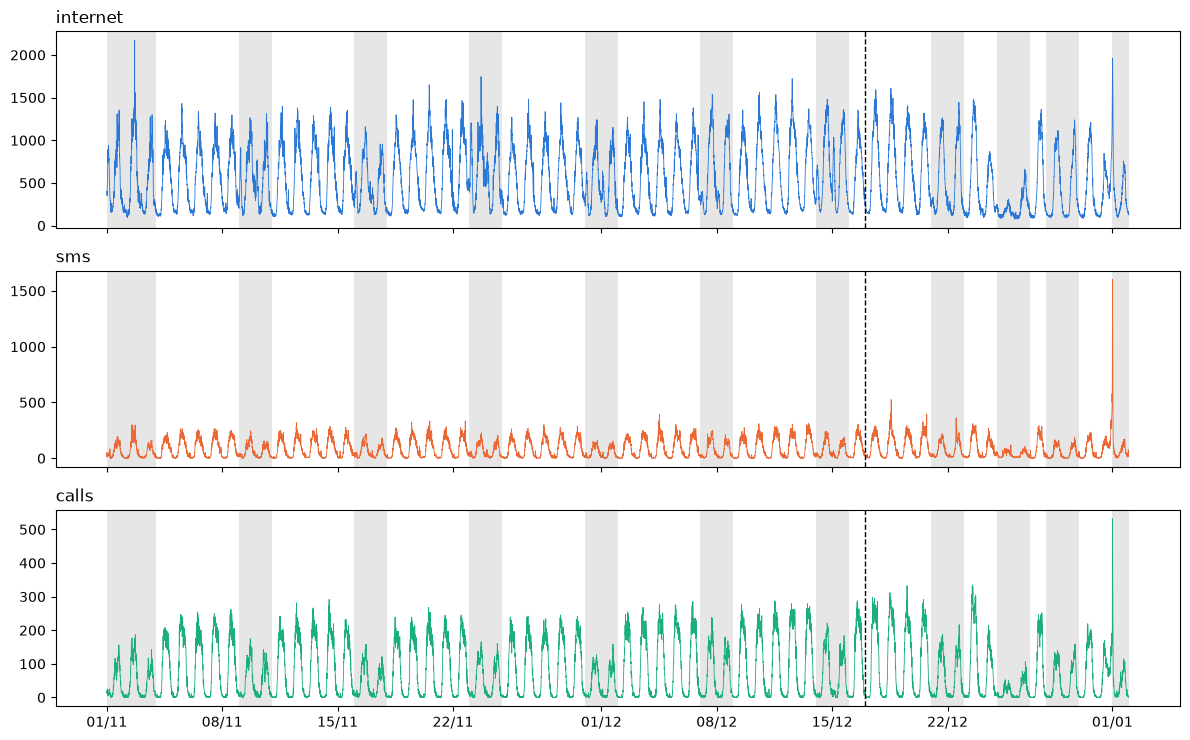

In [6]:
# Full series, weekends/holidays shaded, dashed line = start of test set
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
for ax, s in zip(axes, SERIES):
    ax.plot(df.index, df[s], color=COLOR[s], lw=0.6)
    for d in pd.date_range(df.index[0].normalize(), df.index[-1].normalize(), freq="D"):
        if d.dayofweek >= 5 or d in HOLIDAYS:
            ax.axvspan(d, d + pd.Timedelta("1D"), color="0.9", lw=0)
    ax.axvline(t_split, color="k", ls="--", lw=1)
    ax.set_title(s, loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout(); plt.show()

Μία τυπική εβδομάδα (Δευτέρα 11/11 έως Κυριακή 17/11/2013). Σε αυτή την κλίμακα φαίνεται καθαρά το σχήμα του
ημερήσιου κύκλου και η διαφορά εργάσιμης και Σαββατοκύριακου.

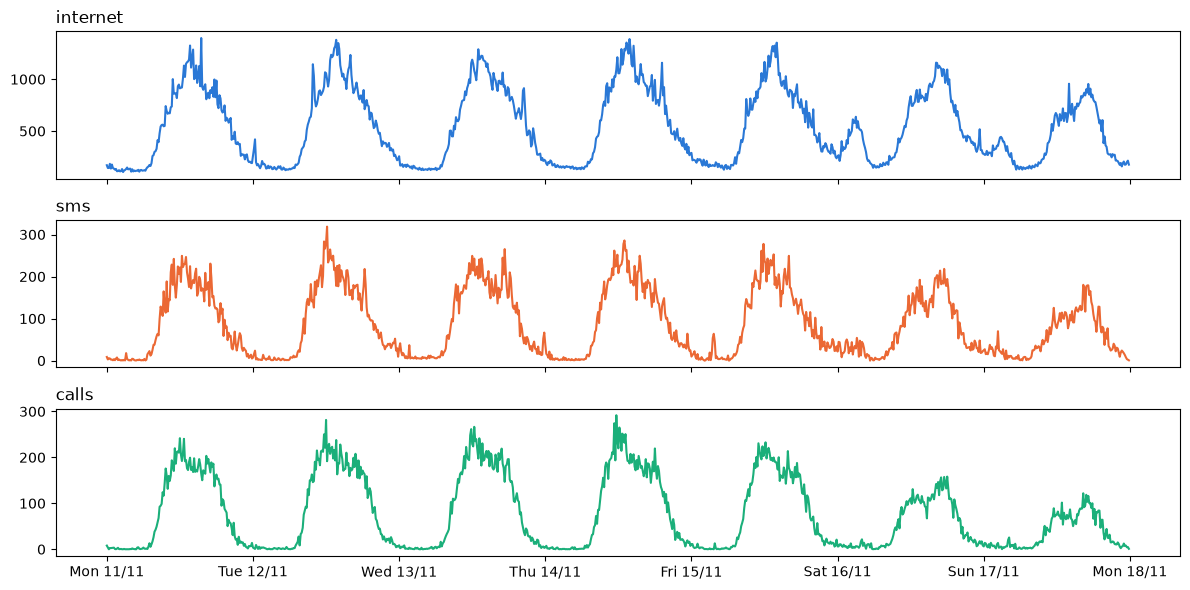

In [7]:
# One typical week
week = df.loc["2013-11-11":"2013-11-17"]
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for ax, s in zip(axes, SERIES):
    ax.plot(week.index, week[s], color=COLOR[s])
    ax.set_title(s, loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d/%m"))
fig.tight_layout(); plt.show()

Μέσο ημερήσιο προφίλ ανά τύπο ημέρας. Για κάθε δεκάλεπτο της ημέρας (slot 0 έως 143) υπολογίζουμε τη μέση τιμή,
χωριστά για εργάσιμες, Σάββατα και Κυριακές ή αργίες. Χρησιμοποιούμε μόνο το train, γιατί αυτά τα προφίλ
καθοδηγούν την επιλογή μοντέλου και δεν πρέπει να «δουν» το test.

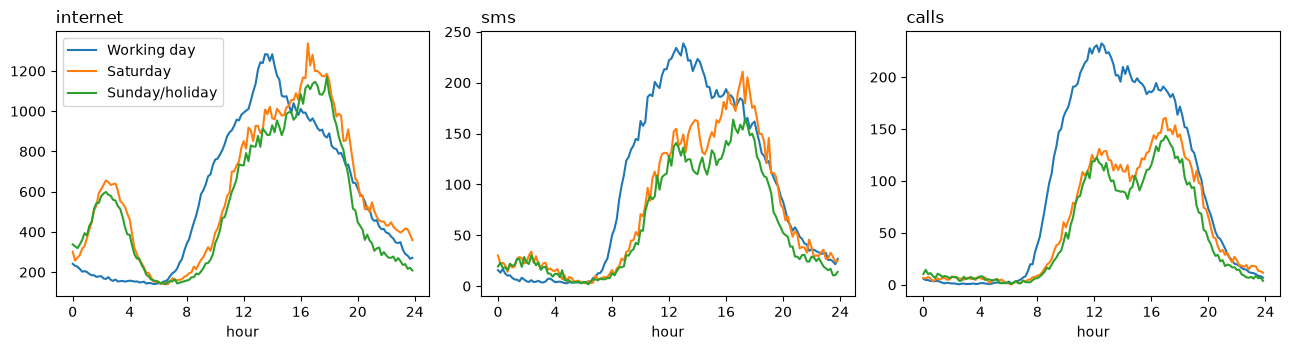

In [8]:
# Mean daily profile per day type (train set only)
tr = train.copy()
tr["slot"] = tr.index.hour * 6 + tr.index.minute // 10
tr["type"] = day_type(tr.index)
names = {0: "Working day", 1: "Saturday", 2: "Sunday/holiday"}
hours = np.arange(SEASON) / 6
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, s in zip(axes, SERIES):
    for k in range(3):
        ax.plot(hours, tr[tr["type"] == k].groupby("slot")[s].mean().values, label=names[k])
    ax.set_title(s, loc="left"); ax.set_xlabel("hour"); ax.set_xticks(range(0, 25, 4))
axes[0].legend()
fig.tight_layout(); plt.show()

Ημερήσια σύνολα. Αθροίζοντας ανά ημέρα εξαφανίζεται ο ημερήσιος κύκλος και μένει ο εβδομαδιαίος ρυθμός και οι
ειδικές ημέρες (γκρι: Σαββατοκύριακα και αργίες).

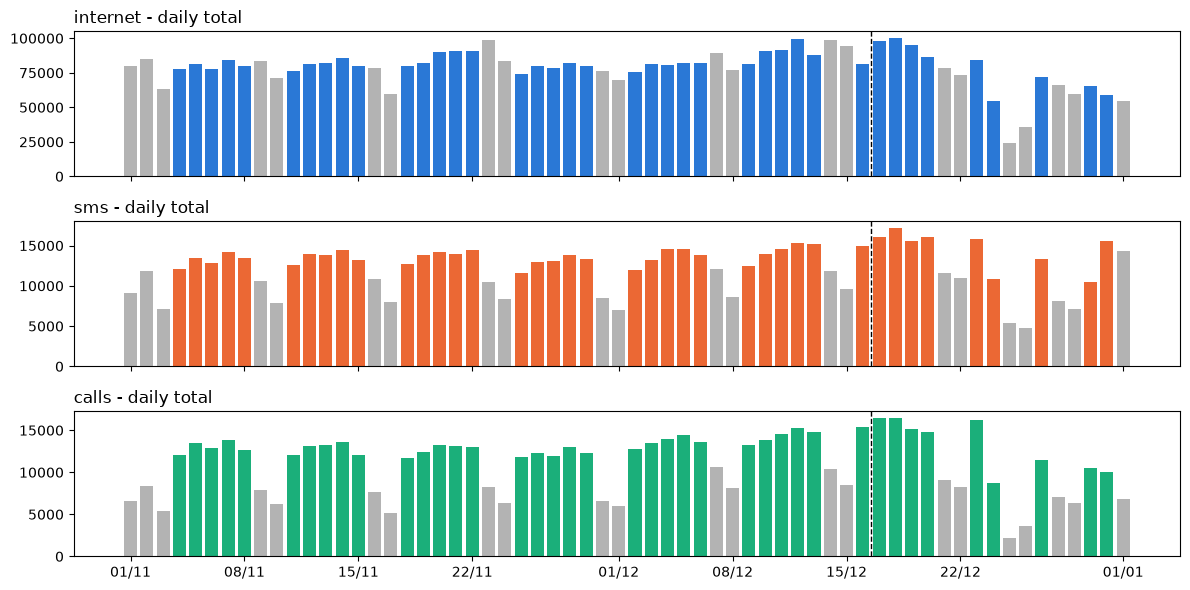

In [9]:
# Daily totals (grey = weekend/holiday)
daily = df.resample("D").sum()
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for ax, s in zip(axes, SERIES):
    c = ["0.7" if (d.dayofweek >= 5 or d in HOLIDAYS) else COLOR[s] for d in daily.index]
    ax.bar(daily.index, daily[s], color=c, width=0.8)
    ax.axvline(t_split - pd.Timedelta("12h"), color="k", ls="--", lw=1)
    ax.set_title(s + " - daily total", loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout(); plt.show()

Περιγραφικά στατιστικά και συσχέτιση. Η συσχέτιση Pearson δείχνει αν οι τρεις σειρές οδηγούνται από τον ίδιο
παράγοντα.

In [10]:
# Summary statistics and correlation between the three series
display(df.describe().T)
df.corr().round(3)

,count,mean,std,min,25%,50%,75%,max
internet,8928.0,547.156496,376.406598,77.226475,193.706089,438.280193,864.318821,2172.038157
sms,8928.0,84.817577,85.815283,0.003122,11.842894,52.158589,149.550749,1602.041699
calls,8928.0,76.645422,82.094554,0.000000,4.497874,36.834428,146.385241,531.921029


,internet,sms,calls
internet,1.000,0.879,0.900
sms,0.879,1.000,0.925
calls,0.900,0.925,1.000


Προέλευση της κίνησης. Ποσοστό της δραστηριότητας από ιταλικές SIM (country code 39), από SIM με άγνωστο code (0)
και από ξένες SIM. Αυτό μας δείχνει πόσο «τουριστικό» είναι το κελί.

In [11]:
# Share of activity from Italian (39), unknown (0) and foreign SIMs
by_cc = raw.groupby("country_code")[act].sum()
foreign = by_cc.drop(index=[0, 39])
pd.DataFrame({"Italy (39) %": 100 * by_cc.loc[39] / by_cc.sum(),
              "unknown (0) %": 100 * by_cc.loc[0] / by_cc.sum(),
              "foreign %": 100 * foreign.sum() / by_cc.sum()}).round(1)

,Italy (39) %,unknown (0) %,foreign %
sms_in,62.2,31.8,6.0
sms_out,91.5,1.8,6.6
call_in,95.2,0.3,4.4
call_out,95.3,0.9,3.9
internet,98.8,0.0,1.2


#### Παρατηρήσεις από την EDA

Και οι τρεις σειρές έχουν ισχυρή ημερήσια περιοδικότητα, γι' αυτό παίρνουμε εποχική περίοδο $s = 144$ (μία ημέρα).
Το ελάχιστο εμφανίζεται περίπου 05:00 έως 07:00 και η κορυφή τις εργάσιμες γύρω στις 12:30 (Calls), 13:00 (SMS) και
13:30 (Internet). Τη νύχτα οι κλήσεις σχεδόν μηδενίζονται, με 200 δεκάλεπτα με Calls $= 0$ στο train και 120 στο
test, ενώ το Internet δεν πέφτει ποτέ κάτω από περίπου 77, λόγω της background κίνησης των smartphones.

Υπάρχει και εβδομαδιαία περιοδικότητα. Τα Σαββατοκύριακα το ημερήσιο σύνολο πέφτει στο 57% (Calls) και στο 70%
(SMS) μιας εργάσιμης. Το Internet μένει περίπου ίδιο (98%) αλλά αλλάζει σχήμα: η κορυφή μετατοπίζεται στο απόγευμα
(16:30 έως 18:00), και τις πρώτες ώρες του Σαββάτου και της Κυριακής (01:00 έως 04:00, δηλαδή οι νύχτες της Παρασκευής και του Σαββάτου) είναι περίπου 3 φορές
υψηλότερο από μια εργάσιμη (558 έναντι 170), λόγω της νυχτερινής ζωής γύρω από το Duomo. Ο τύπος ημέρας χρειάζεται
λοιπόν ως πληροφορία στο μοντέλο, π.χ. ως εξωγενής μεταβλητή.

Δεν φαίνεται τάση, κάτι που θα ελέγξουμε τυπικά στην ενότητα 2.2. Οι τρεις σειρές συσχετίζονται έντονα (Pearson
0.88 έως 0.93), γιατί τις οδηγεί ο ίδιος παράγοντας: πόσοι άνθρωποι βρίσκονται στην περιοχή.

Η εορταστική περίοδος πέφτει μέσα στο test. Σε σχέση με μια μέση εργάσιμη του train, τα Χριστούγεννα (25/12) το
Internet είναι 71% χαμηλότερο, τα SMS 61% και τα Calls 84%, και στις 26/12 56%, 65% και 73% αντίστοιχα. Τα
μεσάνυχτα της Πρωτοχρονιάς εμφανίζεται η μεγαλύτερη αιχμή της σειράς για SMS και Calls: SMS $= 1602$ στις 00:10,
ενώ η συνήθης τιμή αυτής της ώρας είναι περίπου 18 (σχεδόν 90 φορές μεγαλύτερη), και Calls $= 532$ (συνήθως περίπου
7). Το Internet φτάνει το 1964 (συνήθως περίπου 268), που είναι η μεγαλύτερη τιμή του test αλλά όχι όλης της
σειράς: το μέγιστό του είναι 2172, στις 02/11 στις 16:30, δηλαδή μέσα στο train. Οι γιορτές και οι αιχμές των SMS
και Calls δεν υπάρχουν στο train, οπότε το test ελέγχει και την προσαρμογή σε συνθήκες που τα μοντέλα δεν έχουν δει
(*distribution shift*).

Τέλος, οι διακυμάνσεις είναι πολύ μεγαλύτερες τη μέρα από τη νύχτα.

## 2. ARIMA, s-ARIMA, ARIMA-x

### 2.1 Θεωρία

#### 2.1.1 Στασιμότητα: γιατί είναι η βασική προϋπόθεση

Ένα μοντέλο ARIMA εκτιμά σταθερές παραμέτρους από το παρελθόν και τις εφαρμόζει στο μέλλον. Αυτό έχει νόημα μόνο
αν η στατιστική συμπεριφορά της σειράς δεν αλλάζει με τον χρόνο. Αυτή η ιδιότητα λέγεται (ασθενής) στασιμότητα.
Μια σειρά $y_t$ είναι στάσιμη όταν:

$$\mathbb{E}[y_t] = \mu \;\;\text{(σταθερός μέσος)}, \qquad \operatorname{Var}(y_t) = \sigma_y^2 \;\;\text{(σταθερή διασπορά)}, \qquad \operatorname{Cov}(y_t,\, y_{t-k}) = \gamma_k \;\;\text{(εξαρτάται μόνο από το } k\text{)}$$

Αν η σειρά έχει τάση ή «περιπλανιέται» χωρίς να επιστρέφει σε ένα μέσο επίπεδο, τότε ο μέσος όρος που θα μάθει το
μοντέλο από το train δεν θα ισχύει στο test.

Τελεστής υστέρησης. Για να γράφουμε τα μοντέλα σύντομα χρησιμοποιούμε τον τελεστή $B$, που μετακινεί τη σειρά ένα
βήμα πίσω:

$$B\,y_t = y_{t-1}, \qquad B^k y_t = y_{t-k}$$

Με αυτόν ορίζονται η διαφόριση (διαφορά από το προηγούμενο βήμα) και η εποχική διαφόριση (διαφορά από το ίδιο
σημείο της προηγούμενης περιόδου $s$):

$$\nabla y_t = (1 - B)\,y_t = y_t - y_{t-1}, \qquad \nabla_s\, y_t = (1 - B^s)\,y_t = y_t - y_{t-s}$$

Η διαφόριση αφαιρεί μια τάση ή μια «περιπλάνηση» και η εποχική διαφόριση αφαιρεί ένα μοτίβο που επαναλαμβάνεται
κάθε $s$ βήματα. Και οι δύο μετατρέπουν μια μη στάσιμη σειρά σε στάσιμη.

#### 2.1.2 Τα δομικά στοιχεία: AR, MA, ARMA

Σε όλα τα παρακάτω, $\varepsilon_t$ είναι λευκός θόρυβος: ασυσχέτιστες τυχαίες διαταραχές με μέσο 0 και
διασπορά $\sigma^2$. Είναι το «απρόβλεπτο» μέρος κάθε βήματος.

AR(p), αυτοπαλινδρόμηση. Η τρέχουσα τιμή είναι γραμμικός συνδυασμός των $p$ προηγούμενων τιμών:

$$y_t = c + \phi_1 y_{t-1} + \phi_2 y_{t-2} + \dots + \phi_p y_{t-p} + \varepsilon_t
\qquad\Longleftrightarrow\qquad
\phi(B)\,y_t = c + \varepsilon_t, \quad \phi(B) = 1 - \phi_1 B - \dots - \phi_p B^p$$

*Διαίσθηση:* η σειρά «θυμάται» πού βρισκόταν. Αν η κίνηση είναι υψηλή τώρα, θα είναι μάλλον υψηλή και σε 10 λεπτά.

MA(q), κινητός μέσος. Η τρέχουσα τιμή εξαρτάται από τις $q$ προηγούμενες διαταραχές (τα «ξαφνιάσματα»):

$$y_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q}
\qquad\Longleftrightarrow\qquad
y_t = \mu + \theta(B)\,\varepsilon_t, \quad \theta(B) = 1 + \theta_1 B + \dots + \theta_q B^q$$

*Διαίσθηση:* ένα απρόσμενο γεγονός (π.χ. ένα πλήθος που φτάνει ξαφνικά) επηρεάζει τα επόμενα $q$ βήματα και μετά
ξεχνιέται εντελώς.

ARMA(p, q). Συνδυάζει και τα δύο: $\;\phi(B)\,y_t = c + \theta(B)\,\varepsilon_t$.

Γιατί ARMA και όχι μόνο AR. Ένα ARMA χαμηλής τάξης μπορεί να περιγράψει μια μνήμη που θα χρειαζόταν πολύ μεγάλο
AR. Λιγότερες παράμετροι σημαίνουν πιο σταθερή εκτίμηση και μικρότερο κίνδυνο υπερπροσαρμογής.

Δύο τεχνικές συνθήκες. Το AR μέρος πρέπει να είναι στάσιμο (οι ρίζες του $\phi(z) = 0$ έξω από τον μοναδιαίο
κύκλο) ώστε οι διαταραχές να σβήνουν με τον χρόνο, και το MA μέρος πρέπει να είναι αντιστρέψιμο (οι ρίζες του
$\theta(z) = 0$ έξω από τον μοναδιαίο κύκλο) ώστε τα $\varepsilon_t$ να μπορούν να ανακτηθούν από τις παρατηρήσεις.
Η δεύτερη συνθήκη είναι απαραίτητη για την εκτίμηση που χρησιμοποιούμε στην ενότητα 2.4.

#### 2.1.3 ARIMA(p, d, q)

Αν η $y_t$ δεν είναι στάσιμη, τη διαφορίζουμε $d$ φορές και εφαρμόζουμε ARMA στο αποτέλεσμα. Το «I» (*Integrated*)
δηλώνει ακριβώς αυτό:

$$\phi(B)\,(1 - B)^d\, y_t = c + \theta(B)\,\varepsilon_t$$

Οι τρεις υπερπαράμετροι και πώς εκτιμώνται a priori:

| Υπερπαράμετρος | Σημασία | Πώς την εκτιμούμε |
|:---|:---|:---|
| $d$ | πόσες διαφορίσεις χρειάζονται για στασιμότητα | τεστ ADF και KPSS, και η μορφή της ACF (ενότητα 2.2) |
| $p$ | πόσες προηγούμενες τιμές (AR) | η PACF της στάσιμης σειράς (ενότητα 2.3) |
| $q$ | πόσες προηγούμενες διαταραχές (MA) | η ACF της στάσιμης σειράς (ενότητα 2.3) |

Οι γραφικές εκτιμήσεις δίνουν ένα εύρος τιμών. Η τελική επιλογή μέσα σε αυτό το εύρος γίνεται με κριτήριο
πληροφορίας (BIC, ενότητα 2.5).

#### 2.1.4 Seasonal ARIMA: s-ARIMA(p, d, q)(P, D, Q)$_s$

Η EDA έδειξε ότι η σειρά επαναλαμβάνεται κάθε $s = 144$ βήματα (μία ημέρα). Ένα απλό ARIMA θα χρειαζόταν όρους μέχρι
το lag 144 για να το περιγράψει. Το s-ARIMA προσθέτει εποχικά πολυώνυμα στο $B^s$:

$$\phi(B)\,\Phi(B^s)\,(1 - B)^d\,(1 - B^s)^D\, y_t \;=\; c + \theta(B)\,\Theta(B^s)\,\varepsilon_t$$

* $\Phi(B^s) = 1 - \Phi_1 B^s - \dots - \Phi_P B^{Ps}$ και $\Theta(B^s) = 1 + \Theta_1 B^s + \dots + \Theta_Q B^{Qs}$
  συνδέουν την τιμή με τις τιμές και τις διαταραχές της ίδιας ώρας τις προηγούμενες ημέρες.
* $D$ είναι το πλήθος των εποχικών διαφορίσεων. Με $D = 1$ μοντελοποιούμε τη διαφορά
  $\nabla_{144}\, y_t = y_t - y_{t-144}$, δηλαδή «πόσο διαφέρει η κίνηση από χθες την ίδια ώρα». Αυτό αφαιρεί το
  ημερήσιο μοτίβο.
* Το μοντέλο είναι πολλαπλασιαστικό: τα γινόμενα όπως $\theta(B)\,\Theta(B^s)$ δημιουργούν όρους αλληλεπίδρασης
  (π.χ. στο lag $s + 1$) με λίγες μόνο παραμέτρους.
* Τα $P, Q$ διαβάζονται από την ACF/PACF στα πολλαπλάσια της περιόδου: lags 144, 288, 432, ...

#### 2.1.5 ARIMA-x: ARIMA με εξωγενείς μεταβλητές

Εδώ η σειρά γράφεται ως παλινδρόμηση σε γνωστές μεταβλητές $x_t$, με σφάλματα που ακολουθούν ARIMA:

$$y_t = c + \beta^\top x_t + u_t, \qquad u_t \sim \text{ARIMA}(p, d, q)$$

Το $\beta^\top x_t$ περιγράφει το προβλέψιμο, ντετερμινιστικό μέρος (π.χ. το ημερήσιο σχήμα) και το ARIMA περιγράφει
ό,τι μένει. Ως $x_t$ χρησιμοποιούμε δείκτες περιοδικότητας, που έχουν ένα κρίσιμο πλεονέκτημα: είναι γνωστοί
εκ των προτέρων για κάθε μελλοντική στιγμή (ξέρουμε τι ώρα και τι μέρα θα είναι), άρα δεν χρειάζεται να τους
προβλέψουμε.

Όροι Fourier. Κάθε περιοδική συνάρτηση με περίοδο $m$ γράφεται ως άθροισμα ημιτόνων και συνημιτόνων:

$$\sum_{k=1}^{K} \Big[\, a_k \sin\!\Big(\frac{2\pi k\, \tau_t}{m}\Big) + b_k \cos\!\Big(\frac{2\pi k\, \tau_t}{m}\Big) \Big]$$

όπου $\tau_t$ η θέση του $t$ μέσα στην περίοδο. Χρησιμοποιούμε $m = 144$ (ημερήσιος κύκλος) και $m = 1008$
(εβδομαδιαίος κύκλος, $7 \times 144$). Το $K$ ελέγχει πόσο λεπτομερές είναι το σχήμα: μικρό $K$ δίνει ομαλή καμπύλη.

Γιατί Fourier και όχι μόνο s-ARIMA. Ένα s-ARIMA με $s = 1008$ για τον εβδομαδιαίο κύκλο θα ήταν πρακτικά αδύνατο
να εκτιμηθεί (πολυώνυμα βαθμού πάνω από 1000). Οι όροι Fourier περιγράφουν την ίδια περιοδικότητα με λίγες
παραμέτρους ($2K$ ανά περίοδο). Επιπλέον, με έναν δείκτη μη εργάσιμης ημέρας μπορούμε να πούμε στο μοντέλο ότι η
Κυριακή έχει διαφορετικό σχήμα από τη Δευτέρα, κάτι που το s-ARIMA δεν μπορεί να κάνει.

### 2.2 Έλεγχοι στασιμότητας (ADF, KPSS): εκτίμηση του $d$ (και του $D$)

#### Μοναδιαία ρίζα

Η πιο συνηθισμένη μορφή μη στασιμότητας φαίνεται στο απλό μοντέλο

$$y_t = \rho\, y_{t-1} + \varepsilon_t$$

* Αν $|\rho| < 1$, κάθε διαταραχή σβήνει σταδιακά και η σειρά επιστρέφει στον μέσο της: στάσιμη.
* Αν $\rho = 1$, κάθε διαταραχή μένει για πάντα και η σειρά περιπλανιέται (*random walk*): μη στάσιμη. Αυτό
  λέγεται μοναδιαία ρίζα και διορθώνεται με μία διαφόριση, αφού τότε $\nabla y_t = \varepsilon_t$.

Άρα το ερώτημα «χρειάζεται διαφόριση;» είναι ισοδύναμο με το «έχει η σειρά μοναδιαία ρίζα;».

#### ADF (Augmented Dickey-Fuller)

Εκτιμά την παλινδρόμηση

$$\nabla y_t = \alpha + \gamma\, y_{t-1} + \sum_{i=1}^{\ell} \delta_i\, \nabla y_{t-i} + \varepsilon_t$$

όπου $\gamma = \rho - 1$. Οι όροι $\nabla y_{t-i}$ (το «augmented») απορροφούν τη βραχυπρόθεσμη αυτοσυσχέτιση, ώστε το
τεστ να είναι έγκυρο και όταν η σειρά δεν είναι απλό AR(1). Το πλήθος τους $\ell$ επιλέγεται με AIC.

* H0: $\gamma = 0$, δηλαδή υπάρχει μοναδιαία ρίζα (μη στάσιμη).
* $p < 0.05$: απορρίπτουμε την H0, άρα η σειρά είναι στάσιμη.

#### KPSS (Kwiatkowski-Phillips-Schmidt-Shin)

Γράφει τη σειρά ως άθροισμα ενός random walk και ενός στάσιμου μέρους:

$$y_t = r_t + \eta_t, \qquad r_t = r_{t-1} + v_t, \quad \operatorname{Var}(v_t) = \sigma_v^2$$

* H0: $\sigma_v^2 = 0$, δηλαδή το random walk είναι σταθερό και η σειρά είναι στάσιμη.
* $p < 0.05$: απορρίπτουμε την H0, άρα η σειρά είναι μη στάσιμη.

#### Γιατί χρειαζόμαστε και τα δύο

Ένα τεστ υποθέσεων μπορεί μόνο να απορρίψει την H0, ποτέ να την αποδείξει. Το ADF μάλιστα έχει μικρή ισχύ: συχνά
δεν απορρίπτει ακόμη και όταν η σειρά είναι στάσιμη. Τα δύο τεστ έχουν αντίθετες μηδενικές υποθέσεις, οπότε όταν
συμφωνούν το συμπέρασμα είναι αξιόπιστο:

| ADF $p$ | KPSS $p$ | Συμπέρασμα |
|:---:|:---:|:---|
| $< 0.05$ | $> 0.05$ | στάσιμη (συμφωνούν) |
| $> 0.05$ | $< 0.05$ | μη στάσιμη (συμφωνούν), χρειάζεται διαφόριση |
| $< 0.05$ | $< 0.05$ | αντικρουόμενα (συχνά στάσιμη γύρω από τάση) |
| $> 0.05$ | $> 0.05$ | ανεπαρκή στοιχεία |

#### Τι ελέγχουμε

Εφαρμόζουμε τα τεστ στην $y_t$, στην $\nabla y_t$, στην $\nabla_{144}\, y_t$ και στην $\nabla \nabla_{144}\, y_t$. Η
απλούστερη μορφή που βγαίνει στάσιμη δίνει τα $d$ και $D$. Τα τεστ γίνονται μόνο στο train set, ώστε η
επιλογή του μοντέλου να μη «βλέπει» το test.

*Τεχνική σημείωση:* το `statsmodels` δίνει p-values για το KPSS μόνο στο διάστημα $[0.01,\, 0.1]$ (από πίνακα κρίσιμων
τιμών). Μια τιμή 0.1 σημαίνει «0.1 ή μεγαλύτερη».

In [12]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

Y = {s: df[s].values.astype(float) for s in SERIES}

def stationarity_table(y):
    ys = pd.Series(y)
    rows = []
    for name, z in {"y": ys, "d1(y)": ys.diff(), "d144(y)": ys.diff(SEASON),
                    "d1(d144(y))": ys.diff(SEASON).diff()}.items():
        z = z.dropna().values
        with warnings.catch_warnings():         # FutureWarnings + KPSS p-value outside the lookup table
            warnings.simplefilter("ignore")
            adf_stat, adf_p, *_ = adfuller(z, autolag="AIC")
            kpss_stat, kpss_p, *_ = kpss(z, regression="c", nlags="auto")
        rows.append({"series": name, "ADF stat": adf_stat, "ADF p": adf_p,
                     "KPSS stat": kpss_stat, "KPSS p": kpss_p,
                     "conclusion": "stationary" if (adf_p < 0.05 and kpss_p > 0.05) else
                                   ("ambiguous" if (adf_p < 0.05) == (kpss_p < 0.05) else "non-stationary")})
    return pd.DataFrame(rows)


for s in SERIES:
    print(f"\n=== {s} ===  (KPSS p-values are bounded to [0.01, 0.1])")
    display(stationarity_table(Y[s][:n_train]))


=== internet ===  (KPSS p-values are bounded to [0.01, 0.1])


,series,ADF stat,ADF p,KPSS stat,KPSS p,conclusion
0,y,-16.988509,8.904673e-30,0.111048,0.1,stationary
1,d1(y),-13.407905,4.432758e-25,0.003744,0.1,stationary
2,d144(y),-12.733859,9.250838e-24,0.017651,0.1,stationary
3,d1(d144(y)),-16.435145,2.457400e-29,0.003739,0.1,stationary



=== sms ===  (KPSS p-values are bounded to [0.01, 0.1])


,series,ADF stat,ADF p,KPSS stat,KPSS p,conclusion
0,y,-16.220950,3.898405e-29,0.053198,0.1,stationary
1,d1(y),-14.287563,1.292081e-26,0.007418,0.1,stationary
2,d144(y),-9.587682,2.076050e-16,0.029130,0.1,stationary
3,d1(d144(y)),-27.418437,0.000000e+00,0.041643,0.1,stationary



=== calls ===  (KPSS p-values are bounded to [0.01, 0.1])


,series,ADF stat,ADF p,KPSS stat,KPSS p,conclusion
0,y,-16.927188,9.838981e-30,0.139151,0.1,stationary
1,d1(y),-11.247188,1.747800e-20,0.004341,0.1,stationary
2,d144(y),-9.877710,3.842883e-17,0.036924,0.1,stationary
3,d1(d144(y)),-16.912415,1.008316e-29,0.008494,0.1,stationary


#### Ερμηνεία των τεστ στασιμότητας

Και στις τρεις σειρές το ADF δίνει $p < 10^{-28}$ στην $y_t$, δηλαδή απορρίπτει έντονα τη μοναδιαία ρίζα, και το
στατιστικό KPSS είναι 0.05 έως 0.14, πολύ κάτω από την κρίσιμη τιμή 0.463 του 5%. Τα δύο τεστ συμφωνούν ότι η σειρά
είναι στάσιμη, άρα $d = 0$, όπως έδειξε και η EDA.

Οι διαφορισμένες μορφές βγαίνουν επίσης στάσιμες, αλλά αυτό δεν σημαίνει ότι η διαφόριση χρειάζεται: μια ήδη
στάσιμη σειρά μένει στάσιμη αν τη διαφορίσουμε, με περιττή πολυπλοκότητα (υπερ-διαφόριση, που δημιουργεί ένα μη
αντιστρέψιμο MA). Κρατάμε τη μικρότερη διαφόριση που αρκεί.

Τα ADF και KPSS ελέγχουν μοναδιαία ρίζα στη «μηδενική συχνότητα», δηλαδή μια μακροπρόθεσμη τάση ή περιπλάνηση, και
είναι τυφλά στην εποχικότητα: μια σειρά που ανεβαίνει και κατεβαίνει κανονικά κάθε μέρα βγαίνει στάσιμη για αυτά.
Το αν χρειάζεται εποχική διαφόριση ($D$) θα το κρίνουμε από την ACF στην επόμενη ενότητα.

### 2.3 Γραφήματα ACF / PACF: εκτίμηση των $p, q$ (και $P, Q$)

#### Ορισμοί

ACF (συνάρτηση αυτοσυσχέτισης). Η συσχέτιση της σειράς με τον εαυτό της μετατοπισμένη κατά $k$ βήματα:

$$r_k \;=\; \frac{\displaystyle\sum_{t=k+1}^{n} (y_t - \bar y)(y_{t-k} - \bar y)}{\displaystyle\sum_{t=1}^{n} (y_t - \bar y)^2}$$

Για παράδειγμα, το $r_{144}$ απαντά στο «πόσο μοιάζει η κίνηση τώρα με την κίνηση χθες την ίδια ώρα;».

PACF (μερική αυτοσυσχέτιση). Η συσχέτιση της $y_t$ με την $y_{t-k}$ αφού αφαιρεθεί η επίδραση των ενδιάμεσων
lags $1, \dots, k-1$. Τυπικά, είναι ο τελευταίος συντελεστής $\phi_{kk}$ όταν εκτιμάμε ένα AR($k$):

$$y_t = \phi_{k1}\, y_{t-1} + \dots + \phi_{kk}\, y_{t-k} + e_t$$

*Γιατί χρειάζεται:* αν το $y_{t-1}$ επηρεάζει το $y_t$ και το $y_{t-2}$ επηρεάζει το $y_{t-1}$, τότε το $y_{t-2}$ θα
φαίνεται συσχετισμένο με το $y_t$ ακόμη κι αν δεν έχει άμεση επίδραση. Η ACF μετράει και αυτή την έμμεση σύνδεση, η
PACF κρατά μόνο την άμεση.

Ζώνη εμπιστοσύνης. Αν η σειρά ήταν λευκός θόρυβος, κάθε $r_k$ θα ήταν περίπου κανονικό με μέσο 0 και διασπορά
$1/n$, δηλαδή τυπική απόκλιση $1/\sqrt{n}$. Μια κανονική μεταβλητή απέχει έως 1.96 τυπικές αποκλίσεις από τον μέσο
της με πιθανότητα 95%. Άρα για λευκό θόρυβο περίπου το 95% των $r_k$ πέφτει μέσα στη ζώνη $\pm 1.96/\sqrt{n}$ (εδώ
περίπου $\pm 0.024$), και τιμές μέσα σε αυτήν δεν διακρίνονται στατιστικά από το μηδέν.

Αυτή είναι η ζώνη στα γραφήματα της PACF. Στα γραφήματα της ACF το `statsmodels` σχεδιάζει τη ζώνη του Bartlett,
που είναι φαρδύτερη και μεγαλώνει με το lag, γιατί λαμβάνει υπόψη τις προηγούμενες αυτοσυσχετίσεις. Στους πίνακες
της ερμηνείας χρησιμοποιούμε τη ζώνη $\pm 0.024$.

#### Κανόνες ανάγνωσης (Box-Jenkins)

| Τι βλέπουμε | Τι σημαίνει |
|:---|:---|
| ACF φθίνει πολύ αργά, σχεδόν γραμμικά | μη στασιμότητα, χρειάζεται διαφόριση |
| ACF με κορυφές στα $s, 2s, 3s, \dots$ που φθίνουν αργά | ισχυρή εποχικότητα, χρειάζεται $D = 1$ |
| PACF μηδενίζεται απότομα μετά το lag $p$, ACF φθίνει σταδιακά | AR($p$) |
| ACF μηδενίζεται απότομα μετά το lag $q$, PACF φθίνει σταδιακά | MA($q$) |
| και οι δύο φθίνουν σταδιακά | μικτό ARMA, μικρά $p, q$ και επιβεβαίωση με BIC |
| αρνητική ακίδα στο lag $s$ της ACF (μετά από $\nabla_s$) | εποχικό MA(1), δηλαδή $Q = 1$ |
| ACF στο lag 1 κοντά στο $-0.5$ μετά από διαφόριση | υπερ-διαφόριση |

#### Τι δείχνει κάθε γράφημα, και γιατί

Για κάθε σειρά σχεδιάζουμε τέσσερα πάνελ (μόνο στο train):
1. ACF της $y$ ως 3 ημέρες: υπάρχει εποχικότητα; (κορυφές στα 144, 288, 432)
2. ACF της $\nabla_{144}\, y$ ως 2 ημέρες: έφυγε η εποχικότητα μετά την εποχική διαφόριση; τι γίνεται στο lag 144;
3. ACF και 4. PACF της $\nabla_{144}\, y$ για lags 0 έως 36: η βραχυπρόθεσμη δομή, από την οποία διαβάζουμε
   τα $p$ και $q$.

Διαβάζουμε τα $p, q$ από την $\nabla_{144}\, y$ και όχι από την $y$, γιατί στην $y$ το ισχυρό ημερήσιο μοτίβο κυριαρχεί
στην ACF και κρύβει τη βραχυπρόθεσμη δομή. Το τελευταίο γράφημα δείχνει την ACF/PACF της $\nabla y$, για το καθαρό
(μη εποχικό) ARIMA.

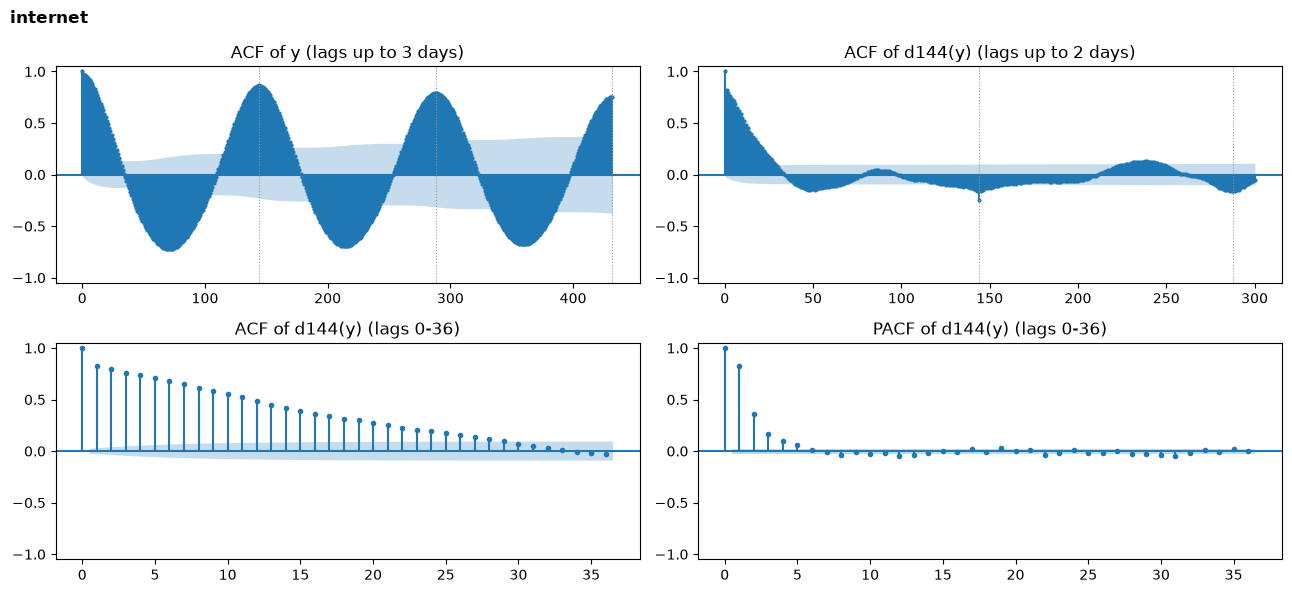

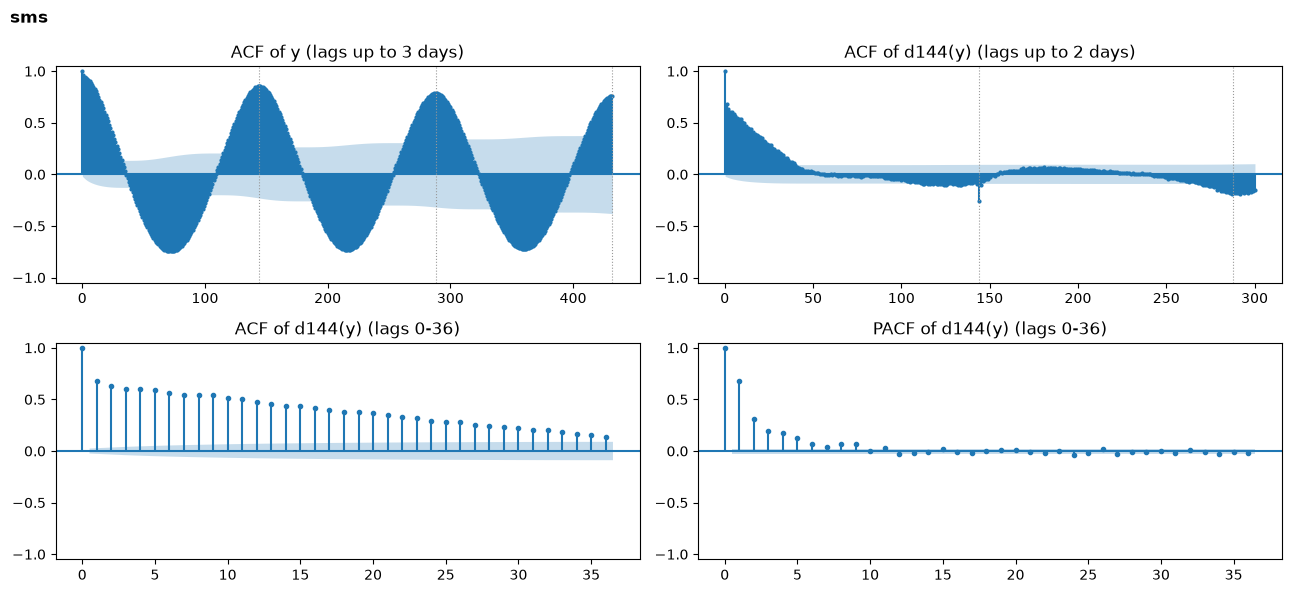

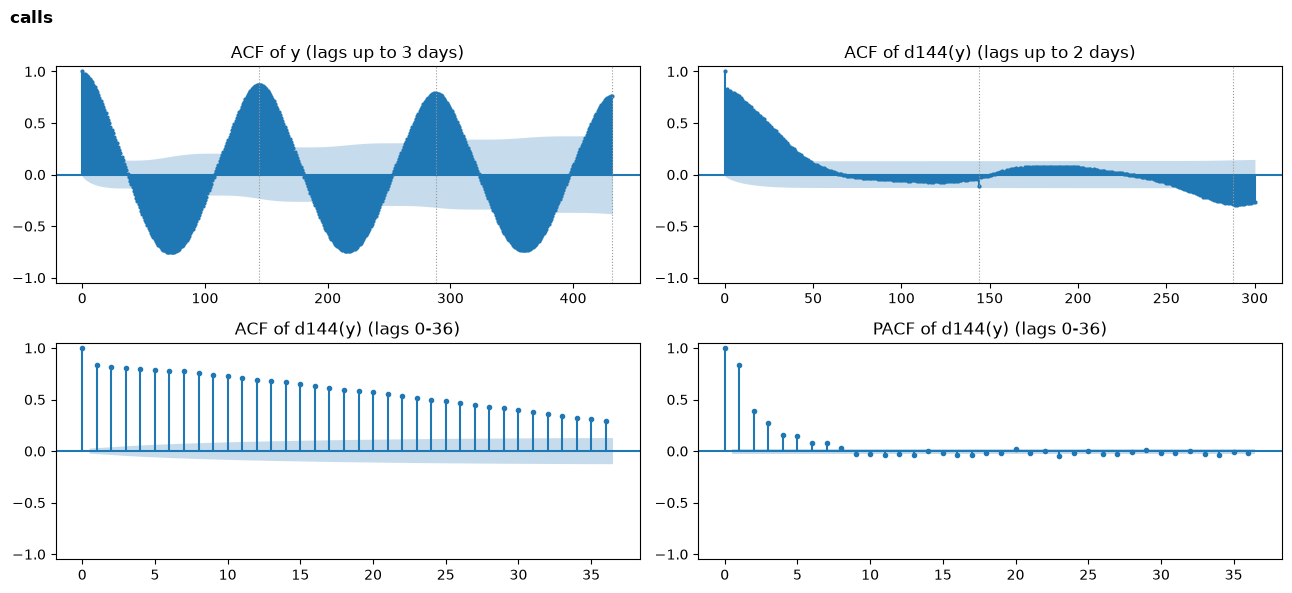

In [13]:
# y: daily seasonality? d144(y): what is left after removing it (p, q, P, Q)
for s in SERIES:
    y = pd.Series(Y[s][:n_train])
    ds = y.diff(SEASON).dropna()
    fig, axes = plt.subplots(2, 2, figsize=(13, 6))
    plot_acf(y, lags=3 * SEASON, ax=axes[0, 0], markersize=2, title="ACF of y (lags up to 3 days)")
    plot_acf(ds, lags=2 * SEASON + 12, ax=axes[0, 1], markersize=2, title="ACF of d144(y) (lags up to 2 days)")
    plot_acf(ds, lags=36, ax=axes[1, 0], markersize=3, title="ACF of d144(y) (lags 0-36)")
    plot_pacf(ds, lags=36, ax=axes[1, 1], markersize=3, method="ywm", title="PACF of d144(y) (lags 0-36)")
    for ax in axes.flat:
        ax.set_ylim(-1.05, 1.05)
    for ax in axes[0]:
        for k in range(SEASON, int(ax.get_xlim()[1]), SEASON):
            ax.axvline(k, color="0.6", ls=":", lw=0.8)
    fig.suptitle(s, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

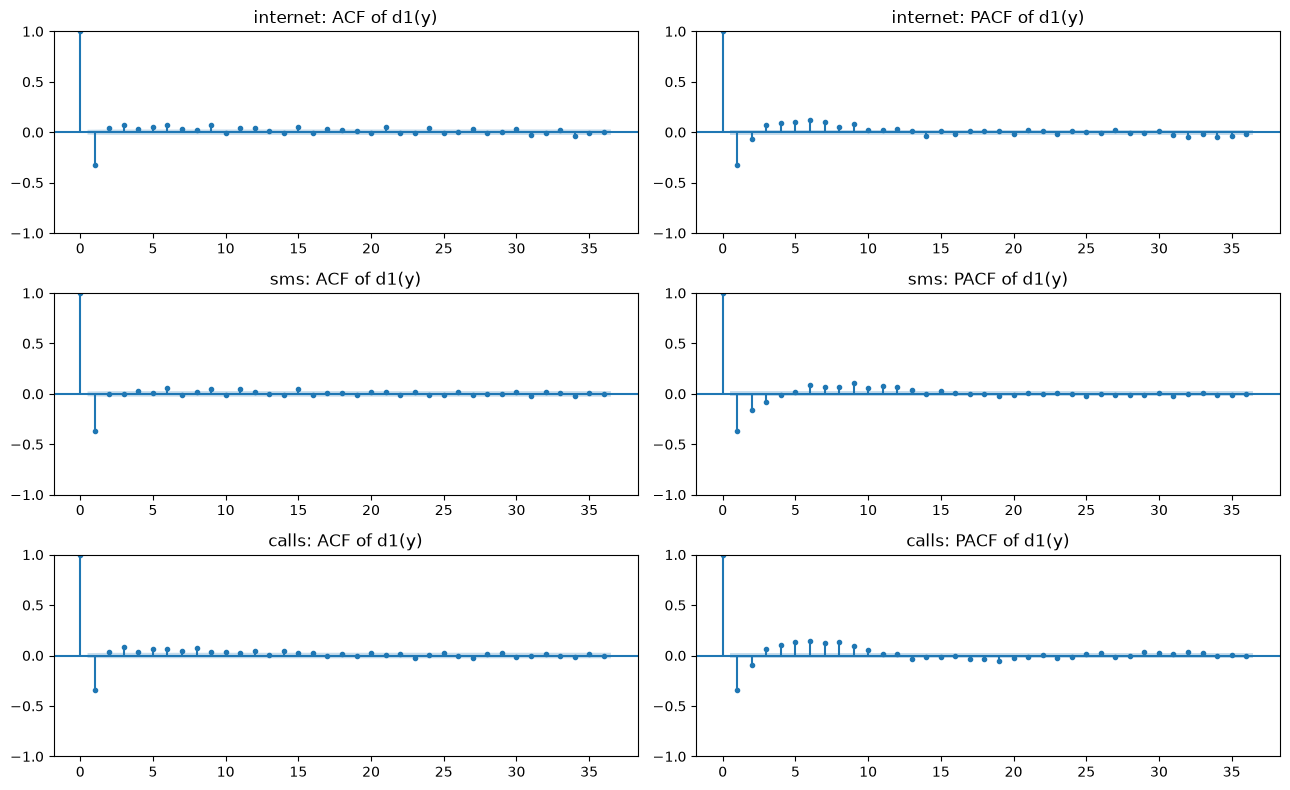

In [14]:
# ACF/PACF of the first difference d1(y) (for the plain, non-seasonal ARIMA)
fig, axes = plt.subplots(len(SERIES), 2, figsize=(13, 8))
for i, s in enumerate(SERIES):
    d1 = pd.Series(Y[s][:n_train]).diff().dropna()
    plot_acf(d1, lags=36, ax=axes[i, 0], markersize=3, title=f"{s}: ACF of d1(y)")
    plot_pacf(d1, lags=36, ax=axes[i, 1], markersize=3, method="ywm", title=f"{s}: PACF of d1(y)")
fig.tight_layout(); plt.show()

#### Ερμηνεία των ACF / PACF

| | Internet | SMS | Calls |
|:---|:---:|:---:|:---:|
| ACF της $y$ στα lags 144, 288, 432 | 0.87, 0.79, 0.75 | 0.86, 0.79, 0.76 | 0.87, 0.79, 0.76 |
| ACF της $\nabla_{144} y$: πρώτο lag μέσα στη ζώνη $\pm 0.024$ | 33 | 50 | 62 |
| ACF της $\nabla_{144} y$ στο lag 144 | $-0.25$ | $-0.25$ | $-0.11$ |
| PACF της $\nabla_{144} y$, lags 1 έως 4 | 0.82, 0.36, 0.16, 0.10 | 0.68, 0.31, 0.20, 0.17 | 0.83, 0.39, 0.27, 0.16 |
| ACF της $\nabla y$ στο lag 1 | $-0.33$ | $-0.37$ | $-0.35$ |

Η ACF της $y$ έχει ημιτονοειδή μορφή, με κορυφές στα 144, 288, 432 που σχεδόν δεν μειώνονται (από 0.87 σε 0.75 μέσα
σε τρεις ημέρες). Το ημερήσιο μοτίβο είναι σχεδόν ντετερμινιστικό και ένα ARMA χαμηλής τάξης δεν μπορεί να το
περιγράψει, οπότε χρειάζεται εποχική διαφόριση, $D = 1$ με $s = 144$, ή εναλλακτικά όροι Fourier, όπως στο ARIMA-x.

Η ACF της $\nabla_{144}\, y$ φθίνει ομαλά και μπαίνει στη ζώνη μετά από 33 έως 62 lags. Η σειρά είναι πλέον
στάσιμη, άρα δεν χρειάζεται επιπλέον $d$. Στο lag 144 εμφανίζεται αρνητική ακίδα, η τυπική υπογραφή ενός εποχικού
MA(1), άρα $Q = 1$. (Η εποχική διαφόριση «υπερ-διορθώνει» λίγο, και ο όρος $\Theta_1 B^{144}$ το αντισταθμίζει.) Η
ακίδα είναι πιο αδύναμη στα Calls.

Η PACF της $\nabla_{144}\, y$ έχει σημαντικές τιμές στα πρώτα 4 έως 6 lags και μετά πρακτικά μηδέν, ενώ η ACF
φθίνει σταδιακά. Αυτή είναι η εικόνα ενός AR($p$) με $p \approx 3$ έως $6$ και $q = 0$.

Η ACF της $\nabla y$ έχει μία αρνητική ακίδα (περίπου $-0.35$) στο lag 1 και μετά σχεδόν μηδέν, με PACF που φθίνει,
δηλαδή το αποτύπωμα ενός MA(1). Η τιμή απέχει από το $-0.5$ της υπερ-διαφόρισης, αλλά αφού τα ADF/KPSS έδειξαν ότι
η $y$ είναι ήδη στάσιμη, κρατάμε $d = 0$.

### 2.4 Εκτίμηση των παραμέτρων

Οι τάξεις ορίζουν τη μορφή του μοντέλου. Μένει να βρούμε τις τιμές των $\phi, \theta, \Theta$ (και των $\beta$ στο
ARIMA-x). Χρησιμοποιούμε το `SARIMAX` του `statsmodels`, που τις εκτιμά με μέγιστη πιθανοφάνεια (MLE): διαλέγει
τις παραμέτρους με τις οποίες τα δεδομένα που παρατηρήσαμε είναι πιο πιθανά. Με κανονικά σφάλματα αυτό είναι
περίπου το ίδιο με το να ελαχιστοποιούμε το $\sum_t \varepsilon_t^2$, δηλαδή τα σφάλματα πρόβλεψης ενός βήματος στο
train.

Το `SARIMAX` γράφει το μοντέλο σε μορφή state-space: ένα διάνυσμα κατάστασης $a_t$ κρατά ό,τι χρειάζεται από το
παρελθόν, και το Kalman filter το ενημερώνει με κάθε νέα τιμή:

$$\hat z_t = Z\,a_t, \qquad a_{t+1} = T\,a_t + K_t\,(z_t - \hat z_t)$$

όπου $z_t$ η σειρά που μοντελοποιούμε. Οι πίνακες $Z, T$ προκύπτουν από τις παραμέτρους. Την ίδια μορφή
χρησιμοποιούμε και για την πρόβλεψη στην ενότητα 2.7.

Με `simple_differencing=True` η εποχική διαφόριση γίνεται πριν από την εκτίμηση, οπότε η κατάσταση μικραίνει από
290 σε περίπου 146 διαστάσεις και χάνονται μόνο οι πρώτες 144 τιμές. Παρ' όλα αυτά κάθε fit του SARIMA κράτησε κατά
μέσο όρο περίπου 22 λεπτά, ενώ του ARIMA-x, που έχει πολύ μικρότερη κατάσταση, περίπου 11 δευτερόλεπτα. Γι' αυτό τα
αποτελέσματα αποθηκεύονται στο `results/arima_grid` και το κελί ξανατρέχει άμεσα.

### 2.5 Επιλογή τάξεων: a priori ανάγνωση και επιβεβαίωση με BIC

Η καθαρή ARIMA δεν μπορεί να περιγράψει το ημερήσιο μοτίβο που έδειξε η ACF, όπως προβλέπει και η εκφώνηση, οπότε
εξετάζουμε τις δύο μορφές που το περιλαμβάνουν. Από τις ενότητες 2.2 και 2.3 προκύπτουν τα εξής εύρη:

| Μοντέλο | $d$ | $D$ | $Q$ | $p$ | $q$ | Τεκμηρίωση |
|:---|:---:|:---:|:---:|:---:|:---:|:---|
| SARIMA | 0 | 1 | 1 | 3 έως 6 | 0 | Κορυφές της ACF στα 144, 288, 432 που φθίνουν αργά: $D = 1$. Αρνητική ακίδα της ACF της $\nabla_{144} y$ στο 144: $Q = 1$. Η PACF κόβεται μετά από 4 έως 6 lags: AR($p$). |
| ARIMA-x | 0 | 0 | 0 | 1 έως 2 | 1 | Οι όροι Fourier αφαιρούν την περιοδικότητα και μένει μόνο βραχυπρόθεσμη αυτοσυσχέτιση. |

Οι εξωτερικές μεταβλητές $x_t$ του ARIMA-x είναι:

* ημερήσιοι όροι Fourier ($K = 4$, περίοδος 144), για το σχήμα της ημέρας,
* εβδομαδιαίοι όροι Fourier ($K = 2$, περίοδος 1008), για τις διαφορές ανάμεσα στις ημέρες,
* ο δείκτης `offday`: 1 για Κυριακή ή αργία, 0.5 για Σάββατο, 0 για εργάσιμη,
* τα γινόμενα του `offday` με τους 2 πρώτους ημερήσιους όρους, ώστε τις μη εργάσιμες να αλλάζει το σχήμα της ημέρας
  και όχι μόνο το επίπεδο.

Τα ACF/PACF δίνουν ένα εύρος και όχι μία τιμή, οπότε η τελική τάξη επιλέγεται με το BIC στο train:

$$\text{BIC} = -2 \ln L + k \ln n$$

Το $L$ είναι η πιθανοφάνεια και το $k$ το πλήθος των παραμέτρων. Μικρότερο BIC σημαίνει καλύτερη ισορροπία ανάμεσα
στην προσαρμογή και στην πολυπλοκότητα. Δοκιμάζουμε ένα μικρό πλέγμα γύρω από τα a priori εύρη:
$p \in \{2, 4, 6\}$, $q \in \{0, 1\}$ για το SARIMA και $p \in \{1, 2, 4\}$, $q \in \{0, 1\}$ για το ARIMA-x,
δηλαδή 6 fits ανά μοντέλο και σειρά.

In [15]:
WEEK = 7 * SEASON                              # 1008 ten-minute steps


def exog_matrix(idx, k_day=4, k_week=2, k_off=2):
    """Periodicity regressors for ARIMA-x, all known in advance for any future time."""
    slot = (idx.hour * 6 + idx.minute // 10).values
    wpos = idx.dayofweek.values * SEASON + slot
    dt = day_type(idx)
    off = (dt == 2).astype(float) + 0.5 * (dt == 1)   # Sunday/holiday = 1, Saturday = 0.5
    cols = {"const": np.ones(len(idx)), "offday": off}
    for k in range(1, k_day + 1):
        sd, cd = np.sin(2 * np.pi * k * slot / SEASON), np.cos(2 * np.pi * k * slot / SEASON)
        cols[f"d_sin{k}"], cols[f"d_cos{k}"] = sd, cd
        if k <= k_off:
            cols[f"off_sin{k}"], cols[f"off_cos{k}"] = off * sd, off * cd
    for k in range(1, k_week + 1):
        cols[f"w_sin{k}"] = np.sin(2 * np.pi * k * wpos / WEEK)
        cols[f"w_cos{k}"] = np.cos(2 * np.pi * k * wpos / WEEK)
    return pd.DataFrame(cols, index=idx)


X_EXOG = exog_matrix(df.index).values
print("ARIMA-x inputs:", list(exog_matrix(df.index).columns))

ARIMA-x inputs: ['const', 'offday', 'd_sin1', 'd_cos1', 'off_sin1', 'off_cos1', 'd_sin2', 'd_cos2', 'off_sin2', 'off_cos2', 'd_sin3', 'd_cos3', 'd_sin4', 'd_cos4', 'w_sin1', 'w_cos1', 'w_sin2', 'w_cos2']


In [16]:
import glob, json, os, time
from joblib import Parallel, delayed
from statsmodels.tsa.statespace.sarimax import SARIMAX

GRID_DIR = "results/arima_grid"                # one JSON per fit: rerunning continues where it stopped
RETRAIN_ARIMA = False
FAMILIES = {"SARIMA": (None, (2, 4, 6), (0, 1)),    # name: (inputs, p values, q values)
            "ARIMA-x": (X_EXOG, (1, 2, 4), (0, 1))}


def make_model(y, family, p, q, X=None):
    if family == "SARIMA":
        return SARIMAX(y, order=(p, 0, q), seasonal_order=(0, 1, 1, SEASON), simple_differencing=True)
    return SARIMAX(y, exog=X, order=(p, 0, q))


def fit_one(s, family, p, q):
    path = f"{GRID_DIR}/{s}_{family}_{p}_{q}.json"
    if os.path.exists(path) and not RETRAIN_ARIMA:
        return
    warnings.filterwarnings("ignore")
    X = FAMILIES[family][0]
    t0 = time.perf_counter()
    r = make_model(Y[s][:n_train], family, p, q, None if X is None else X[:n_train]).fit(
        disp=False, maxiter=60 if family == "SARIMA" else 300, cov_type="none")
    with open(path, "w") as f:
        json.dump({"series": s, "model": family, "p": p, "q": q, "BIC": float(r.bic), "params": list(map(float, r.params)),
                   "names": list(r.param_names), "converged": bool(r.mle_retvals.get("converged")),
                   "iterations": int(r.mle_retvals.get("iterations", -1)), "fit_seconds": time.perf_counter() - t0}, f)


os.makedirs(GRID_DIR, exist_ok=True)
jobs = [(s, fam, p, q) for s in SERIES for fam, (_, ps, qs) in FAMILIES.items() for p in ps for q in qs]
Parallel(n_jobs=12)(delayed(fit_one)(*j) for j in jobs)       # slow only the first time

GRID = pd.DataFrame([json.load(open(f)) for f in glob.glob(f"{GRID_DIR}/*.json")])
BEST = GRID.loc[GRID.groupby(["series", "model"])["BIC"].idxmin()].set_index(["series", "model"])
print(f"{len(GRID)} fits, {GRID['converged'].sum()} converged")
for (s, fam), g in GRID.groupby(["series", "model"]):
    print(f"\n{s}, {fam}: BIC (rows p, columns q)")
    print(g.pivot(index="p", columns="q", values="BIC").round(1).to_string())

36 fits, 36 converged

calls, ARIMA-x: BIC (rows p, columns q)
q        0        1
p                  
1  54157.3  52883.6
2  53408.5  52887.8
4  53011.8  52904.7

calls, SARIMA: BIC (rows p, columns q)
q        0        1
p                  
2  53010.5  52373.3
4  52467.6  52379.5
6  52371.4  52377.7

internet, ARIMA-x: BIC (rows p, columns q)
q        0        1
p                  
1  75641.6  74733.6
2  74888.0  74737.8
4  74748.6  74756.7

internet, SARIMA: BIC (rows p, columns q)
q        0        1
p                  
2  73674.2  73468.1
4  73470.6  73477.1
6  73483.8  73493.2

sms, ARIMA-x: BIC (rows p, columns q)
q        0        1
p                  
1  58558.3  57988.3
2  58212.6  57964.0
4  58048.7  57977.7

sms, SARIMA: BIC (rows p, columns q)
q        0        1
p                  
2  57780.3  57230.2
4  57392.6  57239.4
6  57272.7  57252.6


#### Επιλογή με BIC

| | SARIMA $(\cdot)(0,1,1)_{144}$ | ARIMA-x |
|:---|:---:|:---:|
| Internet | (2,0,1) | (1,0,1) |
| SMS | (2,0,1) | (2,0,1) |
| Calls | (6,0,0) | (1,0,1) |

Οι τάξεις είναι μικρές και το BIC προσθέτει συχνά ένα MA που δεν φαινόταν στα γραφήματα. Στο SARIMA το $p = 2$ με
$q = 1$ κάνει τη δουλειά ενός μεγαλύτερου AR με λιγότερες παραμέτρους. Στα Calls οι (6,0,0) και (2,0,1) απέχουν
μόλις 2 μονάδες BIC, δηλαδή ουσιαστικά ισοβαθμούν. Το BIC δεν συγκρίνει το SARIMA με το ARIMA-x, γιατί εκτιμώνται
σε διαφορετικά δεδομένα (διαφορισμένη και αρχική σειρά). Η σύγκρισή τους γίνεται στο test, στην ενότητα 5.

### 2.6 Έλεγχος των τελικών μοντέλων

Αν ένα μοντέλο έχει πιάσει τη δομή της σειράς, τα κατάλοιπά του (τα σφάλματα ενός βήματος στο train) πρέπει να
μοιάζουν με λευκό θόρυβο, χωρίς αυτοσυσχέτιση. Το ελέγχουμε με την ACF των καταλοίπων και το τεστ Ljung-Box, με
H0 ότι δεν υπάρχει αυτοσυσχέτιση ως το lag $h$. Το Q-Q plot δείχνει αν είναι κανονικά, κάτι που χρειάζεται για τα
διαστήματα της ενότητας 5.8.

In [17]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace import kalman_filter as kf
from scipy import stats

NO_COV = (kf.MEMORY_NO_FORECAST_COV | kf.MEMORY_NO_PREDICTED_COV | kf.MEMORY_NO_FILTERED_COV |
          kf.MEMORY_NO_SMOOTHING | kf.MEMORY_NO_GAIN)     # keep only states and errors: much less memory


def run_filter(y, s, family, X=None):
    """Run the fitted model over y without changing its parameters."""
    b = BEST.loc[(s, family)]
    return make_model(y, family, int(b["p"]), int(b["q"]), X).filter(
        b["params"], cov_type="none", conserve_memory=NO_COV).filter_results


diag, RESID = [], {}
for (s, fam), b in BEST.iterrows():
    X = FAMILIES[fam][0]
    e = run_filter(Y[s][:n_train], s, fam, None if X is None else X[:n_train]).forecasts_error[0][2 * SEASON:]
    RESID[(s, fam)] = e
    lb = acorr_ljungbox(e, lags=[10, SEASON], return_df=True)["lb_pvalue"].values
    r = acf(e, nlags=SEASON + 10)[1:]
    t = df.index[n_train - len(e):n_train]
    day = (t.hour >= 8) & (t.hour < 20)
    diag.append({"series": s, "model": fam, "order": f"({b['p']},0,{b['q']})" + ("(0,1,1)_144" if fam == "SARIMA" else ""),
                 "parameters": len(b["params"]), "sigma": round(np.sqrt(b["params"][-1]), 1),
                 "max |ACF|": round(np.abs(r).max(), 3), "lag of max": int(np.abs(r).argmax() + 1),
                 "Ljung-Box p@10": round(lb[0], 4), "Ljung-Box p@144": round(lb[1], 4),
                 "excess kurtosis": round(stats.kurtosis(e), 1), "std day / night": round(e[day].std() / e[~day].std(), 1)})
print(BEST[["names", "params"]].apply(lambda r: {n: round(v, 3) for n, v in zip(r["names"], r["params"]) if n[:2] in ("ar", "ma")}, axis=1).to_string())
pd.DataFrame(diag).set_index(["series", "model"])

series    model  
calls     ARIMA-x                    {'ar.L1': 0.959, 'ma.L1': -0.647}
          SARIMA     {'ar.L1': 0.368, 'ar.L2': 0.205, 'ar.L3': 0.15...
internet  ARIMA-x                    {'ar.L1': 0.942, 'ma.L1': -0.448}
          SARIMA     {'ar.L1': 0.904, 'ar.L2': 0.061, 'ma.L1': -0.4...
sms       ARIMA-x    {'ar.L1': 1.057, 'ar.L2': -0.121, 'ma.L1': -0....
          SARIMA     {'ar.L1': 1.09, 'ar.L2': -0.112, 'ma.L1': -0.7...


order  parameters  sigma  max |ACF|  \
series   model                                                       
calls    ARIMA-x             (1,0,1)          21   12.9      0.070   
         SARIMA   (6,0,0)(0,1,1)_144           8   13.2      0.072   
internet ARIMA-x             (1,0,1)          21   67.2      0.083   
         SARIMA   (2,0,1)(0,1,1)_144           5   67.0      0.066   
sms      ARIMA-x             (2,0,1)          22   18.9      0.066   
         SARIMA   (2,0,1)(0,1,1)_144           5   19.2      0.064   

                  lag of max  Ljung-Box p@10  Ljung-Box p@144  \
series   model                                                  
calls    ARIMA-x         144          0.0164              0.0   
         SARIMA            8          0.0000              0.0   
internet ARIMA-x         147          0.0000              0.0   
         SARIMA          147          0.0000              0.0   
sms      ARIMA-x         143          0.2365              0.0   
         SARIMA          143          0.0346              0.0   

                  excess kurtosis  std day / night  
series   model                                      
calls    ARIMA-x              2.9              3.2  
         SARIMA               2.7              3.3  
internet ARIMA-x              8.0              1.6  
         SARIMA               6.8              1.6  
sms      ARIMA-x              3.9              2.5  
         SARIMA               3.4              2.6

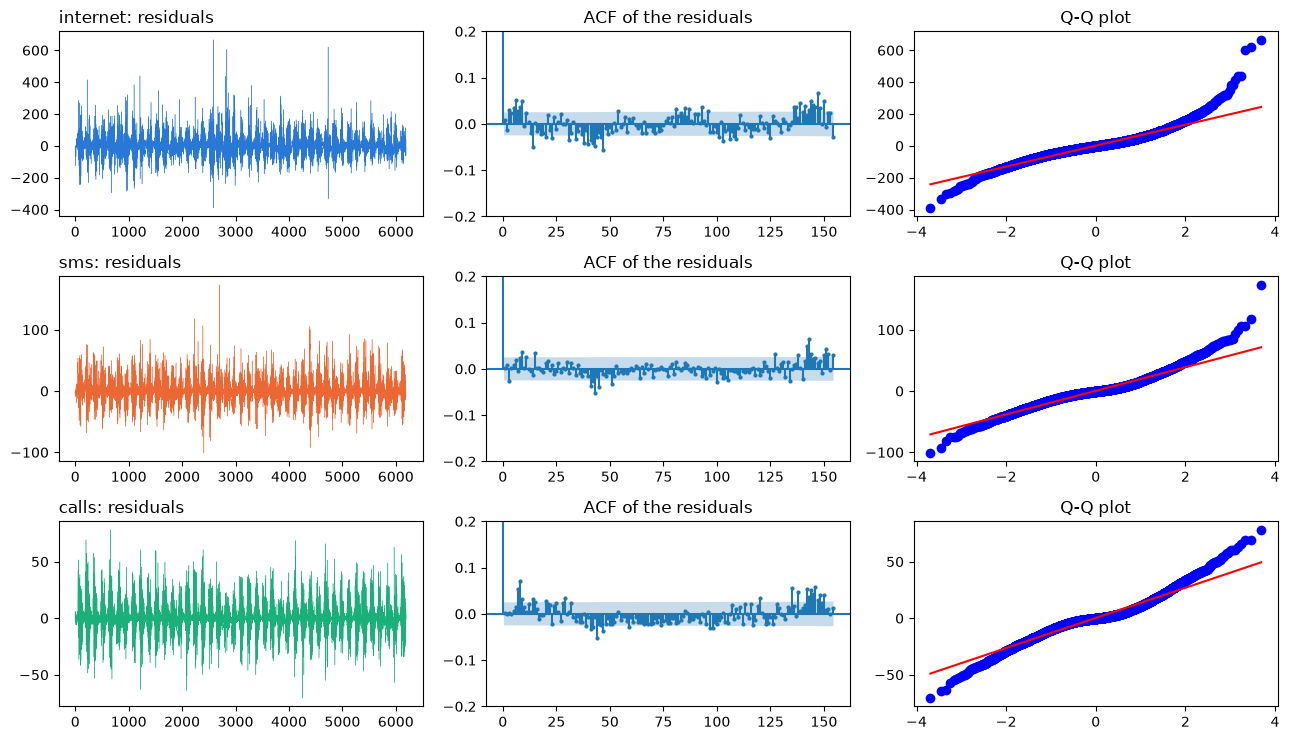

In [18]:
# Residuals of the SARIMA models: time plot, ACF, Q-Q plot
fig, axes = plt.subplots(len(SERIES), 3, figsize=(13, 7.5))
for i, s in enumerate(SERIES):
    e = RESID[(s, "SARIMA")]
    axes[i, 0].plot(e, lw=0.3, color=COLOR[s]); axes[i, 0].set_title(f"{s}: residuals", loc="left")
    plot_acf(e, lags=SEASON + 10, ax=axes[i, 1], markersize=2, title="ACF of the residuals")
    axes[i, 1].set_ylim(-0.2, 0.2)
    stats.probplot(e, plot=axes[i, 2]); axes[i, 2].set_title("Q-Q plot"); axes[i, 2].set_xlabel(""); axes[i, 2].set_ylabel("")
fig.tight_layout(); plt.show()

#### Ερμηνεία

Τα κατάλοιπα είναι κοντά στον λευκό θόρυβο. Η μεγαλύτερη απόλυτη αυτοσυσχέτιση είναι 0.064 έως 0.083, και συνήθως
βρίσκεται γύρω από το lag 144. Το Ljung-Box απορρίπτει παρ' όλα αυτά τη λευκότητα σχεδόν παντού, γιατί με
$n \approx 6000$ σημεία ανιχνεύει και πολύ μικρές αυτοσυσχετίσεις, πρακτικά αμελητέες για την πρόβλεψη.

Τα κατάλοιπα δεν είναι κανονικά: το Q-Q plot δείχνει βαριές ουρές, με υπερβάλλουσα κύρτωση περίπου 6.8 στο Internet
και 2.7 έως 3.4 στα SMS και Calls, λόγω των απρόβλεπτων αιχμών. Είναι επίσης ετεροσκεδαστικά: η τυπική απόκλιση από
τις 08:00 έως τις 20:00 είναι 1.6 (Internet) έως 3.3 (Calls) φορές μεγαλύτερη από των υπόλοιπων ωρών. Άρα ένα
διάστημα σταθερού πλάτους θα είναι πολύ φαρδύ τη νύχτα και πολύ στενό στις αιχμές (ενότητα 5.8).

Στο SARIMA και στις τρεις σειρές $\Theta_1 \approx -0.99$. Τότε το $(1 - 0.99 B^{144})$ σχεδόν αναιρεί την εποχική
διαφόριση $(1 - B^{144})$, δηλαδή το μοντέλο δεν αντιγράφει τη χθεσινή ημέρα αλλά μαθαίνει ένα σχεδόν σταθερό
ημερήσιο σχήμα από πολλές ημέρες. Είναι ουσιαστικά η ίδια ιδέα με τους ημερήσιους όρους Fourier του ARIMA-x. Η τιμή
είναι κοντά στο όριο της αντιστρεψιμότητας ($|\Theta_1| < 1$), αλλά δεν το ξεπερνά.

### 2.7 Rolling-window πρόβλεψη ($h = 1$ και $H = 5$)

Ακολουθούμε τη διαδικασία των Siami-Namini et al. (ICMLA 2018):

```
history <- train
for t in test:
    model   <- ARIMA(history)        # στο άρθρο: re-fit σε κάθε βήμα
    y_hat_t <- model.forecast()
    history.append(y_t)           # προσθέτουμε την ΠΡΑΓΜΑΤΙΚΗ τιμή, όχι την πρόβλεψη
```

Το κρίσιμο σημείο είναι η τελευταία γραμμή: μετά από κάθε πρόβλεψη το μοντέλο μαθαίνει την πραγματική τιμή, όπως
ένα δίκτυο που μετρά συνεχώς το φορτίο.

Η μία διαφορά μας είναι ότι οι παράμετροι εκτιμώνται μία φορά στο train και μένουν σταθερές, αντί για re-fit σε
κάθε βήμα. Με 2304 αφετηρίες και 22 λεπτά ανά fit το re-fit δεν είναι εφικτό, και με 6624 σημεία στο train μερικές
ακόμη τιμές θα άλλαζαν ελάχιστα τις παραμέτρους. Αυτό που μετράει είναι ότι η κατάσταση $a_t$ ενημερώνεται με
κάθε πραγματική τιμή, και αυτό γίνεται σε κάθε βήμα.

Το short-term ($h = 1$) προβλέπει κάθε σημείο του test. Το long-term ($H = 5$) προβλέπει 5 βήματα από αφετηρίες ανά
5 βήματα, οπότε κάθε σημείο προβλέπεται μία φορά. Η πρόβλεψη πολλών βημάτων είναι αναδρομική (αυτοπαλινδρομική): οι
άγνωστες μελλοντικές διαταραχές τίθενται 0 και η κατάσταση προχωρά με το $T$:

$$\hat z_{t+j \mid t} = Z\, T^{\,j-1} a_{t+1 \mid t}$$

Στο SARIMA προσθέτουμε πίσω την τιμή της προηγούμενης ημέρας, $\hat y_{t+j} = \hat z_{t+j} + y_{t+j-144}$, και στο
ARIMA-x τους γνωστούς όρους, $\hat y_{t+j} = \hat z_{t+j} + \beta^\top x_{t+j}$.

Η εκφώνηση αναφέρει ιστορικό παράθυρο π.χ. $w = 10$. Στην ARIMA το παράθυρο δεν είναι ελεύθερη υπερπαράμετρος αλλά
προκύπτει από την τάξη του μοντέλου: το SARIMA χρησιμοποιεί τις τελευταίες $p$ τιμές της διαφορισμένης σειράς,
δηλαδή ουσιαστικά τις τελευταίες $p + 144$ τιμές. Ένα μοντέλο εκτιμημένο σε μόλις 10 σημεία δεν θα έβλεπε καν την
ημερήσια περίοδο.

Το τελευταίο μέρος του κελιού συγκρίνει τις προβλέψεις μας με την `forecast` του `statsmodels` από μία αφετηρία.

In [19]:
H_SHORT, H_LONG = 1, 5
idx1 = np.arange(n_train, N)                               # h = 1: every test point
origins5 = np.arange(n_train, N - H_LONG + 1, H_LONG)      # H = 5: every 5th test point
idx5 = (origins5[:, None] + np.arange(H_LONG)).ravel()


def rolling_forecast(s, family):
    """Fixed parameters; the filter updates the state with every actual value, then we step it forward."""
    y, X, off = Y[s], FAMILIES[family][0], SEASON if family == "SARIMA" else 0
    beta = None if X is None else BEST.loc[(s, family), "params"][:X.shape[1]]
    t0 = time.perf_counter()
    fr = run_filter(y, s, family, X)
    filter_seconds = time.perf_counter() - t0
    Z, T = fr.design[..., 0], fr.transition[..., 0]

    def forecast(origins, H):
        """Forecast y[t], ..., y[t+H-1] from each origin t, using only y[:t]."""
        a = fr.predicted_state[:, origins - off]               # state given the data before t
        out = np.zeros((len(origins), H))
        for j in range(H):
            t = origins + j
            out[:, j] = (Z @ a)[0] + (y[t - SEASON] if X is None else X[t] @ beta)   # undo D = 1, or add the inputs
            a = T @ a
        return out

    t0 = time.perf_counter()
    h1, H5 = forecast(idx1, H_SHORT)[:, 0], forecast(origins5, H_LONG).ravel()
    return {"h1": h1, "H5": H5, "forecast": forecast, "seconds_per_step": filter_seconds / len(y),
            "seconds_per_forecast": filter_seconds / len(y) + (time.perf_counter() - t0) / (len(h1) + len(origins5))}


ARIMA_ROLL = {(s, fam): rolling_forecast(s, fam) for s in SERIES for fam in FAMILIES}

# Check against statsmodels' own forecast from one origin
t = origins5[7]
for fam, (X, *_) in FAMILIES.items():
    s = "calls"
    b = BEST.loc[(s, fam)]
    Xt, Xf = (None, None) if X is None else (X[:t], X[t:t + H_LONG])
    ref = make_model(Y[s][:t], fam, int(b["p"]), int(b["q"]), Xt).filter(
        b["params"], cov_type="none", conserve_memory=NO_COV).forecast(H_LONG, exog=Xf)
    if X is None:
        ref = ref + Y[s][t - SEASON:t - SEASON + H_LONG]
    print(fam, "max |ours - statsmodels|:", np.abs(ARIMA_ROLL[(s, fam)]["forecast"](np.array([t]), H_LONG)[0] - ref).max())

SARIMA max |ours - statsmodels|: 0.0
ARIMA-x max |ours - statsmodels|: 5.773159728050814e-15


### 2.8 Σύνοψη

Τα ADF/KPSS έδωσαν $d = 0$, η ACF έδειξε ισχυρή ημερήσια εποχικότητα ($D = 1$, $s = 144$, $Q = 1$) και το BIC
επέλεξε μικρές τάξεις. Η αποτίμηση στο test βρίσκεται στην ενότητα 5, μαζί με όλα τα υπόλοιπα μοντέλα.

## 3. Deep learning: LSTM

Η ενότητα αυτή εφαρμόζει ένα αναδρομικό νευρωνικό δίκτυο (LSTM) στο ίδιο πρόβλημα, με την ίδια διαδικασία
αποτίμησης (ίδιο train/test, ίδιοι ορίζοντες, ίδια σημεία του test, ίδιες μετρικές), ώστε η σύγκριση με την
οικογένεια ARIMA να είναι δίκαιη. Αυτό είναι και το ζητούμενο του άρθρου των Siami-Namini et al.

### 3.1 Θεωρία

#### 3.1.1 Από τα γραμμικά μοντέλα στα νευρωνικά δίκτυα

Η ARIMA είναι γραμμική: η πρόβλεψη είναι ένα σταθμισμένο άθροισμα προηγούμενων τιμών και διαταραχών. Ένα
νευρωνικό δίκτυο μαθαίνει μια μη γραμμική συνάρτηση $\hat y = f_\theta(\text{ιστορικό})$, με παραμέτρους $\theta$
που εκτιμώνται ελαχιστοποιώντας ένα σφάλμα στο train με gradient descent. Έτσι μπορεί, κατ' αρχήν, να μάθει σχέσεις
που η ARIMA δεν μπορεί να εκφράσει (π.χ. «η άνοδος είναι πιο απότομη τα πρωινά των εργάσιμων»). Το τίμημα είναι
πολλές περισσότερες παράμετροι, ανάγκη για περισσότερα δεδομένα και κίνδυνος υπερπροσαρμογής.

#### 3.1.2 Αναδρομικά δίκτυα (RNN)

Ένα RNN διαβάζει την ακολουθία ένα βήμα τη φορά και κρατά μια κρυφή κατάσταση $h_t$, που λειτουργεί σαν μνήμη
όσων έχει δει ως τώρα:

$$h_t = \tanh\!\big(W x_t + U h_{t-1} + b\big)$$

Οι ίδιοι πίνακες $W, U$ χρησιμοποιούνται σε κάθε βήμα, οπότε το δίκτυο εφαρμόζει τον ίδιο «κανόνα ενημέρωσης» σε
όλη την ακολουθία, όπως ακριβώς η ARIMA εφαρμόζει τους ίδιους συντελεστές σε κάθε $t$. Η πρόβλεψη βγαίνει από την
τελευταία κατάσταση: $\hat y = V h_t + c$.

Το πρόβλημα των εξαφανιζόμενων gradients. Η εκπαίδευση γίνεται με *Backpropagation Through Time*: το gradient του
σφάλματος ως προς μια κατάσταση $k$ βήματα πίσω είναι γινόμενο $k$ Ιακωβιανών:

$$\frac{\partial h_t}{\partial h_{t-k}} \;=\; \prod_{j=0}^{k-1} \frac{\partial h_{t-j}}{\partial h_{t-j-1}} \;=\; \prod_{j=0}^{k-1} \operatorname{diag}\!\big(1 - h_{t-j}^2\big)\, U$$

Αν οι παράγοντες έχουν μέτρο μικρότερο από 1, το γινόμενο μηδενίζεται εκθετικά (vanishing gradient) και το δίκτυο
δεν μπορεί να μάθει εξαρτήσεις από μακρινό παρελθόν. Αν έχουν μέτρο μεγαλύτερο από 1, εκρήγνυται (exploding
gradient) και η εκπαίδευση γίνεται ασταθής. Στο πρόβλημά μας αυτό έχει σημασία: για $w = 144$ το δίκτυο πρέπει να
συνδέσει την τρέχουσα τιμή με τιμές μιας ολόκληρης ημέρας πριν.

#### 3.1.3 LSTM (Hochreiter και Schmidhuber, 1997)

Το LSTM λύνει το πρόβλημα προσθέτοντας μια δεύτερη κατάσταση, την κατάσταση κελιού $c_t$ (μακροπρόθεσμη μνήμη), και
τρεις πύλες που αποφασίζουν τι ξεχνιέται, τι γράφεται και τι διαβάζεται. Κάθε πύλη είναι ένα διάνυσμα με τιμές στο
$(0, 1)$, μέσω της σιγμοειδούς $\sigma(x) = 1 / (1 + e^{-x})$, και πολλαπλασιάζεται στοιχείο προς στοιχείο ($\odot$):

$$
\begin{aligned}
f_t &= \sigma\big(W_f x_t + U_f h_{t-1} + b_f\big) && \text{forget gate: πόσο από την παλιά μνήμη κρατάμε} \\[3pt]
i_t &= \sigma\big(W_i x_t + U_i h_{t-1} + b_i\big) && \text{input gate: πόση νέα πληροφορία γράφουμε} \\[3pt]
\tilde c_t &= \tanh\big(W_c x_t + U_c h_{t-1} + b_c\big) && \text{υποψήφια νέα πληροφορία} \\[3pt]
c_t &= f_t \odot c_{t-1} \;+\; i_t \odot \tilde c_t && \text{ενημέρωση της μνήμης} \\[3pt]
o_t &= \sigma\big(W_o x_t + U_o h_{t-1} + b_o\big) && \text{output gate: τι από τη μνήμη δίνουμε ως έξοδο} \\[3pt]
h_t &= o_t \odot \tanh(c_t) && \text{νέα κρυφή κατάσταση}
\end{aligned}
$$

Γιατί δουλεύει. Η ενημέρωση της μνήμης $c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t$ είναι προσθετική. Το
gradient από το $c_t$ προς το $c_{t-1}$ είναι απλώς $f_t$, όχι γινόμενο με έναν πίνακα βαρών και μια παράγωγο
$\tanh$. Όταν το δίκτυο μάθει $f_t \approx 1$, η πληροφορία και το gradient περνούν πολλά βήματα σχεδόν
αναλλοίωτα. Οι πύλες μαθαίνονται από τα δεδομένα, οπότε το δίκτυο αποφασίζει μόνο του τι αξίζει να θυμάται (π.χ. «η
κίνηση ανεβαίνει εδώ και μία ώρα») και τι να ξεχάσει.

### 3.2 Διατύπωση ως πρόβλημα επιβλεπόμενης μάθησης

Το δίκτυο δεν «καταλαβαίνει» χρονοσειρές. Του δίνουμε ζεύγη εισόδου και στόχου, που κατασκευάζουμε κόβοντας τη σειρά
σε παράθυρα μήκους $w$:

$$\underbrace{(y_{t-w},\; \dots,\; y_{t-1})}_{\text{είσοδος: τελευταίες } w \text{ τιμές}} \;\longmapsto\; \underbrace{(y_t,\; \dots,\; y_{t+h-1})}_{\text{στόχος: επόμενες } h \text{ τιμές}}$$

Μέγεθος παραθύρου $w$. Εδώ, σε αντίθεση με την ARIMA, το $w$ είναι πραγματική υπερπαράμετρος: το δίκτυο βλέπει
μόνο όσα είναι μέσα στο παράθυρο. Δοκιμάζουμε δύο τιμές:
* $w = 10$ (100 λεπτά), η τιμή που προτείνει η εκφώνηση. Το δίκτυο βλέπει μόνο την πρόσφατη πορεία.
* $w = 144$ (24 ώρες). Το παράθυρο περιέχει ολόκληρη την προηγούμενη ημέρα, μαζί με την τιμή $y_{t-144}$ της ίδιας
  ώρας χθες. Έτσι το δίκτυο μπορεί να μάθει την ημερήσια περιοδικότητα, όπως το SARIMA.

Πρόβλεψη πέντε βημάτων: direct multi-output (MIMO). Για $H = 5$ το δίκτυο έχει 5 εξόδους και προβλέπει και τα 5
βήματα ταυτόχρονα. Η εναλλακτική είναι η αναδρομική πρόβλεψη της ARIMA (προβλέπουμε ένα βήμα και το ξαναδίνουμε
ως είσοδο). Επιλέγουμε MIMO γιατί:
* τα σφάλματα δεν συσσωρεύονται: στην αναδρομική πρόβλεψη ένα λάθος στο βήμα 1 γίνεται είσοδος για το βήμα 2,
* το δίκτυο εκπαιδεύεται απευθείας στον στόχο που μας ενδιαφέρει (5 βήματα μπροστά),
* είναι ο φυσικός τρόπος χρήσης ενός νευρωνικού δικτύου: μία έξοδος ανά βήμα, ένα πέρασμα.

Για $h = 1$ οι δύο στρατηγικές ταυτίζονται. Η διαφορά στρατηγικής από την ARIMA είναι ένα από τα πράγματα που
συγκρίνουμε.

### 3.3 Κανονικοποίηση min-max στο $[0, 1]$

Πριν μπουν στο δίκτυο, οι τιμές μετασχηματίζονται γραμμικά ώστε το train να καταλαμβάνει ακριβώς το $[0, 1]$, και στην
έξοδο εφαρμόζεται ο αντίστροφος μετασχηματισμός:

$$\tilde y_t = \frac{y_t - y_{\min}}{y_{\max} - y_{\min}} \qquad\qquad \hat y_t = \hat{\tilde y}_t \,\big(y_{\max} - y_{\min}\big) + y_{\min}$$

Η ARIMA δεν χρειάζεται κανονικοποίηση, αφού είναι γραμμική και ανεξάρτητη της κλίμακας, αλλά το LSTM χρειάζεται. Οι
$\sigma$ και $\tanh$ των πυλών έχουν παράγωγο σχεδόν μηδέν για μεγάλες εισόδους, οπότε με τιμές της τάξης του 1000
(Internet) οι πύλες θα «κολλούσαν» στο 0 ή στο 1 και το δίκτυο δεν θα μάθαινε τίποτα. Επίσης, τα βάρη
αρχικοποιούνται για εισόδους κλίμακας περίπου 1, και ο Adam με learning rate $10^{-3}$ υποθέτει την ίδια κλίμακα.
Τέλος, μετά την κανονικοποίηση οι τρεις σειρές έχουν την ίδια κλίμακα, οπότε ταιριάζει σε όλες η ίδια
αρχιτεκτονική.

Γιατί τα $y_{\min}, y_{\max}$ υπολογίζονται μόνο στο train. Αν χρησιμοποιούσαμε όλη τη σειρά, η κανονικοποίηση θα
«ήξερε» το μέγιστο του test (την αιχμή της Πρωτοχρονιάς), δηλαδή πληροφορία από το μέλλον (διαρροή). Συνέπεια: στο test
οι κανονικοποιημένες τιμές μπορεί να βγουν έξω από το $[0, 1]$.

### 3.4 Από-περιοδικοποίηση (deseasonalisation)

Η εκφώνηση προτείνει να αφαιρέσουμε την περιοδικότητα πριν από το δίκτυο και να την επαναφέρουμε στο τέλος. Ορίζουμε
το εποχικό προφίλ $S_t$ ως τη μέση τιμή του train για τον ίδιο τύπο ημέρας και το ίδιο δεκάλεπτο της ημέρας
(το προφίλ που είδαμε στην EDA, ενότητα 1.4):

$$S_t \;=\; \operatorname{mean}\big\{\, y_\tau \;:\; \tau \in \text{train},\;\; \text{daytype}(\tau) = \text{daytype}(t),\;\; \text{slot}(\tau) = \text{slot}(t) \,\big\}$$

Το δίκτυο μοντελοποιεί το υπόλοιπο και στο τέλος προσθέτουμε πίσω το προφίλ:

$$r_t = y_t - S_t \qquad\longrightarrow\qquad \text{LSTM} \qquad\longrightarrow\qquad \hat y_t = \hat r_t + S_t$$

Η κανονικοποίηση min-max εφαρμόζεται στο $r_t$ σε αυτή την περίπτωση. Το $S_t$ είναι γνωστό για κάθε μελλοντική στιγμή
(εξαρτάται μόνο από την ημερομηνία και την ώρα), οπότε η επαναφορά είναι πάντα δυνατή.

#### Γιατί μπορεί να βοηθήσει
* Το δίκτυο δεν χρειάζεται να μάθει το ημερήσιο σχήμα, που είναι το μεγαλύτερο και πιο προβλέψιμο μέρος της
  σειράς. Εστιάζει στις αποκλίσεις από το κανονικό μοτίβο.
* Για $w = 10$ αυτό είναι κρίσιμο: η περίοδος (144) είναι πολύ μεγαλύτερη από το παράθυρο, οπότε χωρίς το $S_t$ το
  δίκτυο δεν έχει τρόπο να ξέρει ότι σε μία ώρα έρχεται η μεσημεριανή αιχμή.
* Είναι η ίδια ιδέα με το ARIMA-x: ένα ντετερμινιστικό μέρος για την περιοδικότητα και ένα στοχαστικό μοντέλο για
  το υπόλοιπο.

Πότε μπορεί να βλάψει: όταν το πραγματικό μοτίβο στο test διαφέρει από αυτό του train. Τότε το $S_t$ είναι λάθος
και το υπόλοιπο $r_t$ στο test έχει τιμές πολύ έξω από αυτές που είδε το δίκτυο στην εκπαίδευση. Η εορταστική
περίοδος του test είναι ακριβώς τέτοια περίπτωση, οπότε το αποτέλεσμα δεν είναι προφανές εκ των προτέρων.

### 3.5 Αρχιτεκτονική και εκπαίδευση

| Επιλογή | Τιμή | Γιατί |
|:---|:---|:---|
| Αρχιτεκτονική | 2 στρώματα LSTM, 64 μονάδες, και ένα γραμμικό στρώμα $64 \to h$ | δύο στρώματα επιτρέπουν ιεραρχία (το πρώτο βλέπει τοπικά μοτίβα, το δεύτερο συνδυάζει). 64 μονάδες (περίπου 50 χιλιάδες παράμετροι) αρκούν για μία σειρά με περίπου 6500 σημεία χωρίς να την απομνημονεύουν |
| Έξοδος | η κατάσταση $h_t$ του τελευταίου βήματος, μέσω γραμμικού στρώματος | η $h_t$ συνοψίζει όλο το παράθυρο. Γραμμική έξοδος, για να μπορεί να βγάλει και τιμές έξω από το $[0,1]$ |
| Dropout | 0.1 ανάμεσα στα δύο στρώματα | μηδενίζει τυχαία μέρος των ενεργοποιήσεων στην εκπαίδευση, ώστε το δίκτυο να μη στηρίζεται σε λίγες μονάδες (κανονικοποίηση κατά της υπερπροσαρμογής) |
| Loss | MSE στην κανονικοποιημένη κλίμακα | ομαλή και παραγωγίσιμη, και αντιστοιχεί στο RMSE: τιμωρεί έντονα τις χαμένες αιχμές |
| Optimizer | Adam, learning rate $10^{-3}$, batch 128 | ο Adam προσαρμόζει το βήμα κάθε παραμέτρου χωριστά και είναι η τυπική, ανθεκτική επιλογή για RNN. Τα mini-batches δίνουν θορυβώδη αλλά γρήγορα βήματα, που βοηθούν και τη γενίκευση |
| Gradient clipping | νόρμα το πολύ 1 | προστασία από τα exploding gradients της ενότητας 3.1.2 |
| Validation | το τελευταίο 10% του train (περίπου 4.6 ημέρες), χρονολογικά | ο έλεγχος γενίκευσης πρέπει να γίνεται, όπως και το test, σε δεδομένα που έρχονται μετά από αυτά της εκπαίδευσης. Το test δεν χρησιμοποιείται ποτέ για αποφάσεις |
| Early stopping | σταματάμε αν το validation loss δεν βελτιωθεί για 8 εποχές, και κρατάμε τα καλύτερα βάρη | το training loss μειώνεται πάντα, ενώ το validation loss σταματά να πέφτει όταν το δίκτυο αρχίζει να απομνημονεύει. Εκεί σταματάμε |
| Seed | σταθερό (0) | αναπαραγωγιμότητα: η αρχικοποίηση και η σειρά των batches είναι τυχαίες |

Τα παράθυρα του train ανακατεύονται σε κάθε εποχή. Αυτό δεν είναι διαρροή: κάθε παράθυρο είναι αυτόνομο δείγμα
(είσοδος από το παρελθόν, στόχος αμέσως μετά), και το ανακάτεμα απλώς αποτρέπει το δίκτυο από το να μάθει τη σειρά
των batches.

Πειράματα: 3 σειρές $\times$ 2 παράθυρα ($w = 10, 144$) $\times$ 2 εκδοχές (raw, από-περιοδικοποιημένη) $\times$ 2
ορίζοντες ($h = 1$, $H = 5$) $= 24$ δίκτυα. Εκπαιδεύονται παράλληλα (κάθε δίκτυο σε δικό του worker με 4 threads).
Επειδή η εκπαίδευση παίρνει λίγα λεπτά, τα αποτελέσματα αποθηκεύονται στο `results/lstm_notebook.pkl` και
φορτώνονται από εκεί στις επόμενες εκτελέσεις. Για νέα εκπαίδευση: `RETRAIN = True` ή διαγραφή του αρχείου.

In [20]:
import os
import joblib
import torch
import torch.nn as nn
from joblib import parallel_config

SEED = 0
LSTM_WINDOWS = (10, 144)


def seasonal_profile(idx, y, n_fit):
    """S_t: mean per (day type, 10-min slot), computed on the first n_fit points (the train set)."""
    key = day_type(idx) * SEASON + (idx.hour * 6 + idx.minute // 10).values
    means = pd.Series(y[:n_fit]).groupby(key[:n_fit]).mean()
    return means.reindex(key).values


class LSTMNet(nn.Module):
    def __init__(self, horizon, hidden=64, layers=2, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden, layers, batch_first=True, dropout=dropout)
        self.head = nn.Linear(hidden, horizon)

    def forward(self, x):                      # x: (batch, w, 1)
        out, _ = self.lstm(x)
        return self.head(out[:, -1])           # state of the last time step -> h outputs


def make_windows(z, targets, w, h):
    """Inputs z[t-w:t] and targets z[t:t+h] for every t in targets."""
    X = np.stack([z[t - w:t] for t in targets])[..., None].astype(np.float32)
    Yw = np.stack([z[t:t + h] for t in targets]).astype(np.float32)
    return torch.from_numpy(X), torch.from_numpy(Yw)

In [21]:
def run_lstm(s, w, deseason, h, seed=SEED, max_epochs=80, patience=8, threads=4):
    torch.set_num_threads(threads); torch.manual_seed(seed); np.random.seed(seed)
    y = Y[s]
    S = seasonal_profile(df.index, y, n_train) if deseason else np.zeros_like(y)
    r = y - S
    lo, hi = r[:n_train].min(), r[:n_train].max()           # min-max from the train set only
    z = (r - lo) / (hi - lo)

    # training windows; the last 10% (in time) is the validation set
    targets = np.arange(w, n_train - h + 1)
    n_val = int(0.1 * len(targets))
    Xtr, Ytr = make_windows(z, targets[:-n_val], w, h)
    Xva, Yva = make_windows(z, targets[-n_val:], w, h)

    net = LSTMNet(h)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    lossf = nn.MSELoss()
    best, best_state, bad, hist = np.inf, None, 0, []
    t0 = time.perf_counter()
    for ep in range(max_epochs):
        net.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 128):
            b = perm[i:i + 128]
            opt.zero_grad()
            loss = lossf(net(Xtr[b]), Ytr[b])
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
        net.eval()
        with torch.no_grad():
            tr_loss = lossf(net(Xtr), Ytr).item()
            va_loss = lossf(net(Xva), Yva).item()
        hist.append((tr_loss, va_loss))
        if va_loss < best - 1e-7:                             # early stopping on the validation loss
            best, bad = va_loss, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    train_seconds = time.perf_counter() - t0
    net.load_state_dict(best_state); net.eval()

    # Rolling evaluation on the test set: the input is always the last w ACTUAL values
    origins = np.arange(n_train, N) if h == 1 else np.arange(n_train, N - h + 1, h)
    Xte, _ = make_windows(np.r_[z, np.zeros(h)], origins, w, h)
    with torch.no_grad():
        zhat = net(Xte).numpy()
    tidx = origins[:, None] + np.arange(h)[None, :]
    yhat = (zhat * (hi - lo) + lo + S[tidx]).ravel()          # inverse min-max, then add the profile back
    return {"pred": yhat, "origins": origins, "history": hist, "epochs": len(hist),
            "best_epoch": int(np.argmin([v for _, v in hist])) + 1, "train_seconds": train_seconds,
            "params": sum(p.numel() for p in net.parameters())}

In [22]:
RETRAIN = False
LSTM_FILE = "results/lstm_notebook.pkl"
LSTM_JOBS = [(s, w, ds, h) for s in SERIES for w in LSTM_WINDOWS for ds in (False, True) for h in (H_SHORT, H_LONG)]

if RETRAIN or not os.path.exists(LSTM_FILE):
    t0 = time.perf_counter()
    with parallel_config(backend="loky", inner_max_num_threads=4):    # 12 workers x 4 threads
        out = Parallel(n_jobs=12)(delayed(run_lstm)(*j) for j in LSTM_JOBS)
    LSTM_RES = dict(zip(LSTM_JOBS, out))
    joblib.dump(LSTM_RES, LSTM_FILE)
    print(f"trained {len(LSTM_JOBS)} networks in {time.perf_counter() - t0:.0f}s")
else:
    LSTM_RES = joblib.load(LSTM_FILE)
    print("loaded", LSTM_FILE)

pd.DataFrame([{"series": s, "w": w, "deseason": ds, "h": h, "params": v["params"], "epochs": v["epochs"],
               "best epoch": v["best_epoch"], "train (s)": round(v["train_seconds"])}
              for (s, w, ds, h), v in LSTM_RES.items()]).set_index(["series", "w", "deseason", "h"])

loaded results/lstm_notebook.pkl


params  epochs  best epoch  train (s)
series   w   deseason h                                       
internet 10  False    1   50497      64          56        112
                      5   50757      36          28         63
             True     1   50497      41          33         55
                      5   50757      43          35         77
         144 False    1   50497      46          38        745
                      5   50757      36          28        587
             True     1   50497      58          50        800
                      5   50757      27          19        471
sms      10  False    1   50497      43          35         73
                      5   50757      73          65        123
             True     1   50497      57          49         95
                      5   50757      20          12         28
         144 False    1   50497      67          59        849
                      5   50757      26          18        440
             True     1   50497      45          37        689
                      5   50757      18          10        314
calls    10  False    1   50497      40          32         58
                      5   50757      34          26         56
             True     1   50497      56          48         82
                      5   50757      30          22         51
         144 False    1   50497      53          45        667
                      5   50757      60          52        669
             True     1   50497      54          46        668
                      5   50757      30          22        435

Καμπύλες εκμάθησης. Το validation loss ανά εποχή (λογαριθμική κλίμακα) για $h = 1$. Δείχνει αν η εκπαίδευση
συγκλίνει, πόσο γρήγορα, και πού σταμάτησε το early stopping. Οι συγκρίσεις ανάμεσα σε raw και από-περιοδικοποιημένη
εκδοχή εδώ δεν είναι άμεσες, γιατί η κανονικοποίηση γίνεται σε διαφορετικά μεγέθη ($y$ ή $r$).

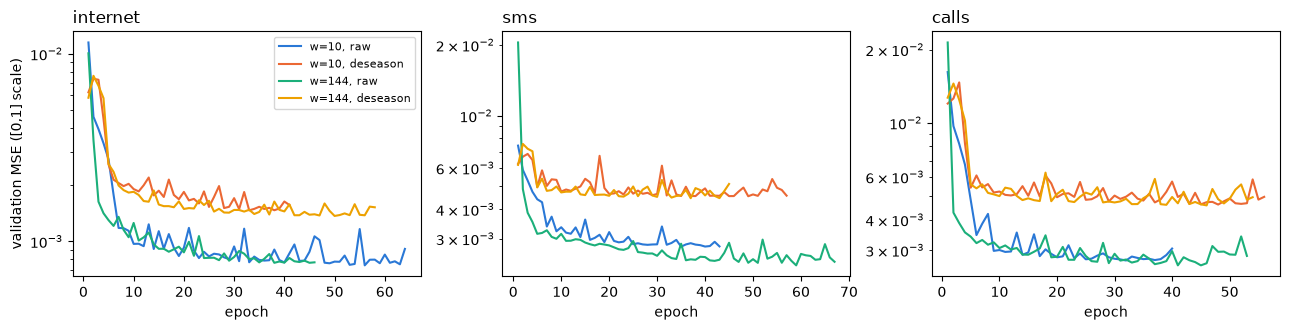

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, s in zip(axes, SERIES):
    for (w, ds), c in zip([(10, False), (10, True), (144, False), (144, True)],
                          ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]):
        hst = np.array(LSTM_RES[(s, w, ds, 1)]["history"])
        ax.plot(np.arange(1, len(hst) + 1), hst[:, 1], color=c, label=f"w={w}, {'deseason' if ds else 'raw'}")
    ax.set_yscale("log"); ax.set_title(s, loc="left"); ax.set_xlabel("epoch")
axes[0].set_ylabel("validation MSE ([0,1] scale)"); axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

In [24]:
# Best validation loss converted back to the original units, so raw and deseason are comparable
# (with deseasonalisation S_t is added back exactly, so the error of r equals the error of y)
val = {}
for (s, w, ds, h), v in LSTM_RES.items():
    y = Y[s]
    r = y - (seasonal_profile(df.index, y, n_train) if ds else 0.0)
    rng = r[:n_train].max() - r[:n_train].min()
    val[(s, h, f"LSTM w={w}" + (" deseason" if ds else ""))] = np.sqrt(min(va for _, va in v["history"])) * rng
pd.Series(val).unstack().round(1).rename_axis(["series", "h"])

LSTM w=10  LSTM w=10 deseason  LSTM w=144  LSTM w=144 deseason
series   h                                                                
calls    1       15.2                12.6        14.9                 12.6
         5       19.3                13.8        16.6                 13.6
internet 1       56.6                50.7        57.5                 48.9
         5       86.4                59.4        76.2                 59.6
sms      1       20.8                17.6        19.0                 17.4
         5       25.0                18.4        21.4                 18.3

#### Ερμηνεία της εκπαίδευσης

Όλα τα δίκτυα συγκλίνουν. Η καλύτερη εποχή είναι από 10 έως 65 και το early stopping σταματά 8 εποχές αργότερα,
πολύ πριν από το όριο των 80. Το $w = 144$ κοστίζει περίπου 10 φορές περισσότερο (περίπου 300 έως 850 s ανά δίκτυο,
έναντι 30 έως 120 s για $w = 10$), γιατί το backpropagation through time ξετυλίγει το δίκτυο σε 144 βήματα αντί για
10.

Στο validation η από-περιοδικοποίηση βοηθά σε όλες τις περιπτώσεις. Το RMSE στις αρχικές μονάδες μειώνεται κατά 8%
έως 17% για $h = 1$ (π.χ. Internet, $w = 144$: 48.9 έναντι 57.5) και κατά 14% έως 31% για $H = 5$. Με βάση όσα
ξέρουμε πριν από το test, θα ήταν λοιπόν η λογική επιλογή. Το validation όμως είναι οι τελευταίες 4.6 ημέρες του
train (11/12 έως 16/12), δηλαδή κανονικές ημέρες. Στην ενότητα 5.4 θα δούμε ότι στο test η εικόνα αλλάζει.

Στο test ακολουθούμε τον ψευδοκώδικα της ενότητας 2.7: σε κάθε αφετηρία η είσοδος του δικτύου είναι οι τελευταίες
$w$ πραγματικές τιμές, τα βάρη μένουν σταθερά και οι αφετηρίες είναι ίδιες με της ARIMA. Οι προβλέψεις αποτιμώνται
στην ενότητα 5.

## 4. Foundation model: TimesFM 3.0

### 4.1 Θεωρία

#### 4.1.1 Foundation models: η λογική των LLMs στις χρονοσειρές

Τα ARIMA και LSTM των ενοτήτων 2 και 3 εκπαιδεύονται από το μηδέν σε μία σειρά: ό,τι «ξέρουν» το έμαθαν από τις
6624 τιμές του train. Ένα foundation model ακολουθεί την αντίθετη λογική, την ίδια με τα LLMs:

Ένα μεγάλο transformer εκπαιδεύεται μία φορά, a priori, σε τεράστιο και ετερογενή όγκο χρονοσειρών
(δισεκατομμύρια σημεία από πολλά πεδία: ενέργεια, κίνηση στο web, λιανική, καιρός, μεταφορές, συνθετικές σειρές),
με στόχο να προβλέπει τη συνέχεια κάθε σειράς. Όπως ένα LLM μαθαίνει γλώσσα προβλέποντας την επόμενη λέξη, έτσι
αυτό μαθαίνει γενικά μοτίβα χρονοσειρών: επίπεδα και τάσεις, περιοδικότητες, αλλαγές επιπέδου, αιχμές.

Στο δικό μας πρόβλημα το χρησιμοποιούμε με δύο τρόπους. Στο zero-shot εφαρμόζεται χωρίς καμία εκπαίδευση στα
δεδομένα μας: το ιστορικό της σειράς δίνεται ως context, όπως το prompt σε ένα LLM, και το μοντέλο αναγνωρίζει
μέσα σε αυτό την περιοδικότητα και το επίπεδο και τα συνεχίζει. Στο fine-tuning συνεχίζουμε την εκπαίδευση, με
μικρό learning rate, σε δικά μας δεδομένα, ώστε να προσαρμοστεί στις ιδιαιτερότητές τους.

| | ARIMA / LSTM | Foundation model |
|:---|:---|:---|
| Γνώση | μόνο από τη συγκεκριμένη σειρά | από εκατομμύρια σειρές, μεταφέρεται (*transfer learning*) |
| Εκπαίδευση στα δεδομένα μας | απαραίτητη | προαιρετική (zero-shot ή fine-tuning) |
| Παράμετροι | από μερικές έως περίπου 50 χιλιάδες | εκατοντάδες εκατομμύρια |
| Κόστος | στην εκπαίδευση | κυρίως στο inference |

#### 4.1.2 Η αρχιτεκτονική του TimesFM

Το TimesFM (Google Research, Das et al., ICML 2024) είναι decoder-only transformer, δηλαδή η ίδια αρχιτεκτονική
με τα GPT:

Η σειρά κόβεται σε διαδοχικά κομμάτια (patches) των 32 σημείων, και κάθε patch γίνεται ένα διάνυσμα, το αντίστοιχο
ενός token. Με context 1024 σημείων ο transformer βλέπει 32 tokens αντί για 1024, κάτι που κάνει την προσοχή
(attention) φθηνή και επιτρέπει μακρύ context. Κάθε context κανονικοποιείται με τη δική του μέση τιμή και τυπική
απόκλιση (RevIN), οπότε Internet ($\sim 10^3$) και SMS ($\sim 10^2$) αντιμετωπίζονται με τον ίδιο τρόπο, χωρίς τη
min-max κανονικοποίηση της ενότητας 3.3.

Κάθε patch βλέπει μόνο τα προηγούμενα (causal self-attention). Η προσοχή επιτρέπει στο μοντέλο να συγκρίνει άμεσα
το τρέχον κομμάτι με οποιοδήποτε παλαιότερο, π.χ. με την ίδια ώρα χθες ή πριν από μία εβδομάδα, κάτι που ένα LSTM
πρέπει να το «κουβαλήσει» στην κατάστασή του μέσα από 144 ή 1008 βήματα.

Η έξοδος είναι πιθανοτική: για κάθε μελλοντικό βήμα το μοντέλο δίνει τα ποσοστημόρια $0.1, 0.2, \dots, 0.9$,
εκπαιδευμένο με quantile (pinball) loss, και ως σημειακή πρόβλεψη χρησιμοποιούμε τη διάμεσο ($q_{0.5}$). Ένα
πέρασμα δίνει ολόκληρο patch εξόδου (64 βήματα), οπότε για $H = 5$ η πρόβλεψη είναι direct, όπως στο MIMO LSTM, και
όχι αναδρομική όπως στην ARIMA.

TimesFM 3.0 (`google/timesfm-3.0-pytorch`): περίπου 331 εκατομμύρια παράμετροι, 20 στρώματα transformer, context
έως περίπου 15 χιλιάδες σημεία, και υποστήριξη πολυμεταβλητής πρόβλεψης και covariates (δεν τις χρησιμοποιούμε εδώ:
προβλέπουμε κάθε σειρά μόνη της, όπως και με τα άλλα μοντέλα, ώστε η σύγκριση να είναι δίκαιη). Τα βάρη διατίθενται με
άδεια μη εμπορικής χρήσης, κάτι που μετράει αν ένας πάροχος θέλει να το χρησιμοποιήσει σε παραγωγή.

Τι περιμένουμε. Τα δεδομένα μας (κίνηση ανά δεκάλεπτο, έντονη ημερήσια και εβδομαδιαία περιοδικότητα) είναι
ακριβώς το είδος σειράς που υπάρχει άφθονο στα δεδομένα προεκπαίδευσης. Επιπλέον το μοντέλο έχει δει πολλές σειρές με
αλλαγές επιπέδου και «ασυνήθιστες» περιόδους, κάτι που το δικό μας train (χωρίς καμία γιορτή σαν τα Χριστούγεννα) δεν
μπορεί να διδάξει.

### 4.2 Ρύθμιση των πειραμάτων

#### Zero-shot

* Context $= 1024$ δεκάλεπτα (περίπου 7.1 ημέρες). Καλύπτει ολόκληρη την εβδομαδιαία περίοδο (1008), οπότε το
  μοντέλο βλέπει μέσα στο context και την ίδια ώρα χθες και την ίδια ημέρα της προηγούμενης εβδομάδας. Μεγαλύτερο
  context θα αύξανε το κόστος χωρίς να προσθέτει νέο τύπο πληροφορίας. Το πρώτο σημείο του test έχει 6624 τιμές πίσω
  του, οπότε το context είναι πάντα πλήρες.
* Rolling, όπως παντού. Σε κάθε αφετηρία $t$ του test δίνουμε ως context τις 1024 πραγματικές τιμές πριν από
  το $t$ και παίρνουμε πρόβλεψη 5 βημάτων. Το lead 1 από κάθε αφετηρία δίνει το short-term ($h = 1$), και τα 5 leads από
  τις αφετηρίες ανά 5 βήματα δίνουν το long-term ($H = 5$). Είναι ακριβώς οι αφετηρίες της ενότητας 2.7 (`idx1`,
  `idx5`), οπότε η σύγκριση με ARIMA και LSTM γίνεται στα ίδια σημεία.
* Καμία προεπεξεργασία (ούτε κανονικοποίηση, ούτε από-περιοδικοποίηση): το μοντέλο παίρνει τη σειρά όπως είναι.
* Όλες οι αφετηρίες (2304 ανά σειρά) περνούν σε batches των 128, σε CPU (kamino δεν έχει GPU).

#### Fine-tuning

| Επιλογή | Τιμή | Γιατί |
|:---|:---|:---|
| Τι εκπαιδεύεται | τα 2 τελευταία από τα 20 στρώματα του transformer και το output head. Τα υπόλοιπα 18 μένουν παγωμένα | μερικό fine-tuning. Τα πρώτα στρώματα κωδικοποιούν γενικά μοτίβα που θέλουμε να κρατήσουμε, τα τελευταία την πρόβλεψη. Με περίπου 6 χιλιάδες σημεία εκπαίδευσης και 331 εκατομμύρια παραμέτρους, ένα πλήρες fine-tuning θα κινδύνευε με υπερπροσαρμογή και catastrophic forgetting (το μοντέλο «ξεχνά» όσα έμαθε στην προεκπαίδευση). Την ίδια λογική έχουν και οι μέθοδοι PEFT/LoRA |
| Δείγματα εκπαίδευσης | τυχαία παράθυρα του train: context 1024, στόχος τα επόμενα 16 βήματα | ίδια μορφή με τη χρήση του μοντέλου. 16 βήματα (αντί για 5) δίνουν περισσότερη πληροφορία ανά παράθυρο |
| Loss | pinball loss σε όλα τα ποσοστημόρια, διαιρεμένη με την τυπική απόκλιση του train | η ίδια loss με την προεκπαίδευση, οπότε δεν αλλάζουμε τον στόχο του μοντέλου. Η διαίρεση κάνει τις τιμές συγκρίσιμες μεταξύ σειρών |
| Optimizer | AdamW, learning rate $3 \cdot 10^{-5}$, batch 16, 300 βήματα, gradient clipping 1 | learning rate 30 φορές μικρότερο από το LSTM: θέλουμε μικρές διορθώσεις σε ήδη καλά βάρη, όχι νέα εκμάθηση |
| Validation | οι τελευταίες 5 ημέρες του train (12/12 έως 16/12), 48 αφετηρίες, έλεγχος κάθε 20 βήματα | χρονολογικά μετά από τα δεδομένα εκπαίδευσης, όπως και στην ενότητα 3.5. Το test δεν χρησιμοποιείται ποτέ |
| Early stopping | κρατάμε τα βάρη με το μικρότερο validation loss. Αν κανένα βήμα δεν βελτιώσει το zero-shot (βήμα 0), κρατάμε τα αρχικά βάρη | το fine-tuning δεν επιτρέπεται να κάνει το μοντέλο χειρότερο από ό,τι ήταν, με βάση όσα ξέρουμε πριν από το test |
| Seed | σταθερό (0) | αναπαραγωγιμότητα |

Για κάθε σειρά φορτώνουμε τα αρχικά προεκπαιδευμένα βάρη, αξιολογούμε zero-shot, κάνουμε fine-tuning και
αξιολογούμε ξανά. Έτσι έχουμε για κάθε σειρά και κάθε ορίζοντα δύο αποτελέσματα: με και χωρίς fine-tuning.
Η εκτέλεση παίρνει περίπου μισή ώρα, οπότε τα αποτελέσματα αποθηκεύονται στο `results/timesfm_notebook.pkl`. Για νέα
εκτέλεση: `RETRAIN_TFM = True` ή διαγραφή του αρχείου.

In [25]:
TFM_CONTEXT = 1024            # context: the last 1024 values (~7.1 days)
TFM_THREADS = 32              # one process with 32 threads was the fastest setting on kamino (CPU only)


def tfm_rolling(fc, y, batch=128):
    """Rolling evaluation: at every test origin t the context is the last TFM_CONTEXT ACTUAL values."""
    origins = np.arange(n_train, N)
    ctx = [y[t - TFM_CONTEXT:t] for t in origins]
    fc.config.per_core_batch_size = batch
    t0 = time.perf_counter()
    outs = list(fc.predict_batch(ctx, horizon=H_LONG, return_quantiles=True))
    seconds = time.perf_counter() - t0
    paths = np.stack([o.forecast for o in outs])               # (n_test, 5): median per lead
    quant = np.stack([o.quantiles for o in outs])              # (n_test, 5, 9): quantiles 0.1 ... 0.9
    return {"h1": paths[:, 0],                                 # lead 1 from every origin
            "H5": paths[origins5 - n_train].ravel(),           # leads 1..5 from every 5th origin
            "q_h1": quant[:, 0], "quantiles": list(fc.config.quantiles),
            "seconds_per_forecast": seconds / len(origins)}


def finetune_tfm(fc, y, steps=300, lr=3e-5, n_layers=2, batch=16, horizon_ft=16, eval_every=20, seed=SEED):
    """Partial fine-tuning: only the last n_layers transformer layers and the output head are trained."""
    from timesfm3 import TimesFM3Torch
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    m = fc.model
    decode = TimesFM3Torch.decode.__wrapped__                  # decode without @torch.no_grad, so gradients flow
    for p in m.parameters():
        p.requires_grad_(False)
    params = list(m.output_head.parameters())
    for layer in m.transformer_stack.layers[-n_layers:]:
        params += list(layer.parameters())
    for p in params:
        p.requires_grad_(True)
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    q = torch.tensor(m.quantiles, dtype=torch.float32)
    scale = float(np.std(y[:n_train]))                         # loss in units of the train std
    n_val = 5 * SEASON                                         # validation: the last 5 days of the train set
    fit_starts = np.arange(TFM_CONTEXT, n_train - n_val - horizon_ft + 1)
    val_starts = np.linspace(n_train - n_val, n_train - horizon_ft, 48).astype(int)

    def loss_on(starts):
        X = torch.from_numpy(np.stack([y[t - TFM_CONTEXT:t] for t in starts]).astype(np.float32))[:, None, :]
        T = torch.from_numpy(np.stack([y[t:t + horizon_ft] for t in starts]).astype(np.float32))
        out = decode(m, target=X, horizon=horizon_ft)[:, 0]    # (batch, horizon, quantiles)
        e = (T[..., None] - out) / scale
        return torch.maximum(q * e, (q - 1) * e).mean()       # pinball loss over all quantiles

    def val_loss():
        with torch.no_grad():
            return float(np.mean([loss_on(val_starts[i:i + 16]).item() for i in range(0, len(val_starts), 16)]))

    snapshot = lambda: [p.detach().clone() for p in params]
    best, best_state, best_step = val_loss(), snapshot(), 0  # step 0 = the pretrained weights
    log = [(0, np.nan, best)]
    t0 = time.perf_counter()
    for step in range(1, steps + 1):
        loss = loss_on(rng.choice(fit_starts, batch, replace=False))
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(params, 1.0); opt.step()
        if step % eval_every == 0:
            v = val_loss()
            log.append((step, loss.item(), v))
            if v < best:                                       # early stopping: keep the best weights
                best, best_state, best_step = v, snapshot(), step
    with torch.no_grad():
        for p, b in zip(params, best_state):
            p.copy_(b)
    for p in m.parameters():
        p.requires_grad_(False)
    return {"log": log, "zero_shot_val": log[0][2], "best_val": best, "best_step": best_step,
            "train_seconds": time.perf_counter() - t0, "trainable_params": sum(p.numel() for p in params),
            "total_params": sum(p.numel() for p in m.parameters())}


def run_timesfm(s):
    from timesfm3 import TimesFM3Forecaster
    fc = TimesFM3Forecaster.from_pretrained(device="cpu")      # fresh pretrained weights for every series
    out = {"zero": tfm_rolling(fc, Y[s])}
    out["ft_info"] = finetune_tfm(fc, Y[s])
    out["ft"] = tfm_rolling(fc, Y[s])
    return out

In [26]:
RETRAIN_TFM = False
TFM_FILE = "results/timesfm_notebook.pkl"

if RETRAIN_TFM or not os.path.exists(TFM_FILE):
    torch.set_num_threads(TFM_THREADS)
    t0 = time.perf_counter()
    TFM_RES = {s: run_timesfm(s) for s in SERIES}              # series one after the other, all threads each
    joblib.dump(TFM_RES, TFM_FILE)
    print(f"TimesFM: 3 series in {time.perf_counter() - t0:.0f}s")
else:
    TFM_RES = joblib.load(TFM_FILE)
    print("loaded", TFM_FILE)

pd.DataFrame([{"series": s, "trainable params": v["ft_info"]["trainable_params"],
               "total params": v["ft_info"]["total_params"],
               "val loss zero-shot": v["ft_info"]["zero_shot_val"], "val loss fine-tuned": v["ft_info"]["best_val"],
               "val change %": 100 * (v["ft_info"]["best_val"] / v["ft_info"]["zero_shot_val"] - 1),
               "best step": v["ft_info"]["best_step"], "fine-tune (s)": round(v["ft_info"]["train_seconds"]),
               "ms / forecast": 1000 * v["zero"]["seconds_per_forecast"]}
              for s, v in TFM_RES.items()]).set_index("series").round(4)

loaded results/timesfm_notebook.pkl


,trainable params,total params,val loss zero-shot,val loss fine-tuned,val change %,best step,fine-tune (s),ms / forecast
series,,,,,,,,
internet,33522176,330710976,0.0924,0.0692,-25.1197,280,425,47.5256
sms,33522176,330710976,0.0823,0.0730,-11.2432,300,436,44.4044
calls,33522176,330710976,0.0595,0.0514,-13.7226,300,426,46.9936


Καμπύλες fine-tuning. Το validation loss κάθε 20 βήματα, ως λόγος προς το zero-shot (βήμα 0). Τιμή κάτω από 1
σημαίνει ότι το fine-tuning βελτίωσε το μοντέλο στις τελευταίες 5 ημέρες του train.

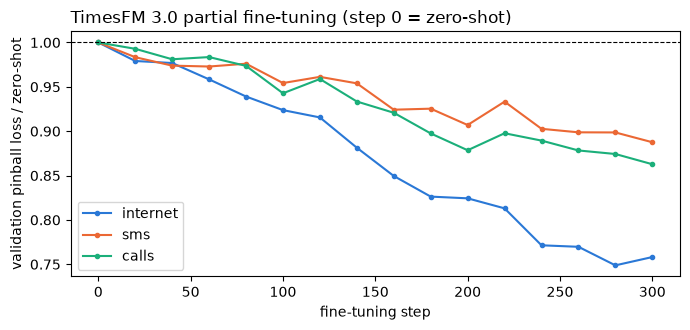

In [27]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for s, c in zip(SERIES, ["#2a78d6", "#eb6834", "#1baf7a"]):
    lg = np.array(TFM_RES[s]["ft_info"]["log"])
    ax.plot(lg[:, 0], lg[:, 2] / lg[0, 2], color=c, marker="o", ms=3, label=s)
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xlabel("fine-tuning step"); ax.set_ylabel("validation pinball loss / zero-shot")
ax.set_title("TimesFM 3.0 partial fine-tuning (step 0 = zero-shot)", loc="left"); ax.legend()
fig.tight_layout(); plt.show()

#### Ερμηνεία του fine-tuning

Εκπαιδεύεται περίπου το 10% του μοντέλου: 33.5 εκατομμύρια από τις 331 εκατομμύρια παραμέτρους (2 στρώματα και το
output head). Κάθε fine-tuning κράτησε περίπου 7 λεπτά σε CPU (300 βήματα), περίπου όσο ένα LSTM με $w = 144$.

Το validation loss μειώθηκε σε όλες τις σειρές: κατά 25% στο Internet, 11% στο SMS και 14% στα Calls. Το καλύτερο
βήμα είναι το 280 ή το 300, δηλαδή στο τέλος, οπότε με περισσότερα βήματα θα έπεφτε πιθανότατα κι άλλο. Με βάση όσα
ξέρουμε πριν από το test, η fine-tuned εκδοχή είναι λοιπόν η λογική επιλογή. Όπως όμως και με την
από-περιοδικοποίηση του LSTM (ενότητα 5.4), το validation είναι κανονικές ημέρες του Δεκεμβρίου, ενώ το test όχι.

Το inference κοστίζει περίπου 45 ms ανά πρόβλεψη σε batches των 128, με 32 threads, πολύ ακριβότερα από ARIMA και
LSTM, αλλά το zero-shot δεν χρειάζεται καμία εκπαίδευση.

Οι προβλέψεις αποτιμώνται στην ενότητα 5, με τις ίδιες αφετηρίες όπως τα υπόλοιπα μοντέλα.

## 5. Αποτίμηση και σύγκριση: RMSE, MAE, MAPE, MASE

Εδώ συγκεντρώνουμε όλα τα μοντέλα, στα ίδια σημεία του test και με τις ίδιες αφετηρίες: 10 προβλέψεις ανά σειρά και
ορίζοντα (2 σημεία αναφοράς, 2 ARIMA, 4 LSTM και 2 TimesFM). Τα δύο σημεία αναφοράς είναι απλοί κανόνες που ένα
μοντέλο πρέπει να νικά:

* Naive (persistence): $\hat y_{t+j \mid t} = y_t$, «η κίνηση θα μείνει όπως είναι τώρα»,
* Seasonal naive: $\hat y_t = y_{t-144}$, «η κίνηση θα είναι όπως χθες την ίδια ώρα».

### 5.1 Ορισμοί και τι μετράει κάθε μετρική

Με $e_t = y_t - \hat y_t$ τα σφάλματα στα $n$ σημεία του test, και $m = 144$:

| Μετρική | Τύπος | Μονάδα | Τι μετράει |
|:---|:---|:---|:---|
| RMSE | $\sqrt{\tfrac1n \sum_t e_t^2}$ | μονάδες της σειράς | τετραγωνικό σφάλμα: τα μεγάλα σφάλματα μετράνε δυσανάλογα. Ελαχιστοποιείται από τη μέση τιμή της κατανομής πρόβλεψης |
| MAE | $\tfrac1n \sum_t \lvert e_t\rvert$ | μονάδες της σειράς | τυπικό μέγεθος σφάλματος, ανθεκτικό σε ακραίες τιμές. Ελαχιστοποιείται από τη διάμεσο |
| MAPE | $\tfrac{100}{n} \sum_t \lvert e_t / y_t\rvert$ | % | μέσο σχετικό σφάλμα ανά σημείο |
| WAPE | $100 \, \sum_t \lvert e_t\rvert \,/\, \sum_t \lvert y_t\rvert$ | % | το ποσοστό του συνολικού όγκου που προβλέφθηκε λάθος (πρόσθετη μετρική) |
| MASE | $\dfrac{\tfrac1n \sum_t \lvert e_t\rvert}{\tfrac{1}{n_{tr}-m} \sum_{t=m+1}^{n_{tr}} \lvert y_t - y_{t-m}\rvert}$ | αδιάστατη | MAE του μοντέλου ως πολλαπλάσιο του MAE της seasonal naive στο train |

Ο λόγος RMSE / MAE δείχνει πόσο «βαριές» είναι οι ουρές των σφαλμάτων: για κανονικά σφάλματα είναι
$\sqrt{\pi/2} \approx 1.25$. Τιμές πάνω από αυτό σημαίνουν ότι λίγα, μεγάλα σφάλματα (οι αιχμές) κυριαρχούν.

#### MASE: γιατί χρησιμοποιείται και τι μας προσφέρει παραπάνω

Η MASE (Hyndman και Koehler, 2006) προτάθηκε ακριβώς για να διορθώσει τα προβλήματα των άλλων τριών:

Πρώτον, είναι ανεξάρτητη της κλίμακας χωρίς να εκρήγνυται. Τα RMSE και MAE δεν συγκρίνονται μεταξύ σειρών: ένα MAE
30 στο Internet (κορυφή περίπου 1300) είναι εξαιρετικό, στα SMS θα ήταν τεράστιο. Η MAPE λύνει το πρόβλημα
διαιρώντας με το $y_t$ σε κάθε σημείο, και γι' αυτό εκρήγνυται όταν $y_t \to 0$. Η MASE διαιρεί με μία σταθερά,
οπότε είναι πάντα ορισμένη, αρκεί η σειρά να μην είναι σταθερή.

Δεύτερον, έχει ενσωματωμένο σημείο αναφοράς. MASE $= 0.3$ σημαίνει ότι το μέσο σφάλμα του μοντέλου είναι το 30% του
σφάλματος του κανόνα «ό,τι έγινε χθες την ίδια ώρα». Με MASE $< 1$ το μοντέλο είναι καλύτερο από αυτόν τον κανόνα,
ενώ με MASE $\geq 1$ η πολυπλοκότητά του δεν δικαιολογείται. Τα RMSE, MAE και MAPE δεν λένε από μόνα τους αν μια
τιμή είναι καλή.

Τρίτον, είναι συμμετρική. Η MAPE τιμωρεί την υπερεκτίμηση περισσότερο από την υποεκτίμηση: αν $y_t = 100$, η
πρόβλεψη 300 δίνει 200%, ενώ καμία υποεκτίμηση δεν μπορεί να ξεπεράσει το 100%. Ένα μοντέλο που βελτιστοποιείται
για MAPE μαθαίνει να υποεκτιμά, δηλαδή να προκαλεί συμφόρηση.

Τέλος, είναι ανεξάρτητη από τη σταθερά ανωνυμοποίησης $k$, που απλοποιείται, όπως και στις MAPE και WAPE αλλά όχι
στις RMSE και MAE. Επιτρέπει έτσι σύγκριση μεταξύ σειρών και οριζόντων με έναν αριθμό, άρα και μέσο όρο πάνω σε όλα
τα κελιά ενός δικτύου.

Ένα λεπτό σημείο: ο παρονομαστής υπολογίζεται στο train, όχι στο test. Γι' αυτό η MASE συγκρίνει το μοντέλο με
μια σταθερή κλίμακα αναφοράς που δεν αλλάζει από μοντέλο σε μοντέλο, και όχι με το πόσο καλά τα πήγε η seasonal
naive στο ίδιο test (εκεί, λόγω των γιορτών, η seasonal naive έχει MASE πάνω από 1). Για το πραγματικό «κατώφλι»
χρήσιμου μοντέλου κοιτάμε επιπλέον τη σύγκριση με το Naive (ενότητα 5.6).

Ο πρώτος πίνακας δίνει τη MASE όλων των μοντέλων. Ο δεύτερος δείχνει, για κάθε σειρά και ορίζοντα, τα δύο σημεία
αναφοράς και το καλύτερο μοντέλο κάθε οικογένειας με όλες τις μετρικές. Μετά μετράμε πόσες τιμές του test είναι
κοντά στο μηδέν, για να φανεί η συμπεριφορά της MAPE.

In [28]:
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)   # .loc on the unsorted index
warnings.filterwarnings("ignore", message="Mean of empty slice")
MASE_SCALE = {s: np.mean(np.abs(Y[s][SEASON:n_train] - Y[s][:n_train - SEASON])) for s in SERIES}


def metrics(y, yhat, s):
    e = y - yhat
    pos = y > 0                                                # MAPE is undefined where y = 0
    return {"RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)),
            "MAPE %": 100 * np.mean(np.abs(e[pos] / y[pos])),
            "WAPE %": 100 * np.sum(np.abs(e)) / np.sum(np.abs(y)),
            "MASE": np.mean(np.abs(e)) / MASE_SCALE[s]}


# All forecasts: PRED[(series, horizon)][model] = (test indices, predictions)
PRED = {}
for s in SERIES:
    y = Y[s]
    P1 = {"Naive": (idx1, y[idx1 - 1]), "Seasonal naive": (idx1, y[idx1 - SEASON])}
    P5 = {"Naive": (idx5, np.repeat(y[origins5 - 1], H_LONG)), "Seasonal naive": (idx5, y[idx5 - SEASON])}
    for fam in FAMILIES:
        P1[fam], P5[fam] = (idx1, ARIMA_ROLL[(s, fam)]["h1"]), (idx5, ARIMA_ROLL[(s, fam)]["H5"])
    for key, name in [("zero", "TimesFM zero-shot"), ("ft", "TimesFM fine-tuned")]:
        P1[name], P5[name] = (idx1, TFM_RES[s][key]["h1"]), (idx5, TFM_RES[s][key]["H5"])
    PRED[(s, 1)], PRED[(s, 5)] = P1, P5
for (s, w, ds, h), v in LSTM_RES.items():
    PRED[(s, h)][f"LSTM w={w}" + (" deseason" if ds else "")] = (idx1 if h == 1 else idx5, v["pred"])
ORDER = ["Naive", "Seasonal naive", *FAMILIES, "LSTM w=10", "LSTM w=144", "LSTM w=10 deseason", "LSTM w=144 deseason",
         "TimesFM zero-shot", "TimesFM fine-tuned"]

rows = [{"series": s, "h": h, "model": m, **metrics(Y[s][idx], yhat, s)}
        for (s, h), models in PRED.items() for m, (idx, yhat) in models.items()]
FINAL = pd.DataFrame(rows).set_index(["series", "h", "model"])


def best_model(s, h, ok):
    sub = FINAL.loc[(s, h), "MASE"]
    return sub[[m for m in sub.index if ok(m)]].idxmin()


FAMILY = {"ARIMA family": lambda m: m in FAMILIES, "LSTM": lambda m: m.startswith("LSTM"),
          "TimesFM": lambda m: m.startswith("TimesFM")}
GROUP_COLOR = {"ARIMA family": "#eb6834", "LSTM": "#2a78d6", "TimesFM": "#1baf7a"}

# MASE of every model (lowest per column highlighted)
columns = [(s, h) for s in SERIES for h in (1, 5)]
display(FINAL["MASE"].unstack(["series", "h"])[columns].loc[ORDER].style.format("{:.3f}").highlight_min(color="#d6e6f9"))

# Per series and horizon: the two baselines and the best model of each family, with every metric
show = [(s, h, m) for s, h in columns
        for m in ["Naive", "Seasonal naive"] + [best_model(s, h, ok) for ok in FAMILY.values()]]
display(FINAL.loc[show].style.format({"RMSE": "{:.1f}", "MAE": "{:.1f}", "MAPE %": "{:.1f}",
                                      "WAPE %": "{:.1f}", "MASE": "{:.3f}"}))

# Why MAPE misbehaves: how many test values are (close to) zero, and the MAPE on them
for s in SERIES:
    y = Y[s][n_train:]
    m = best_model(s, 1, FAMILY["TimesFM"])
    ape = np.abs(y - PRED[(s, 1)][m][1]) / np.where(y > 0, y, np.nan)
    print(f"{s:9s} test values = 0: {np.sum(y == 0):3d}, < 1: {np.sum(y < 1):3d} | MAPE ({m}, h=1): "
          f"on y < 1 {100 * np.nanmean(ape[y < 1]):7.0f}%, on y >= 1 {100 * np.nanmean(ape[y >= 1]):5.1f}%")

internet  test values = 0:   0, < 1:   0 | MAPE (TimesFM fine-tuned, h=1): on y < 1     nan%, on y >= 1   7.4%
sms       test values = 0:   0, < 1:  80 | MAPE (TimesFM zero-shot, h=1): on y < 1    8294%, on y >= 1  31.0%
calls     test values = 0: 120, < 1: 311 | MAPE (TimesFM zero-shot, h=1): on y < 1   19048%, on y >= 1  29.1%


### 5.2 Συγκριτικός σχολιασμός των αποτελεσμάτων

Με κάθε μετρική εκτός από τη MAPE, το TimesFM είναι πρώτο σε όλες τις σειρές και στους δύο ορίζοντες. Ακολουθούν
LSTM και ARIMA με μικρές διαφορές, και μετά το Naive. Η seasonal naive είναι παντού τελευταία, με MASE 1.12 έως
1.50, γιατί ο κανόνας «όπως χθες» αποτυγχάνει στις γιορτές και στη μετάβαση από εργάσιμη σε Σαββατοκύριακο.

| MAE ($h = 1$ / $H = 5$) | Internet | SMS | Calls |
|:---|:---:|:---:|:---:|
| Naive | 36.9 / 58.6 | 15.9 / 20.1 | 9.8 / 13.4 |
| καλύτερο ARIMA ή LSTM | 33.7 / 52.5 | 15.8 / 19.5 | 9.3 / 11.4 |
| TimesFM | 29.0 / 38.2 | 13.8 / 16.4 | 8.0 / 9.3 |

Οι RMSE και MAE συμφωνούν στην κατάταξη, αλλά ο λόγος τους διαφέρει πολύ ανά σειρά. Στο Internet είναι περίπου 1.4
έως 1.6, κοντά στο 1.25 των κανονικών σφαλμάτων. Στα SMS είναι 2 έως 2.7, γιατί λίγες απότομες αιχμές δίνουν πολύ
μεγάλα σφάλματα. Εκεί SARIMA και LSTM έχουν μεγαλύτερο RMSE από το Naive (39.1 και 40.5 έναντι 32.0 για $h = 1$),
με σχεδόν ίδιο MAE: τις περισσότερες στιγμές είναι εξίσου καλά, αλλά στις αιχμές κάνουν μεγαλύτερα λάθη. Το TimesFM
είναι το μόνο που βελτιώνει και τις δύο μετρικές (RMSE 29.1).

Το TimesFM κάνει λάθος στο 6.0% (Internet), 16.5% (SMS) και 11.4% (Calls) του συνολικού όγκου για $h = 1$, και στο
7.9%, 19.5% και 13.2% για $H = 5$. Η δυσκολία ανά σειρά είναι ίδια σε όλα τα μοντέλα: Internet < Calls < SMS.

Η MAPE αποτυγχάνει, όπως αναμενόταν. Στο Internet, που δεν πλησιάζει ποτέ το μηδέν, δίνει λογικές τιμές, αλλά
αλλάζει την κατάταξη: για $H = 5$ το SARIMA (16.5%) και το LSTM (16.3%) φαίνονται χειρότερα από το Naive (14.5%),
ενώ η MASE δείχνει το αντίθετο (0.43 και 0.45 έναντι 0.48). Ο λόγος είναι ότι η MAPE δίνει το ίδιο βάρος σε ένα
σχετικό σφάλμα τη νύχτα και το μεσημέρι.

Στα SMS και Calls οι τιμές της (περίπου 300% έως 2800%) δεν έχουν νόημα. Το test έχει 80 δεκάλεπτα SMS και 311
Calls με $y_t < 1$, όπου η MAPE του TimesFM είναι 8294% και 19048%, ενώ στα υπόλοιπα είναι 31% και 29%. Ένα σφάλμα
2 μονάδων στις 4 το πρωί μετράει όσο εκατοντάδες σφάλματα το μεσημέρι. Στα Calls, $H = 5$, η MAPE θα διάλεγε
μάλιστα το SARIMA (1533%) και θα έβαζε και το Naive (1637%) πάνω από το TimesFM (1836%), ενώ η MASE του TimesFM
(0.419) είναι σαφώς η καλύτερη.

### 5.3 Σύγκριση ARIMA και LSTM

Οι Siami-Namini et al. βρήκαν ότι το LSTM μείωσε το σφάλμα κατά 84% έως 87% σε σχέση με την ARIMA, σε μηνιαίες
οικονομικές σειρές. Εδώ οι διαφορές είναι λίγα τοις εκατό (MASE του καλύτερου LSTM σε σχέση με το καλύτερο ARIMA):

| | $h = 1$ | $H = 5$ |
|:---|:---:|:---:|
| Internet | $-6\%$ (LSTM καλύτερο) | $+5\%$ (SARIMA καλύτερο) |
| SMS | $-2\%$ | $-2\%$ |
| Calls | $-1\%$ | $-4\%$ |

Η διαφορά είναι μικρότερη για αρκετούς λόγους. Οι σειρές μας είναι κυρίως γραμμικές και περιοδικές, οπότε το SARIMA
τις περιγράφει ήδη καλά, και στα 10 λεπτά κυριαρχεί η persistence: όταν το Naive έχει ήδη MASE 0.30 στο Internet,
κανένα μοντέλο δεν μπορεί να κερδίσει πολλά. Αντίθετα, οι οικονομικές σειρές του άρθρου έχουν τάσεις και αλλαγές
επιπέδου, όπου μια ARIMA με σταθερές παραμέτρους δυσκολεύεται πολύ περισσότερο. Επίσης, περίπου 6000 παράθυρα
εκπαίδευσης για ένα δίκτυο 50 χιλιάδων παραμέτρων είναι μέτριο πλήθος, και το εορταστικό test δυσκολεύει όλα τα
μοντέλα, γιατί κανένα δεν έχει δει ποτέ Χριστούγεννα.

Στο short-term το LSTM κερδίζει οριακά σε όλες τις σειρές, ενώ στο long-term το SARIMA μένει καλύτερο στο Internet
και το LSTM στα SMS και Calls. Μεταξύ των δύο ARIMA, το SARIMA είναι ίσο ή καλύτερο σχεδόν παντού. Το μέγεθος του
παραθύρου του LSTM αλλάζει ελάχιστα το $h = 1$ (Internet 0.277 και 0.276), και στο $H = 5$ το $w = 144$ βοηθά μόνο
στα Calls (0.510 έναντι 0.552). Αφού κοστίζει 10 φορές περισσότερο στην εκπαίδευση, το $w = 10$ είναι η πιο
αποδοτική επιλογή.

### 5.4 Από-περιοδικοποίηση και fine-tuning: κανονικές ημέρες ή γιορτές;

Και οι δύο τεχνικές βελτίωσαν το validation, αλλά όχι το test. Για να φανεί γιατί, χωρίζουμε το test σε κανονικές
ημέρες (17/12 έως 23/12) και εορταστική περίοδο (24/12 έως 01/01).

In [29]:
# MASE on normal days (17/12 - 23/12) and on the holidays (24/12 - 01/01)
cut = df.index.get_loc(pd.Timestamp("2013-12-24"))
rows = []
for s in SERIES:
    for h in (1, 5):
        for m in ORDER[2:]:
            idx, yhat = PRED[(s, h)][m]
            e = np.abs(Y[s][idx] - yhat) / MASE_SCALE[s]
            rows.append({"series": s, "h": h, "model": m,
                         "normal days": e[idx < cut].mean(), "holidays": e[idx >= cut].mean()})
split = pd.DataFrame(rows).set_index(["series", "h", "model"]).unstack(["series", "h"])
display(split.loc[ORDER[2:]].round(3))

# How much wider is the residual r_t = y_t - S_t in the test set than in the train set?
for s in SERIES:
    S = seasonal_profile(df.index, Y[s], n_train)
    r = Y[s] - S
    lo, hi = r[:n_train].min(), r[:n_train].max()
    z = (r[n_train:] - lo) / (hi - lo)
    print(f"{s:9s} std(r): train {r[:n_train].std():6.1f}, test {r[n_train:].std():6.1f} "
          f"(x{r[n_train:].std() / r[:n_train].std():.1f}); test points outside [0, 1]: {100 * np.mean((z < 0) | (z > 1)):.1f}%")

normal days                                    holidays  \
series                 internet           sms         calls        internet   
h                             1      5      1      5      1      5        1   
model                                                                         
SARIMA                    0.293  0.372  0.557  0.625  0.434  0.494    0.297   
ARIMA-x                   0.299  0.374  0.542  0.606  0.427  0.483    0.336   
LSTM w=10                 0.316  0.480  0.584  0.705  0.465  0.593    0.246   
LSTM w=144                0.308  0.411  0.560  0.669  0.460  0.539    0.251   
LSTM w=10 deseason        0.320  0.398  0.548  0.623  0.428  0.496    0.498   
LSTM w=144 deseason       0.315  0.398  0.550  0.620  0.428  0.491    0.458   
TimesFM zero-shot         0.279  0.345  0.537  0.579  0.403  0.429    0.206   
TimesFM fine-tuned        0.271  0.330  0.540  0.573  0.406  0.426    0.211   

                                                        
series                        sms         calls         
h                        5      1      5      1      5  
model                                                   
SARIMA               0.475  0.645  0.851  0.408  0.559  
ARIMA-x              0.559  0.661  0.866  0.425  0.582  
LSTM w=10            0.432  0.608  0.756  0.376  0.519  
LSTM w=144           0.485  0.642  0.850  0.384  0.488  
LSTM w=10 deseason   0.745  0.711  0.956  0.522  0.707  
LSTM w=144 deseason  0.788  0.719  0.995  0.531  0.700  
TimesFM zero-shot    0.287  0.510  0.648  0.328  0.411  
TimesFM fine-tuned   0.301  0.526  0.687  0.331  0.422

internet  std(r): train  101.0, test  227.0 (x2.2); test points outside [0, 1]: 5.3%
sms       std(r): train   21.5, test   73.7 (x3.4); test points outside [0, 1]: 2.8%
calls     std(r): train   16.9, test   39.8 (x2.4); test points outside [0, 1]: 5.6%


Η από-περιοδικοποίηση είναι συνολικά χειρότερη από το raw LSTM (π.χ. Internet $h = 1$: 0.40 έως 0.42 έναντι 0.28),
παρότι στο validation ήταν καλύτερη. Στις κανονικές ημέρες όμως βοηθά: στο SMS, $H = 5$, δίνει 0.62 έναντι 0.67 και
στα Calls 0.49 έναντι 0.54. Στις γιορτές η MASE σχεδόν διπλασιάζεται (Internet $H = 5$: 0.75 έως 0.79, έναντι 0.43
έως 0.49 για το raw LSTM), γιατί το προφίλ $S_t$ του train περιμένει κανονικές ημέρες. Το υπόλοιπο $r_t$ στο test
έχει 2.2 έως 3.4 φορές μεγαλύτερη τυπική απόκλιση από ό,τι στο train, και 2.8% έως 5.6% των τιμών του πέφτουν έξω
από το $[0, 1]$. Το raw LSTM, αντίθετα, ακολουθεί το πρόσφατο επίπεδο και προσαρμόζεται όταν η κίνηση πέφτει. Στο
ερώτημα της εκφώνησης η απάντηση είναι λοιπόν ότι η από-περιοδικοποίηση βοηθά όταν το μελλοντικό μοτίβο μοιάζει με
το παρελθόν και βλάπτει όταν αλλάζει.

Το fine-tuning δεν βελτίωσε το test, παρότι βελτίωσε το validation κατά 11% έως 25%. Στο Internet τα δύο είναι ίδια
(0.237 έναντι 0.238 και 0.314 έναντι 0.313), ενώ στο SMS και στα Calls το fine-tuned είναι 1% έως 3% χειρότερο.
Στις κανονικές ημέρες είναι ελαφρώς καλύτερο (Internet $H = 5$: 0.330 έναντι 0.345), και στις γιορτές χειρότερο
(Internet $H = 5$: 0.301 έναντι 0.287, SMS $H = 5$: 0.687 έναντι 0.648), γιατί προσαρμόστηκε στο μοτίβο Νοεμβρίου
και Δεκεμβρίου. Το validation, που είναι κανονικές ημέρες, δεν μπορούσε να το δείξει. Για αυτό το test το zero-shot
TimesFM αρκεί.

Το TimesFM αντέχει τις γιορτές καλύτερα από όλα: για $H = 5$ έχει MASE 0.29 (Internet), 0.65 (SMS) και 0.41
(Calls), έναντι 0.48 / 0.85 / 0.56 για το SARIMA. Ακολουθεί το επίπεδο των τελευταίων 7 ημερών, οπότε όταν η κίνηση
πέφτει η πρόβλεψη προσαρμόζεται. Στα τρία αυτά φαινόμενα η αιτία είναι ίδια: ένα μοντέλο που ταιριάζει καλύτερα στο
παρελθόν δεν προβλέπει απαραίτητα καλύτερα ένα μέλλον που συμπεριφέρεται διαφορετικά (*distribution shift*).

### 5.5 Απεικονίσεις: πραγματική σειρά και προβλέψεις στο test set

Πρώτα η MASE ανά βήμα προπορείας για $H = 5$, που δείχνει πόσο γρήγορα χειροτερεύει η πρόβλεψη. Μετά ολόκληρο το
test με το καλύτερο μοντέλο κάθε οικογένειας, το μέσο σφάλμα ανά ώρα της ημέρας, και τέλος μεγεθύνσεις σε κανονικές
ημέρες και στις γιορτές.

In [30]:
# MASE per lead step (H=5): how fast does the error grow?
lead = {}
for s in SERIES:
    for m in ["Naive", *FAMILIES, best_model(s, 5, FAMILY["LSTM"]), "TimesFM zero-shot"]:
        idx, yhat = PRED[(s, 5)][m]
        lead[(s, m)] = np.abs(Y[s][idx] - yhat).reshape(-1, H_LONG).mean(axis=0) / MASE_SCALE[s]
pd.DataFrame(lead, index=[f"lead {j+1}" for j in range(H_LONG)]).T.round(3)

lead 1  lead 2  lead 3  lead 4  lead 5
internet Naive               0.320   0.363   0.447   0.587   0.681
         SARIMA              0.297   0.343   0.434   0.516   0.561
         ARIMA-x             0.316   0.388   0.474   0.581   0.631
         LSTM w=144          0.316   0.345   0.445   0.538   0.618
         TimesFM zero-shot   0.255   0.258   0.306   0.363   0.381
sms      Naive               0.639   0.685   0.756   0.834   0.882
         SARIMA              0.680   0.709   0.768   0.812   0.789
         ARIMA-x             0.676   0.731   0.757   0.805   0.790
         LSTM w=10           0.636   0.686   0.753   0.799   0.797
         TimesFM zero-shot   0.567   0.589   0.637   0.670   0.627
calls    Naive               0.456   0.509   0.560   0.690   0.778
         SARIMA              0.453   0.502   0.518   0.583   0.597
         ARIMA-x             0.459   0.517   0.521   0.583   0.611
         LSTM w=144          0.441   0.494   0.479   0.563   0.573
         TimesFM zero-shot   0.380   0.415   0.405   0.442   0.450

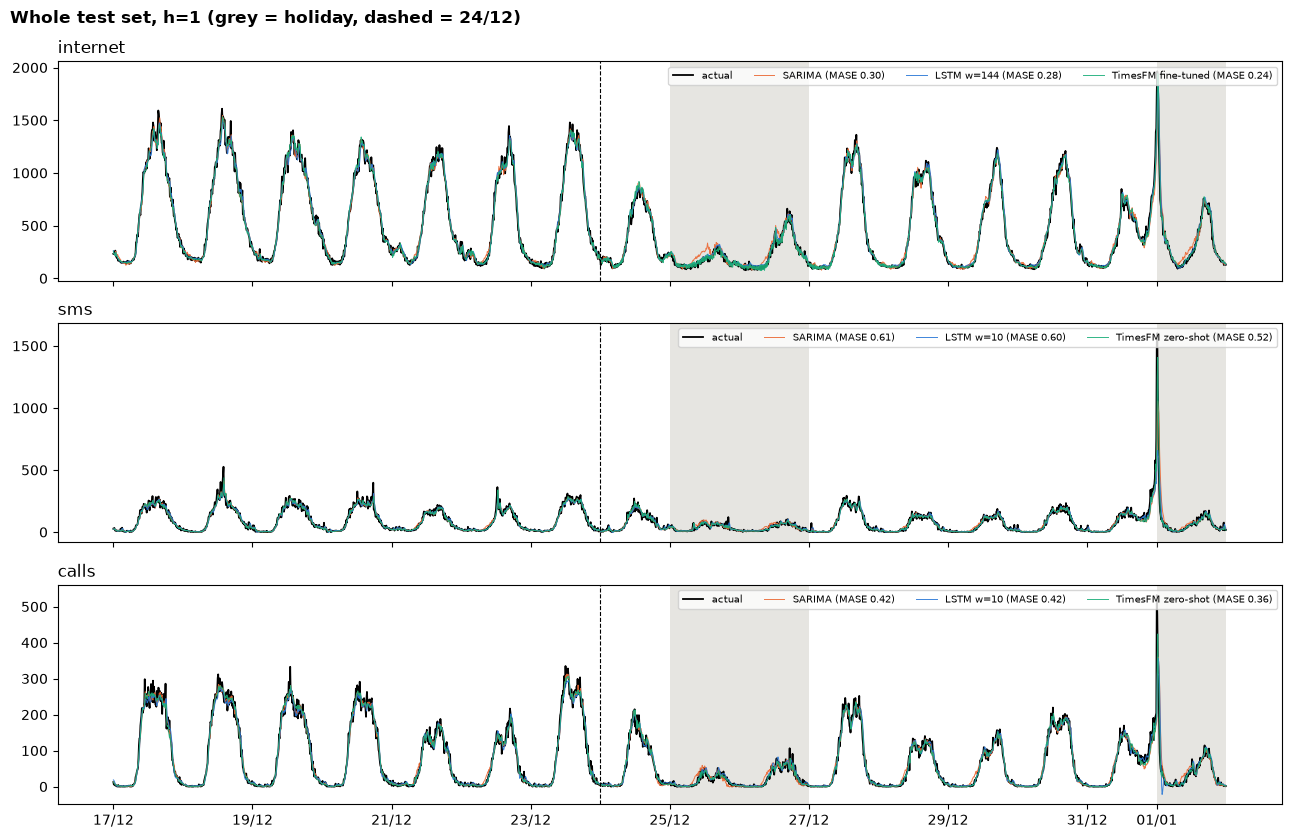

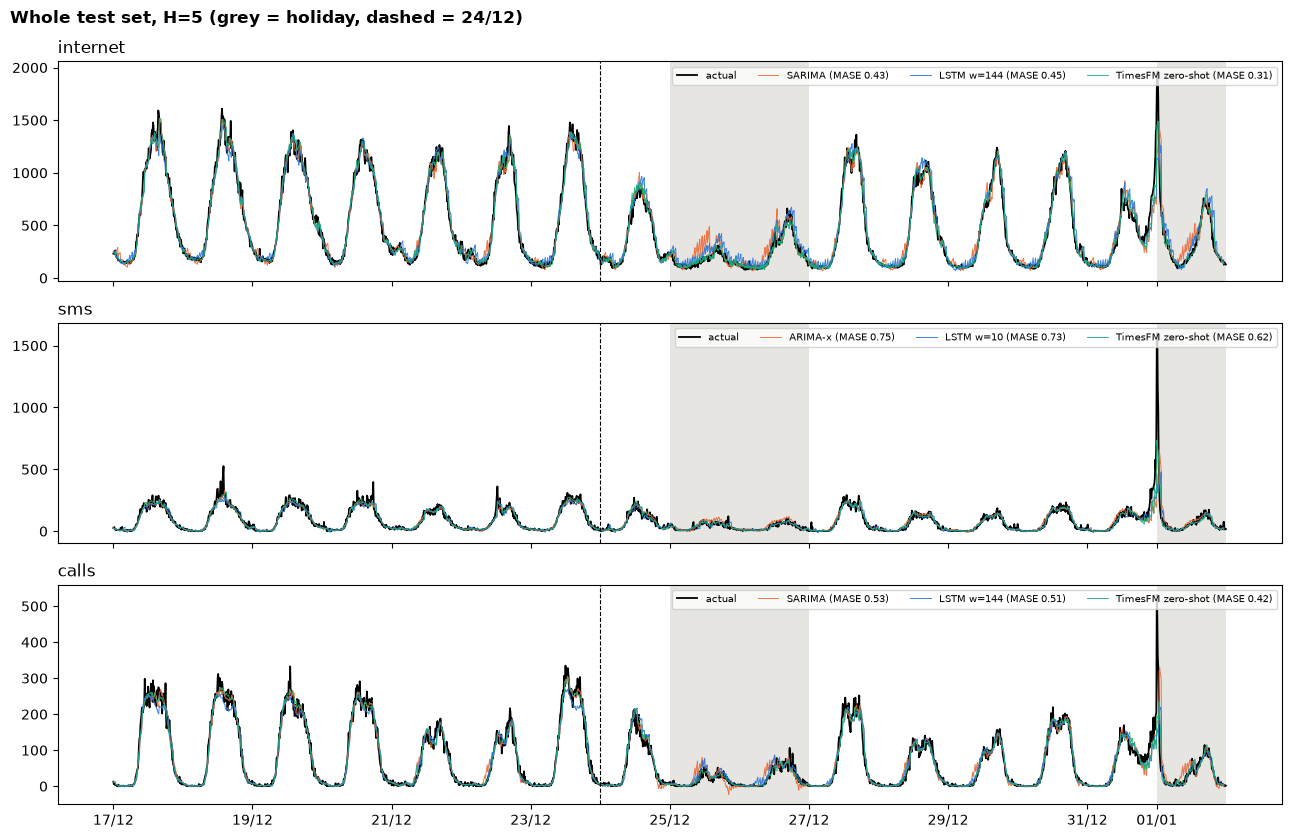

In [31]:
# Whole test set, best model of each family
for h in (1, 5):
    fig, axes = plt.subplots(len(SERIES), 1, figsize=(13, 8.5), sharex=True)
    for ax, s in zip(axes, SERIES):
        ax.plot(df.index[n_train:], Y[s][n_train:], color="k", lw=1.3, label="actual")
        for fam, ok in FAMILY.items():
            m = best_model(s, h, ok)
            idx, yhat = PRED[(s, h)][m]
            ax.plot(df.index[idx], yhat, color=GROUP_COLOR[fam], lw=0.7, alpha=0.9,
                    label=f"{m} (MASE {FINAL.loc[(s, h, m), 'MASE']:.2f})")
        for d in HOLIDAYS[HOLIDAYS >= df.index[n_train]]:
            ax.axvspan(d, d + pd.Timedelta("1D"), color="#e6e5e1", lw=0)
        ax.axvline(pd.Timestamp("2013-12-24"), color="k", lw=0.8, ls="--")
        ax.set_title(s, loc="left"); ax.legend(fontsize=7.5, ncol=4, loc="upper right")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    fig.suptitle(f"Whole test set, {'h=1' if h == 1 else 'H=5'} (grey = holiday, dashed = 24/12)",
                 x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

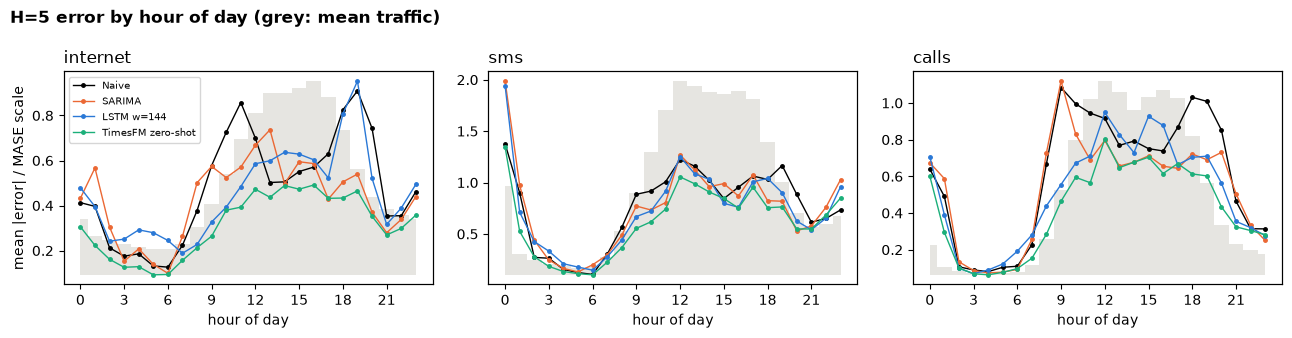

In [32]:
# Where in the day do the errors happen? Mean |error| per hour of day (H=5), in MASE units
hour = df.index[idx5].hour
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, s in zip(axes, SERIES):
    ax2 = ax.twinx()
    prof = pd.Series(Y[s][idx5]).groupby(hour).mean()
    ax2.fill_between(prof.index, prof.values, color="#e6e5e1", step="mid", lw=0)
    ax2.set_yticks([]); ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    for ok, c in [(lambda m: m == "Naive", "k")] + [(ok, GROUP_COLOR[f]) for f, ok in FAMILY.items()]:
        m = best_model(s, 5, ok)
        idx, yhat = PRED[(s, 5)][m]
        err = pd.Series(np.abs(Y[s][idx] - yhat) / MASE_SCALE[s]).groupby(hour).mean()
        ax.plot(err.index, err.values, color=c, marker="o", ms=2.5, lw=1, label=m)
    ax.set_title(s, loc="left"); ax.set_xlabel("hour of day"); ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("mean |error| / MASE scale"); axes[0].legend(fontsize=7.5)
fig.suptitle("H=5 error by hour of day (grey: mean traffic)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

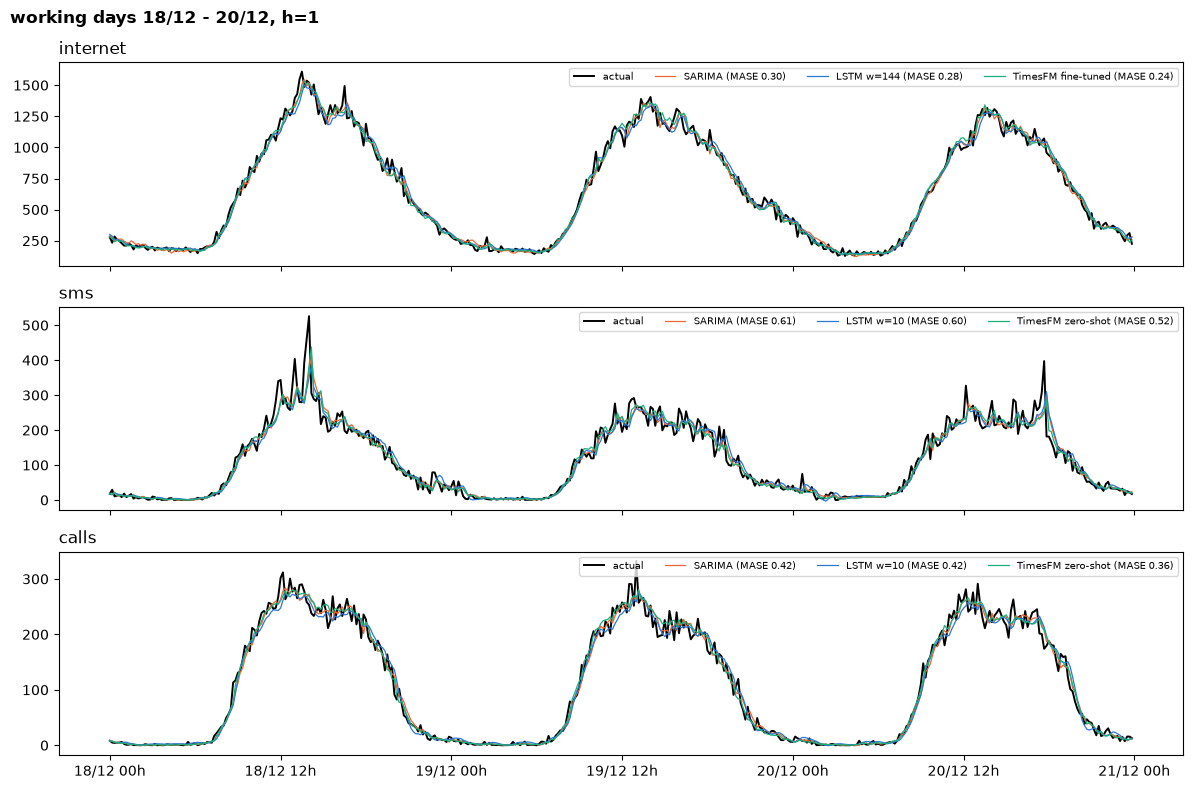

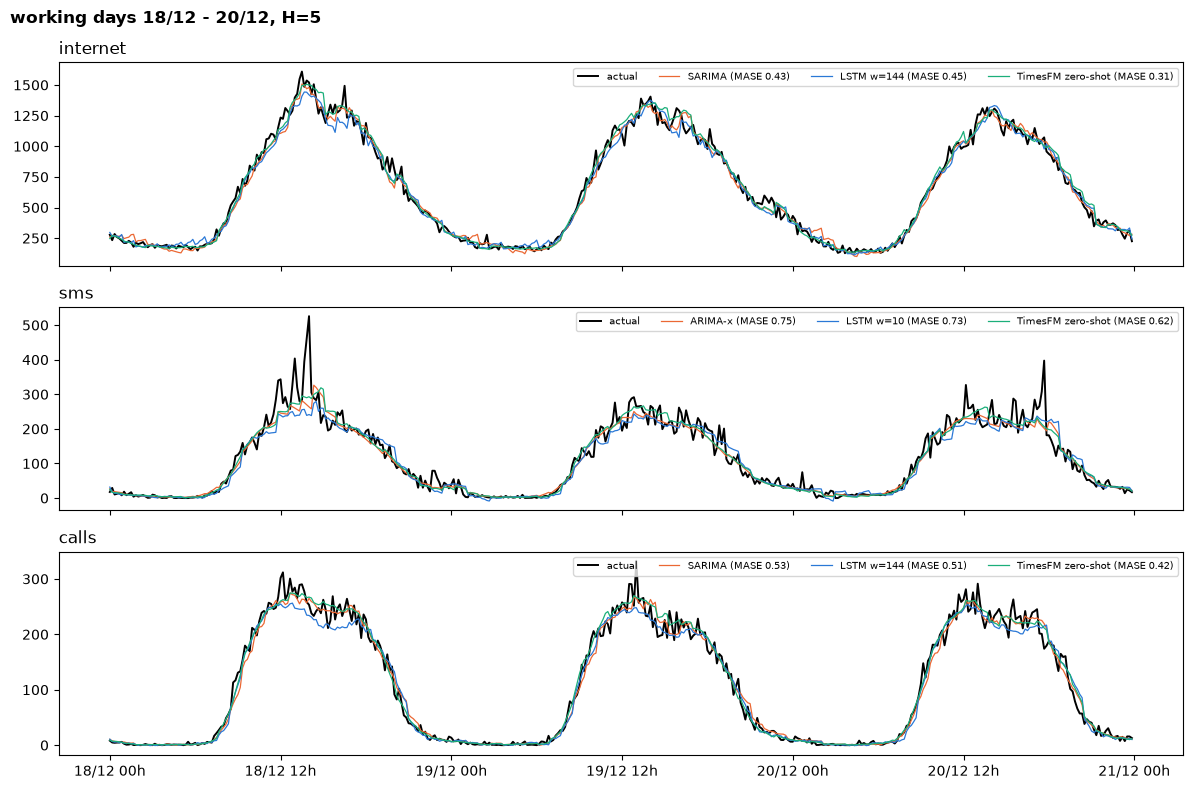

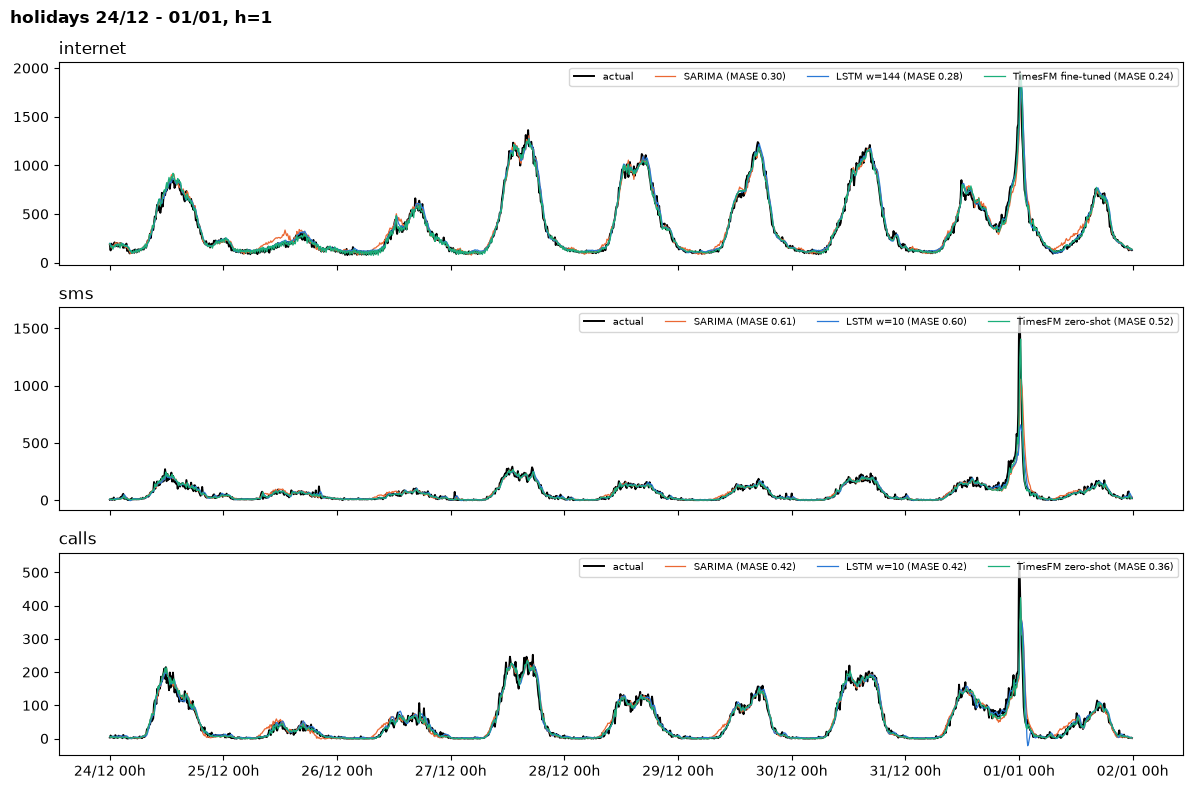

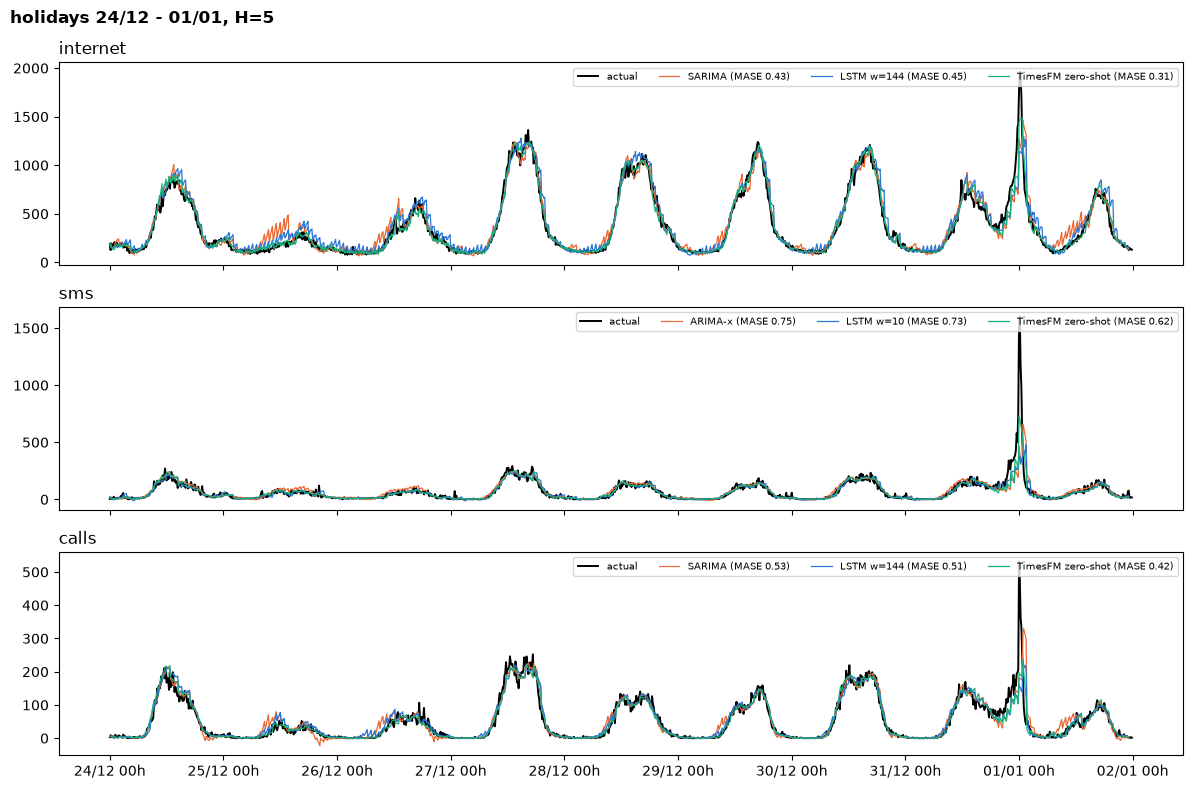

In [33]:
# Close-ups: best model of each family on normal working days and on the holidays
for period, title in [(slice("2013-12-18", "2013-12-20"), "working days 18/12 - 20/12"),
                      (slice("2013-12-24", "2014-01-01"), "holidays 24/12 - 01/01")]:
    for h in (1, 5):
        fig, axes = plt.subplots(len(SERIES), 1, figsize=(12, 8), sharex=True)
        for ax, s in zip(axes, SERIES):
            act_ = df[s].loc[period]
            ax.plot(act_.index, act_.values, color="k", lw=1.4, label="actual")
            for grp, ok in FAMILY.items():
                m = best_model(s, h, ok)
                idx, yhat = PRED[(s, h)][m]
                ser = pd.Series(yhat, index=df.index[idx]).loc[period]
                ax.plot(ser.index, ser.values, color=GROUP_COLOR[grp], lw=0.9,
                        label=f"{m} (MASE {FINAL.loc[(s, h, m), 'MASE']:.2f})")
            ax.set_title(s, loc="left"); ax.legend(fontsize=7.5, ncol=4, loc="upper right")
        axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
        fig.suptitle(f"{title}, {'h=1' if h == 1 else 'H=5'}", x=0.01, ha="left", fontweight="bold")
        fig.tight_layout(); plt.show()

#### Τι δείχνουν οι απεικονίσεις

Η πρόβλεψη χειροτερεύει με την προπορεία με διαφορετικό ρυθμό. Στο Internet η MASE του TimesFM πηγαίνει από 0.26
στο lead 1 σε 0.38 στο lead 5 (+49%), του SARIMA από 0.30 σε 0.56, και του Naive από 0.32 σε 0.68. Το TimesFM ξέρει
πώς συνεχίζεται το ημερήσιο σχήμα, χάρη στο context της μίας εβδομάδας.

Όλα τα μοντέλα πιάνουν πολύ καλά το ημερήσιο σχήμα. Στις κανονικές ημέρες οι προβλέψεις σχεδόν καλύπτουν την
πραγματική σειρά, και οι διαφορές των μετρικών (π.χ. MASE 0.24 έναντι 0.30) αφορούν το ύψος της κορυφής και τις
απότομες μεταβολές.

Τα σφάλματα συγκεντρώνονται στις ώρες κίνησης. Από τις 2 έως τις 7 το πρωί όλα τα μοντέλα έχουν πολύ μικρό σφάλμα,
και μετά το σφάλμα ακολουθεί περίπου το επίπεδο της κίνησης (γκρι). Αυτό έχει σημασία τηλεπικοινωνιακά, γιατί στις
ώρες αιχμής ένα λάθος προκαλεί συμφόρηση.

Για το Naive το δύσκολο σημείο είναι οι μεταβάσεις. Στο Internet το σφάλμα του κορυφώνεται στην πρωινή άνοδο (10:00
έως 11:00) και στην απογευματινή πτώση (18:00 έως 20:00). Εκεί κερδίζουν τα μοντέλα με περιοδικότητα: στις 19:00 το
SARIMA (0.54) και το TimesFM (0.47) έχουν περίπου το μισό σφάλμα από το Naive (0.91). Το LSTM $w = 144$ μένει στο
επίπεδο του Naive (0.95), που εξηγεί γιατί υστερεί του SARIMA στο Internet για $H = 5$. Το TimesFM είναι χαμηλότερα
σχεδόν σε κάθε ώρα.

Τις αιχμές δεν τις προβλέπει κανένα μοντέλο. Η Πρωτοχρονιά (Internet περίπου 2000, SMS περίπου 1600, Calls περίπου
500) υποεκτιμάται από όλα και πιάνεται μόνο μερικώς, με καθυστέρηση, και στα SMS αυτή η μία νύχτα κάνει την ώρα
00:00 τη χειρότερη της ημέρας. Είναι το γνωστό lag effect: μια αιχμή χωρίς προηγούμενο εμφανίζεται στην
πρόβλεψη ένα βήμα αργότερα.

Στις γιορτές τα μοντέλα του train περιμένουν κανονική ημέρα. Στα Χριστούγεννα (25/12, 16:00 έως 20:00), για
$H = 5$, το SARIMA προβλέπει Internet κατά μέσο όρο 276 ενώ η πραγματική τιμή είναι 232 και το TimesFM δίνει 239.
Στα Calls στις 26/12 οι προβλέψεις του SARIMA πέφτουν ως το $-10.9$, ενώ του TimesFM μένουν γύρω από το μηδέν.

### 5.6 Πότε το forecasting «έχει επιτύχει»;

Μία τιμή μετρικής από μόνη της δεν λέει αν η πρόβλεψη πέτυχε. Χρειάζεται ένα κριτήριο σε σχέση με κάτι.
Προτείνουμε τρία, από το πιο χαλαρό στο πιο αυστηρό:

1. MASE $< 1$: το μοντέλο είναι καλύτερο από τη seasonal naive του train. Είναι αναγκαίο αλλά πολύ χαλαρό
   κριτήριο: εδώ το πληρούν όλα τα μοντέλα εκτός από τη seasonal naive, ακόμη και το Naive (0.30 έως 0.76), γιατί σε 10 λεπτά η τελευταία τιμή
   είναι πολύ καλύτερη πρόβλεψη από την τιμή χθες.
2. Σαφής βελτίωση έναντι του Naive (persistence). Αυτό είναι το πραγματικό κατώφλι: ένα μοντέλο αξίζει να
   χρησιμοποιηθεί μόνο αν κάνει κάτι καλύτερο από το «η κίνηση θα μείνει όπως είναι», που δεν κοστίζει τίποτα.
   Ορίζουμε:
   * επιτυχία: MAE τουλάχιστον 10% μικρότερο από το Naive,
   * οριακή: βελτίωση από 0% έως 10%: υπάρχει, αλλά δύσκολα δικαιολογεί το κόστος ενός μοντέλου,
   * αποτυχία: καμία βελτίωση.

   Το όριο του 10% είναι επιλογή μας: θέλουμε μια διαφορά που φαίνεται και πρακτικά, και όχι μόνο στην τρίτη
   δεκαδική της MASE.
3. Τηλεπικοινωνιακό κριτήριο: το σφάλμα πρέπει να είναι μικρό σε σχέση με το περιθώριο χωρητικότητας
   (headroom) που κρατά ο πάροχος, συνήθως 15% έως 30% πάνω από την αναμενόμενη ζήτηση. Αυτό το κρίνουμε με τη WAPE
   και με τα διαστήματα πρόβλεψης (ενότητα 5.8).

Ο πρώτος πίνακας δίνει τη βελτίωση κάθε μοντέλου έναντι του Naive (σε %, θετικό = καλύτερο). Ο δεύτερος εφαρμόζει
το κριτήριο 2 στο καλύτερο μοντέλο κάθε οικογένειας.

In [34]:
# Improvement over the persistence (Naive) forecast, % of its MAE (positive = better than Naive)
gain = {}
for (s, h, m), v in FINAL["MASE"].items():
    if m not in ("Naive", "Seasonal naive"):
        gain[(m, s, h)] = 100 * (1 - v / FINAL.loc[(s, h, "Naive"), "MASE"])
gain = pd.Series(gain).unstack([1, 2])[columns].loc[ORDER[2:]]
display(gain.style.format("{:+.1f}").background_gradient(cmap="RdYlGn", vmin=-30, vmax=30))


def verdict(s, h, m):
    mase, g = FINAL.loc[(s, h, m), "MASE"], 100 * (1 - FINAL.loc[(s, h, m), "MASE"] / FINAL.loc[(s, h, "Naive"), "MASE"])
    if mase >= 1 or g <= 0:
        return "fail"
    return "success" if g >= 10 else "marginal"


pd.DataFrame({(s, h): {fam: f"{best_model(s, h, ok)}: {verdict(s, h, best_model(s, h, ok))}"
                       for fam, ok in FAMILY.items()} for s, h in columns})

internet                              \
                                        1                           5   
ARIMA family             SARIMA: marginal             SARIMA: success   
LSTM                 LSTM w=144: marginal        LSTM w=144: marginal   
TimesFM       TimesFM fine-tuned: success  TimesFM zero-shot: success   

                                     sms                              \
                                       1                           5   
ARIMA family                SARIMA: fail           ARIMA-x: marginal   
LSTM                 LSTM w=10: marginal         LSTM w=10: marginal   
TimesFM       TimesFM zero-shot: success  TimesFM zero-shot: success   

                                   calls                              
                                       1                           5  
ARIMA family            SARIMA: marginal             SARIMA: success  
LSTM                 LSTM w=10: marginal         LSTM w=144: success  
TimesFM       TimesFM zero-shot: success  TimesFM zero-shot: success

#### Αποτίμηση ανά περίπτωση

| | Internet $h = 1$ | Internet $H = 5$ | SMS $h = 1$ | SMS $H = 5$ | Calls $h = 1$ | Calls $H = 5$ |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| ARIMA (καλύτερο) | οριακή (+2.2%) | επιτυχία (+10.3%) | αποτυχία (-0.8%) | οριακή (+1.0%) | οριακή (+4.3%) | επιτυχία (+11.4%) |
| LSTM (καλύτερο) | οριακή (+8.6%) | οριακή (+5.7%) | οριακή (+0.7%) | οριακή (+3.3%) | οριακή (+5.3%) | επιτυχία (+14.8%) |
| TimesFM | επιτυχία (+21.5%) | επιτυχία (+34.8%) | επιτυχία (+13.3%) | επιτυχία (+18.6%) | επιτυχία (+17.7%) | επιτυχία (+30.1%) |

Στο short-term μόνο το TimesFM πετυχαίνει. Τα ARIMA και LSTM είναι οριακά, και στα SMS το καλύτερο ARIMA δεν νικά
καν το Naive, γιατί σε 10 λεπτά η persistence είναι πολύ δυνατή. Στο long-term πετυχαίνουν τα μοντέλα που ξέρουν
την περιοδικότητα: το SARIMA στο Internet και στα Calls, το LSTM $w = 144$ στα Calls και το TimesFM παντού. Το
SARIMA περνά το όριο του 10% οριακά (+10.3% και +11.4%).

Τα SMS είναι η πιο δύσκολη σειρά, γιατί κυριαρχούνται από απρόβλεπτες αιχμές, και μόνο το TimesFM βελτιώνει
σημαντικά το Naive. Η από-περιοδικοποιημένη LSTM αποτυγχάνει παντού (-2% έως -39%), εξαιτίας των γιορτών (ενότητα
5.4).

Με το κριτήριο 3, στο Internet το TimesFM κάνει λάθος στο 6.0% του όγκου για $h = 1$ και 7.9% για $H = 5$, πολύ
κάτω από ένα τυπικό headroom 15% έως 20%. Στα SMS (16.5% και 19.5%) το σφάλμα είναι συγκρίσιμο με το headroom,
οπότε χρειάζεται και το διάστημα πρόβλεψης, αν και ο όγκος τους είναι πολύ μικρός σε σχέση με το Internet.

Συνολικά, με αυστηρό κριτήριο το forecasting πετυχαίνει σε όλες τις περιπτώσεις μόνο με το TimesFM. Το SARIMA
πετυχαίνει μόνο στο long-term σε Internet και Calls, το LSTM μόνο στο long-term σε Calls, και στο short-term κανένα
από τα δύο δεν ξεπερνά το οριακό.

### 5.7 Έχουν οι μετρικές φυσική ερμηνεία;

| Μετρική | Φυσική ερμηνεία; |
|:---|:---|
| RMSE, MAE | Όχι απόλυτη. Εκφράζονται στις μονάδες της σειράς, αλλά οι τιμές του dataset είναι πολλαπλασιασμένες με την άγνωστη σταθερά $k$ (ανωνυμοποίηση). Ένα MAE 29 στο Internet δεν είναι 29 MB ή 29 λεπτά κλήσεων. Ερμηνεύονται μόνο σχετικά: π.χ. MAE 29 όταν η κορυφή της ημέρας είναι 1200 έως 1600, δηλαδή περίπου 2% της κορυφής. Αν ήταν γνωστό το $k$, θα είχαν άμεση ερμηνεία ως «πόση χωρητικότητα λείπει ή περισσεύει ανά δεκάλεπτο» |
| MAPE | Θεωρητικά ναι (μέσο σχετικό σφάλμα ανά σημείο), αλλά στην πράξη όχι εδώ: εκρήγνυται στις νυχτερινές τιμές κοντά στο μηδέν και δεν αντιστοιχεί σε κάτι που ενδιαφέρει τον πάροχο |
| WAPE | Ναι: το ποσοστό του συνολικού όγκου κίνησης που προβλέφθηκε λάθος. Ανεξάρτητη από το $k$, και συγκρίνεται απευθείας με το περιθώριο χωρητικότητας |
| MASE | Όχι φυσική, αλλά λειτουργική: «πόσες φορές μικρότερο είναι το σφάλμα από έναν απλό κανόνα». Αδιάστατη και ανεξάρτητη από το $k$, και γι' αυτό η κατάλληλη για σύγκριση μοντέλων, σειρών και οριζόντων |
| Κάλυψη διαστήματος (5.8) | Ναι: η συχνότητα με την οποία η πραγματική ζήτηση ξεπερνά το όριο που θα διαστασιολογούσαμε, δηλαδή η πιθανότητα συμφόρησης (παραβίασης SLA) |

Για τη σύγκριση των μοντέλων εδώ η MASE είναι η κατάλληλη κύρια μετρική. Για την ερμηνεία στη γλώσσα του δικτύου
η WAPE και η κάλυψη των διαστημάτων.

### 5.8 Bonus: διαστήματα πρόβλεψης 95% για το short-term

Μια σημειακή πρόβλεψη δεν λέει πόσο σίγουροι είμαστε. Για τη διαστασιολόγηση πόρων χρειάζεται ένα διάστημα
πρόβλεψης (prediction interval): ένα εύρος που περιέχει τη μελλοντική τιμή με πιθανότητα 95%. (Στη βιβλιογραφία
συχνά λέγεται «διάστημα εμπιστοσύνης», αλλά αυστηρά το διάστημα εμπιστοσύνης αφορά μια παράμετρο, ενώ εδώ αφορά μια
μελλοντική τιμή.)

ARIMA. Για $h = 1$ το σφάλμα πρόβλεψης είναι ακριβώς η καινοτομία $\varepsilon_{t+1}$, γιατί όλες οι
προηγούμενες τιμές και τα κατάλοιπα είναι γνωστά. Με την υπόθεση $\varepsilon_t \sim N(0, \sigma^2)$:

$$\hat y_{t+1 \mid t} \;\pm\; 1.96 \, \hat\sigma, \qquad \hat\sigma^2 = \text{η διασπορά που εκτιμήθηκε στο train}$$

Το διάστημα έχει σταθερό πλάτος, ίδιο τη νύχτα και στην κορυφή. Υπολογίζουμε το διάστημα και για τα δύο
μοντέλα της οικογένειας.

TimesFM. Το μοντέλο δίνει απευθείας τα ποσοστημόρια $q_{0.1}, \dots, q_{0.9}$, οπότε το 80% διάστημα είναι
απλώς το $[q_{0.1}, q_{0.9}]$, χωρίς καμία υπόθεση. Για το 95% χρειαζόμαστε τα $q_{0.025}$ και $q_{0.975}$, που το
μοντέλο δεν δίνει. Τα προσεγγίζουμε υποθέτοντας κανονική κατανομή γύρω από τη διάμεσο:

$$\hat\sigma_t = \frac{q_{0.9} - q_{0.1}}{2 \cdot 1.2816}, \qquad q_{0.5} \;\pm\; 1.96 \, \hat\sigma_t$$

όπου 1.2816 είναι το ποσοστημόριο 0.9 της τυπικής κανονικής, και το 1.96 είναι το ίδιο όριο του 95% με την ενότητα 2.3. Εδώ το $\hat\sigma_t$ αλλάζει σε κάθε σημείο: το
μοντέλο εκτιμά διαφορετική αβεβαιότητα για κάθε πρόβλεψη.

#### Τι μετράμε
* Κάλυψη (coverage): το ποσοστό των σημείων του test όπου η πραγματική τιμή πέφτει μέσα στο διάστημα. Για καλά
  βαθμονομημένο (calibrated) 95% διάστημα περιμένουμε περίπου 95%. Λιγότερο σημαίνει υπερβολική αυτοπεποίθηση,
  περισσότερο σημαίνει ότι το διάστημα είναι άσκοπα φαρδύ. Τη χωρίζουμε επίσης σε κανονικές ημέρες και γιορτές, και
  σε σημεία κάτω και πάνω από το διάστημα.
* Μέσο πλάτος (σε μονάδες της κλίμακας MASE): ανάμεσα σε δύο διαστήματα με σωστή κάλυψη, το στενότερο είναι
  πιο χρήσιμο (*sharpness*).
* Ποσοστό σημείων με αρνητικό κάτω όριο: η κίνηση δεν μπορεί να είναι αρνητική.

In [35]:
Z95 = 1.959964                                                 # standard normal 97.5% quantile


def tfm_interval(q, quantiles, z=Z95):
    """Gaussian approximation around the median: sigma from the 10%-90% quantile spread."""
    qs = list(np.round(quantiles, 3))
    q10, q50, q90 = q[:, qs.index(0.1)], q[:, qs.index(0.5)], q[:, qs.index(0.9)]
    sig = (q90 - q10) / (2 * 1.281552)
    return q50 - z * sig, q50 + z * sig, q10, q90


PI = {}
for s in SERIES:
    for fam in FAMILIES:                                       # one-step error = innovation, variance sigma^2
        sd = np.sqrt(BEST.loc[(s, fam), "params"][-1])
        h1 = ARIMA_ROLL[(s, fam)]["h1"]
        PI[(s, fam, "95%")] = (h1 - Z95 * sd, h1 + Z95 * sd)
    for key, name in [("zero", "TimesFM zero-shot"), ("ft", "TimesFM fine-tuned")]:
        t = TFM_RES[s][key]
        lo, hi, q10, q90 = tfm_interval(t["q_h1"], t["quantiles"])
        PI[(s, name, "95%")] = (lo, hi)
        PI[(s, name, "80%")] = (q10, q90)

rows = []
for (s, m, lev), (lo, hi) in PI.items():
    y = Y[s][idx1]
    inside = (y >= lo) & (y <= hi)
    rows.append({"series": s, "model": m, "level": lev, "coverage %": 100 * inside.mean(),
                 "normal days %": 100 * inside[idx1 < cut].mean(), "holidays %": 100 * inside[idx1 >= cut].mean(),
                 "below lower %": 100 * np.mean(y < lo), "above upper %": 100 * np.mean(y > hi),
                 "mean width / MASE scale": np.mean(hi - lo) / MASE_SCALE[s],
                 "lower bound < 0 %": 100 * np.mean(lo < 0)})
COVERAGE = pd.DataFrame(rows).set_index(["series", "model", "level"])
COVERAGE.round(2)

coverage %  normal days %  holidays %  \
series   model              level                                          
internet SARIMA             95%         98.13          98.41       97.92   
         ARIMA-x            95%         97.57          97.82       97.38   
         TimesFM zero-shot  95%         92.14          92.36       91.98   
                            80%         74.61          76.79       72.92   
         TimesFM fine-tuned 95%         95.18          94.25       95.91   
                            80%         81.16          82.54       80.09   
sms      SARIMA             95%         91.80          91.07       92.36   
         ARIMA-x            95%         91.41          91.07       91.67   
         TimesFM zero-shot  95%         91.88          92.96       91.05   
                            80%         76.65          76.59       76.70   
         TimesFM fine-tuned 95%         90.41          91.07       89.89   
                            80%         75.91          75.69       76.08   
calls    SARIMA             95%         92.53          91.47       93.36   
         ARIMA-x            95%         92.10          90.48       93.36   
         TimesFM zero-shot  95%         92.53          93.25       91.98   
                            80%         79.51          79.76       79.32   
         TimesFM fine-tuned 95%         93.19          93.85       92.67   
                            80%         77.65          75.89       79.01   

                                   below lower %  above upper %  \
series   model              level                                 
internet SARIMA             95%             0.61           1.26   
         ARIMA-x            95%             0.91           1.52   
         TimesFM zero-shot  95%             2.86           4.99   
                            80%            11.94          13.45   
         TimesFM fine-tuned 95%             1.56           3.26   
                            80%            11.28           7.55   
sms      SARIMA             95%             3.26           4.95   
         ARIMA-x            95%             3.34           5.25   
         TimesFM zero-shot  95%             1.17           6.94   
                            80%             9.64          13.72   
         TimesFM fine-tuned 95%             0.87           8.72   
                            80%            10.50          13.59   
calls    SARIMA             95%             3.34           4.12   
         ARIMA-x            95%             3.30           4.60   
         TimesFM zero-shot  95%             1.48           5.99   
                            80%             7.86          12.63   
         TimesFM fine-tuned 95%             1.48           5.34   
                            80%            12.15          10.20   

                                   mean width / MASE scale  lower bound < 0 %  
series   model              level                                              
internet SARIMA             95%                       2.15              11.55  
         ARIMA-x            95%                       2.16              11.89  
         TimesFM zero-shot  95%                       1.07               0.00  
                            80%                       0.70               0.00  
         TimesFM fine-tuned 95%                       1.26               0.00  
                            80%                       0.82               0.00  
sms      SARIMA             95%                       2.85              44.14  
         ARIMA-x            95%                       2.80              44.57  
         TimesFM zero-shot  95%                       2.24              23.05  
                            80%                       1.47              10.98  
         TimesFM fine-tuned 95%                       2.27              20.79  
                            80%                       1.49               6.68  
calls    SARIMA             95%                      

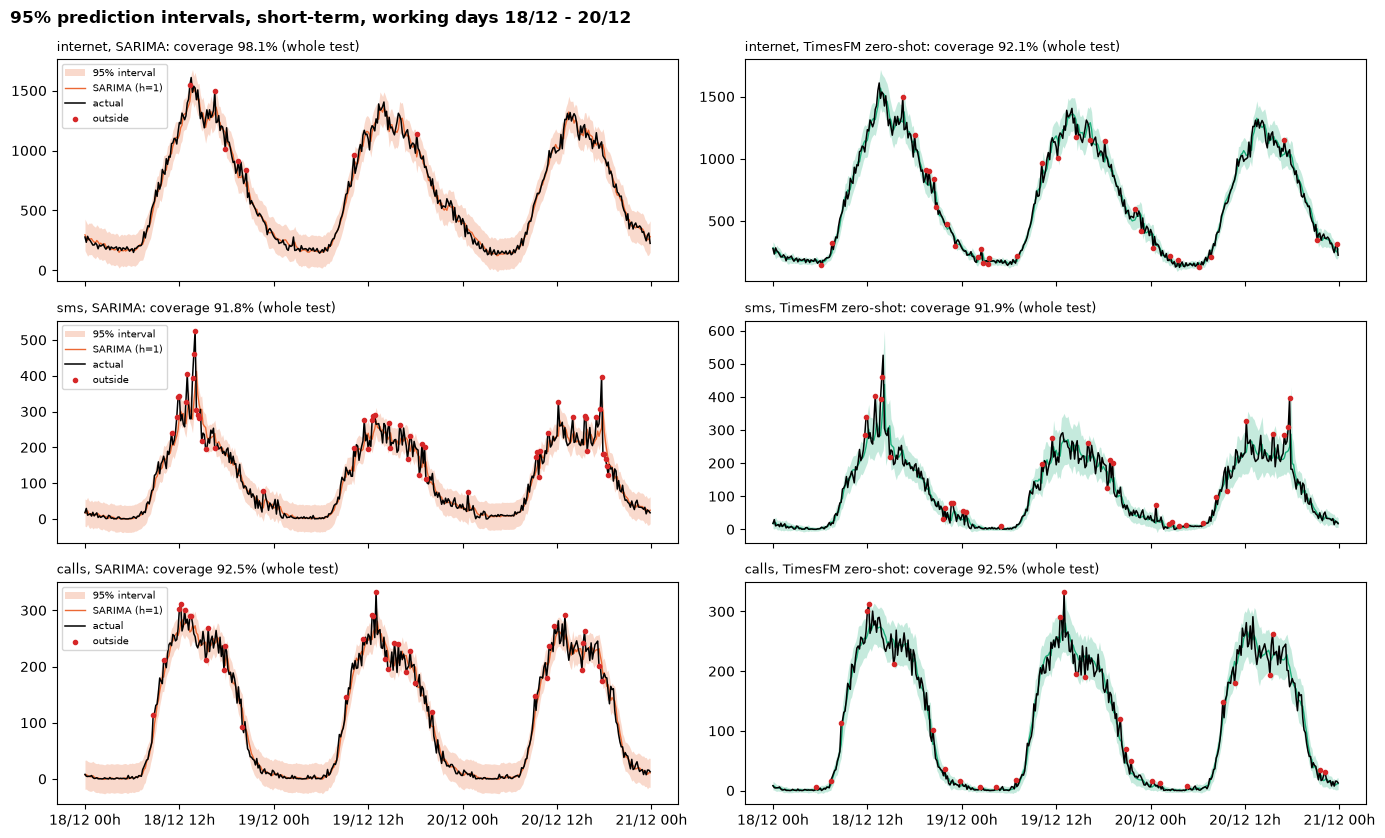

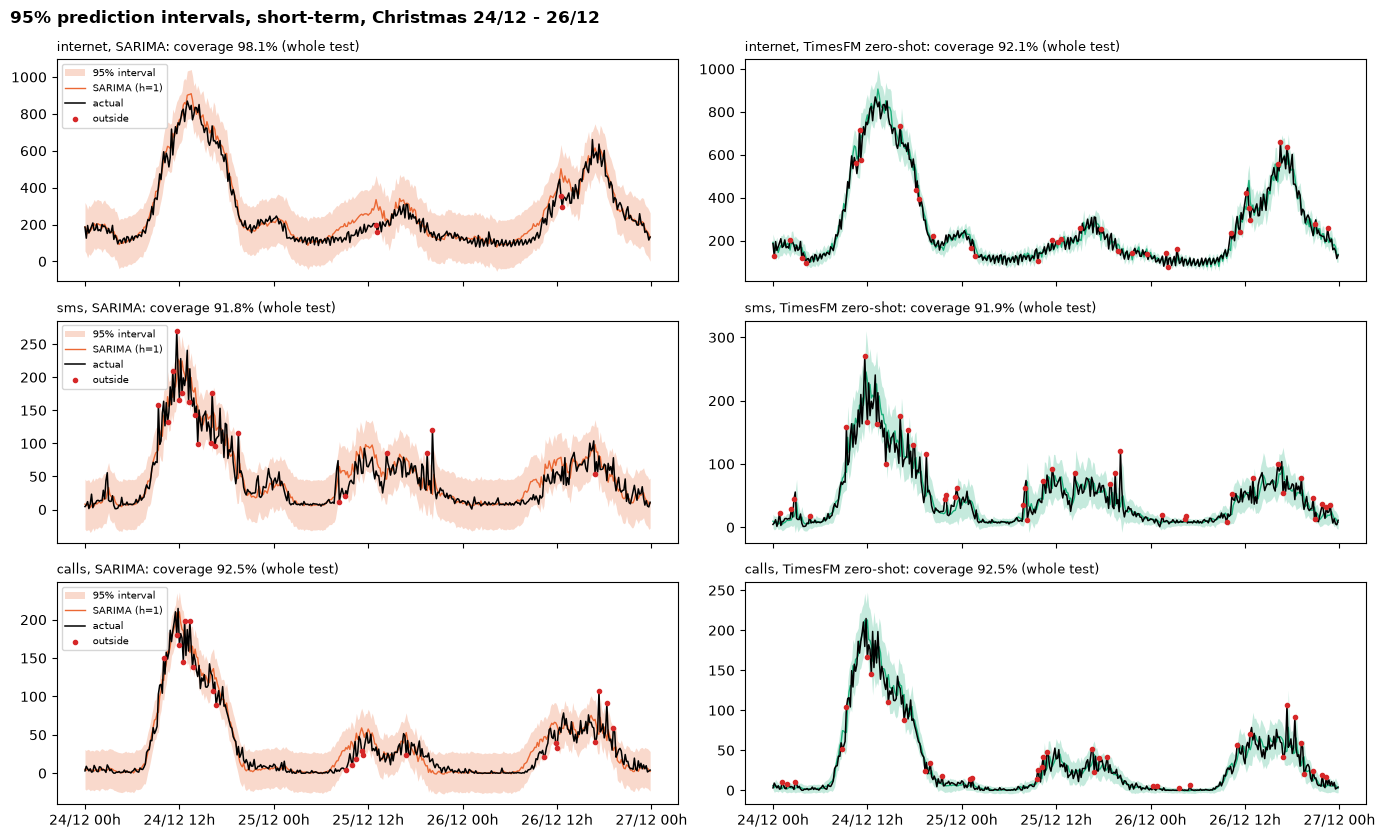

In [36]:
for period, title in [(slice("2013-12-18", "2013-12-20"), "working days 18/12 - 20/12"),
                      (slice("2013-12-24", "2013-12-26"), "Christmas 24/12 - 26/12")]:
    fig, axes = plt.subplots(len(SERIES), 2, figsize=(14, 8.5), sharex=True)
    tt = df.index[idx1]
    sel = (tt >= pd.Timestamp(period.start)) & (tt < pd.Timestamp(period.stop) + pd.Timedelta("1D"))
    for i, s in enumerate(SERIES):
        m_ar = best_model(s, 1, FAMILY["ARIMA family"])
        for ax, m, c in [(axes[i, 0], m_ar, GROUP_COLOR["ARIMA family"]),
                         (axes[i, 1], "TimesFM zero-shot", GROUP_COLOR["TimesFM"])]:
            lo, hi = PI[(s, m, "95%")]
            ax.fill_between(tt[sel], lo[sel], hi[sel], color=c, alpha=0.25, lw=0, label="95% interval")
            ax.plot(tt[sel], PRED[(s, 1)][m][1][sel], color=c, lw=1, label=f"{m} (h=1)")
            ax.plot(tt[sel], Y[s][idx1][sel], color="k", lw=1.1, label="actual")
            out = sel & ((Y[s][idx1] < lo) | (Y[s][idx1] > hi))
            ax.scatter(tt[out], Y[s][idx1][out], color="#d62728", s=9, zorder=3, label="outside")
            ax.set_title(f"{s}, {m}: coverage {COVERAGE.loc[(s, m, '95%'), 'coverage %']:.1f}% (whole test)",
                         loc="left", fontsize=9.5)
        axes[i, 0].legend(fontsize=7, loc="upper left")
    for ax in axes[-1]:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
    fig.suptitle(f"95% prediction intervals, short-term, {title}", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

#### Ερμηνεία των διαστημάτων

| 95% διάστημα, $h = 1$ | Internet | SMS | Calls |
|:---|:---:|:---:|:---:|
| ARIMA: κάλυψη | 97.6% έως 98.1% | 91.4% έως 91.8% | 92.1% έως 92.5% |
| ARIMA: μέσο πλάτος / κλίμακα MASE | 2.15 έως 2.16 | 2.80 έως 2.85 | 2.27 έως 2.31 |
| TimesFM zero-shot: κάλυψη | 92.1% | 91.9% | 92.5% |
| TimesFM fine-tuned: κάλυψη | 95.2% | 90.4% | 93.2% |
| TimesFM: μέσο πλάτος / κλίμακα MASE | 1.07 έως 1.26 | 2.24 έως 2.27 | 1.63 έως 1.72 |
| TimesFM 80% $[q_{0.1}, q_{0.9}]$: κάλυψη | 74.6% / 81.2% | 76.6% / 75.9% | 79.5% / 77.6% |

Το πλάτος της ARIMA είναι σταθερό. Τη νύχτα το διάστημα είναι υπερβολικά φαρδύ και επεκτείνεται κάτω από το μηδέν:
το κάτω όριο είναι αρνητικό στο 12% των σημείων για το Internet και στο 44% έως 47% για SMS και Calls. Στην κορυφή
είναι πολύ στενό, και εκεί συγκεντρώνονται τα σημεία εκτός διαστήματος (κόκκινα στο γράφημα). Στο Internet η κάλυψη
είναι 98%, πάνω από το ζητούμενο, γιατί το $\hat\sigma$ περιλαμβάνει τα μεγάλα σφάλματα των ωρών αιχμής. Στα SMS
και Calls είναι 91% έως 93%, λίγο κάτω από 95%, λόγω των βαριών ουρών.

Τα διαστήματα του TimesFM αντίθετα προσαρμόζονται: είναι στενά τη νύχτα και φαρδύτερα στην κορυφή και στις απότομες
μεταβολές. Στο Internet το fine-tuned TimesFM έχει κάλυψη 95.2% με πλάτος περίπου το 60% της ARIMA (1.26 έναντι
2.15). Στα SMS και Calls το πλάτος είναι επίσης 20% έως 30% μικρότερο, με παρόμοια κάλυψη. Το fine-tuning βελτιώνει
τη βαθμονόμηση στο Internet (95%: από 92.1% σε 95.2%, 80%: από 74.6% σε 81.2%), ακόμη κι αν δεν βελτίωσε τη
σημειακή πρόβλεψη (ενότητα 5.4), αφού χρησιμοποιεί pinball loss σε όλα τα ποσοστημόρια.

Στα SMS και Calls το TimesFM υποκαλύπτει ελαφρώς (90% έως 93%). Τα σημεία εκτός είναι κυρίως πάνω από το διάστημα
(SMS zero-shot: 6.9% πάνω, 1.2% κάτω), γιατί τις ανοδικές αιχμές δεν τις προβλέπει κανένα μοντέλο. Και το 80%
διάστημα, που δεν χρειάζεται καμία υπόθεση, καλύπτει 75% έως 81%, άρα η υποκάλυψη υπάρχει ήδη στα ποσοστημόρια του
μοντέλου. Η κανονική προσέγγιση δίνει επίσης αρνητικό κάτω όριο τη νύχτα (21% έως 35% των σημείων στα SMS και
Calls), που στην πράξη το κόβουμε στο 0, χωρίς να αλλάζει η κάλυψη, αφού $y_t \geq 0$.

Η κάλυψη δεν πέφτει ουσιαστικά στην εορταστική περίοδο, γιατί για $h = 1$ η πρόβλεψη βασίζεται κυρίως στην
τελευταία πραγματική τιμή.

Τηλεπικοινωνιακά, το άνω όριο ενός βαθμονομημένου διαστήματος είναι ακριβώς αυτό που χρειάζεται για τη
διαστασιολόγηση: αν δεσμεύουμε χωρητικότητα ίση με το $q_{0.975}$, η ζήτηση την ξεπερνά περίπου στο 2.5% των
δεκαλέπτων, δηλαδή ελέγχουμε άμεσα την πιθανότητα συμφόρησης. Ένα υπερβολικά φαρδύ διάστημα (ARIMA στο Internet)
σπαταλά πόρους και ενέργεια, ιδίως τη νύχτα. Ένα υπερβολικά στενό (υποκάλυψη στις αιχμές) οδηγεί σε συμφόρηση
ακριβώς τη στιγμή που μετράει. Το fine-tuned TimesFM στο Internet, με σωστή κάλυψη και μισό πλάτος, είναι η καλύτερη
βάση για τέτοια απόφαση. Για SMS και Calls θα χρειαζόταν επιπλέον βαθμονόμηση, π.χ. με conformal prediction, που
διορθώνει την κάλυψη χρησιμοποιώντας τα πρόσφατα σφάλματα, χωρίς υπόθεση κανονικότητας.

## 6. Τηλεπικοινωνιακή σημασία, ενορχήστρωση σε 6G και χρόνοι inference

### 6.1 Η τηλεπικοινωνιακή σημασία των αποτελεσμάτων

| Αποτέλεσμα | Τι σημαίνει για το δίκτυο |
|:---|:---|
| Internet: WAPE 6.0% ($h = 1$) και 7.9% ($H = 5$) με το TimesFM (ενότητα 5.2) | Το Internet είναι ο κυρίαρχος όγκος (eMBB). Ο πάροχος ξέρει 10 έως 50 λεπτά πριν από την αιχμή του μεσημεριού πόση χωρητικότητα θα χρειαστεί, με σφάλμα πολύ μικρότερο από ένα τυπικό περιθώριο 15% έως 20%. Μπορεί να ενεργοποιήσει carriers ή small cells και να κλιμακώσει UPF και CU-UP πριν από την αιχμή |
| Πολύ μικρό σφάλμα τη νύχτα (ενότητα 5.5, σφάλμα ανά ώρα) | Από τις 2:00 έως τις 7:00 όλα τα μοντέλα προβλέπουν με μεγάλη ακρίβεια ότι η κίνηση θα μείνει χαμηλή (Calls σχεδόν μηδέν). Αυτό επιτρέπει ασφαλή απενεργοποίηση εξοπλισμού (cell sleep, λιγότερα replicas των λειτουργιών δικτύου) για εξοικονόμηση ενέργειας, που είναι ένας από τους βασικούς στόχους του 6G |
| Τα σφάλματα συγκεντρώνονται στις μεταβάσεις και στις αιχμές (5.5) | Οι κρίσιμες στιγμές για το δίκτυο είναι η πρωινή άνοδος και η απογευματινή πτώση. Εκεί το Naive (δηλαδή μια αντιδραστική διαχείριση που ακολουθεί το τρέχον φορτίο) μένει πίσω, και ένα μοντέλο με γνώση της περιοδικότητας κερδίζει τα περισσότερα. Αυτό είναι το πρακτικό όφελος της προληπτικής διαχείρισης |
| Calls: καλά προβλέψιμο ημερήσιο προφίλ | Η φωνή (VoLTE, VoNR) είναι ευαίσθητη σε καθυστέρηση και χρειάζεται εγγυημένο ρυθμό (GBR). Με καλή πρόβλεψη οι πόροι φωνής δεσμεύονται δυναμικά, αντί να κρατούνται μόνιμα στη χειρότερη περίπτωση |
| SMS: απρόβλεπτες αιχμές (Πρωτοχρονιά: σχεδόν 90 φορές το κανονικό σε 10 λεπτά) | Τα SMS φορτώνουν κυρίως το control plane (σήμανση). Για γεγονότα μαζικής συγκέντρωσης η πρόβλεψη από το ιστορικό δεν αρκεί: χρειάζεται ημερολόγιο εκδηλώσεων ως εξωγενής πληροφορία και περιθώριο ασφαλείας στις λειτουργίες σήμανσης |
| Γιορτές: τα μοντέλα του train περιμένουν «κανονική» μέρα (5.4) | Ένα μοντέλο που εκπαιδεύτηκε μόνο σε κανονικές ημέρες υπερεκτιμά τα Χριστούγεννα. Στο δίκτυο αυτό σημαίνει σπατάλη πόρων και ενέργειας (όχι συμφόρηση), αλλά ο ίδιος μηχανισμός σε μια ασυνήθιστα υψηλή ημέρα θα σήμαινε συμφόρηση. Τα μοντέλα πρέπει να επανεκπαιδεύονται και να παρακολουθούνται συνεχώς |
| Το TimesFM zero-shot ήταν το καλύτερο (5.2, 5.4) | Ένα μοντέλο για όλες τις κυψέλες, χωρίς εκπαίδευση ανά κυψέλη, απλοποιεί δραματικά τη λειτουργία σε δίκτυο με χιλιάδες κυψέλες, και καλύπτει και νέες κυψέλες χωρίς ιστορικό (*cold start*) |
| Βαθμονομημένα διαστήματα πρόβλεψης (5.8) | Η διαστασιολόγηση δεν πρέπει να γίνεται με τη σημειακή πρόβλεψη αλλά με ένα άνω όριο: αν δεσμεύουμε χωρητικότητα ίση με το $q_{0.975}$, η ζήτηση την ξεπερνά περίπου στο 2.5% των δεκαλέπτων. Το διάστημα δίνει άμεσο έλεγχο της πιθανότητας συμφόρησης (παραβίασης SLA) |
| Ασυμμετρία κόστους | Η υποεκτίμηση (συμφόρηση, παραβίαση SLA) κοστίζει συνήθως πολύ περισσότερο από την υπερεκτίμηση (ενέργεια, δεσμευμένοι πόροι). Γι' αυτό η πιθανοτική πρόβλεψη έχει μεγαλύτερη αξία από τη σημειακή |

### 6.2 Ενορχήστρωση σε πραγματικό δίκτυο 6G πραγματικού χρόνου

Ο κλειστός βρόχος που προτείνουμε ακολουθεί την αρχιτεκτονική ETSI ZSM και την αρχιτεκτονική O-RAN, όπου η
«ευφυΐα» του RAN βρίσκεται σε δύο ελεγκτές με διαφορετική χρονική κλίμακα:

* Non-RT RIC (μέσα στο SMO, το σύστημα διαχείρισης): βρόχοι πάνω από 1 s, συνήθως λεπτά ή ώρες. Εκεί τρέχουν
  εφαρμογές που λέγονται rApps: πρόβλεψη, πολιτικές, εκπαίδευση μοντέλων.
* Near-RT RIC: βρόχοι από 10 ms έως 1 s, με εφαρμογές που λέγονται xApps (π.χ. πολιτικές κατανομής PRBs ανά slice, load balancing). Την κατανομή των PRBs σε κάθε slot την κάνει ο scheduler στο DU.

| Στάδιο του βρόχου | Τι γίνεται | Πού |
|:---|:---|:---|
| 1. Monitor (συλλογή) | Οι μετρήσεις φορτίου κάθε κυψέλης (όπως εδώ Internet, SMS, Calls, και στην πράξη PRB utilisation, throughput, ενεργοί χρήστες) ρέουν συνεχώς από τους σταθμούς βάσης (διεπαφές E2 και O1) σε ένα σύστημα ροής δεδομένων (π.χ. Kafka) και αποθηκεύονται σε βάση χρονοσειρών | RAN $\rightarrow$ SMO |
| 2. Analyze (πρόβλεψη) | Ένα forecasting rApp τρέχει σε κάθε νέο δεκάλεπτο και παράγει για κάθε κυψέλη πρόβλεψη 1 έως $H$ βημάτων με ποσοστημόρια. Είναι ακριβώς το rolling-window σχήμα του notebook: σε κάθε βήμα το ιστορικό μεγαλώνει κατά μία πραγματική τιμή και ξαναπροβλέπουμε. Το TimesFM εξυπηρετεί όλες τις κυψέλες σε batch | Non-RT RIC |
| 3. Decide (απόφαση) | Η χωρητικότητα ορίζεται από ένα άνω ποσοστημόριο της πρόβλεψης, όχι από τη διάμεσο: $C_{t+h} = \hat q_\tau(y_{t+h})$. Το $\tau$ προκύπτει από το κόστος: $\tau^* = c_{\text{under}} / (c_{\text{under}} + c_{\text{over}})$, όπου $c_{\text{under}}$ το κόστος μιας συμφόρησης και $c_{\text{over}}$ το κόστος των αχρησιμοποίητων πόρων. Για ένα slice URLLC το $\tau$ είναι υψηλό (0.95 έως 0.99), για eMBB best-effort χαμηλότερο. Η απόφαση δίνεται ως πολιτική (A1 policy) ή ως *intent* | Non-RT RIC $\rightarrow$ Near-RT RIC |
| 4. Execute (εκτέλεση) | Χωρητικότητα: ενεργοποίηση carriers ή small cells πριν από την αιχμή (στο Duomo: πριν τις 11:00 τις εργάσιμες, απογεύματα Σαββατοκύριακου), αναδιανομή PRBs μεταξύ slices, predictive autoscaling των UPF, CU-UP και MEC (π.χ. Kubernetes) με βάση την πρόβλεψη και όχι το τρέχον φορτίο. Απελευθέρωση πόρων: απενεργοποίηση εξοπλισμού τη νύχτα. Load balancing: αλλαγή παραμέτρων handover προς γειτονικές κυψέλες όταν προβλέπεται υπερφόρτωση | Near-RT RIC, RAN, core |
| 5. Feedback (έλεγχος) | Μετά από κάθε δεκάλεπτο η πραγματική τιμή συγκρίνεται με την πρόβλεψη. Παρακολουθούνται η κυλιόμενη MASE και η κάλυψη των διαστημάτων. Αν το μοντέλο γίνει χειρότερο από το Naive για αρκετό διάστημα (αλλαγή συμπεριφοράς, *concept drift*, όπως στις γιορτές του test), ο βρόχος γυρίζει αυτόματα σε ένα απλό εφεδρικό μοντέλο και ζητά επανεκπαίδευση ή fine-tuning. Το νέο μοντέλο δοκιμάζεται σε ένα digital twin του δικτύου πριν μπει σε λειτουργία. Η κάλυψη των διαστημάτων διορθώνεται online με conformal prediction | Non-RT RIC |

Πρακτικά, η πρόβλεψη που φτιάξαμε θα ήταν ένα rApp: δέχεται κάθε δέκα λεπτά τις νέες μετρήσεις όλων των κυψελών και
επιστρέφει προβλέψεις και ποσοστημόρια, που μετατρέπονται σε πολιτικές για τους ελεγκτές του RAN και του core.
Στο 6G η πρόβλεψη μπορεί επίσης να γίνεται χωροχρονικά (από κοινού για γειτονικές κυψέλες, π.χ. με το
πολυμεταβλητό TimesFM) και ομοσπονδιακά (federated learning), ώστε τα δεδομένα των χρηστών να μη φεύγουν από το
edge.

### 6.3 Χρόνοι εκπαίδευσης και inference

Το επόμενο κελί μετρά, στον ίδιο υπολογιστή (CPU, χωρίς GPU), τον χρόνο μίας πρόβλεψης (από μία αφετηρία, 5
βήματα) και τον μέσο χρόνο ανά πρόβλεψη όταν πολλές προβλέψεις γίνονται μαζί σε batch, όπως στο rolling
evaluation. Για τα LSTM ο χρόνος δεν εξαρτάται από τις τιμές των βαρών, οπότε μετράμε ένα δίκτυο με την ίδια
αρχιτεκτονική. Το κελί φορτώνει ξανά το TimesFM και παίρνει περίπου ένα λεπτό.

In [37]:
from timesfm3 import TimesFM3Forecaster


def median_ms(fn, reps):
    """Median wall time of fn() over reps runs, in ms."""
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return 1e3 * np.median(ts)


s, t = "internet", n_train + 100                               # any series and origin: the cost is the same
timing = []

# ARIMA family. Single: one filter update plus an H = 5 forecast. Batched: mean cost in the rolling evaluation.
for fam in FAMILIES:
    roll = ARIMA_ROLL[(s, fam)]
    timing.append({"model": fam, "parameters": len(BEST.loc[(s, fam), "params"]),
                   "training (s)": GRID.loc[GRID["model"] == fam, "fit_seconds"].mean(),
                   "single forecast (ms)": 1e3 * roll["seconds_per_step"] + median_ms(lambda: roll["forecast"](np.array([t]), H_LONG), 20),
                   "batched (ms / forecast)": 1e3 * np.mean([ARIMA_ROLL[(ss, fam)]["seconds_per_forecast"] for ss in SERIES])})

# LSTM: same architecture as in section 3 (the weights do not change the cost of a forward pass)
for w in LSTM_WINDOWS:
    net = LSTMNet(H_LONG).eval()
    x1, xb = torch.randn(1, w, 1), torch.randn(len(idx1), w, 1)
    with torch.no_grad():
        torch.set_num_threads(1)
        single = median_ms(lambda: net(x1), 50)
        torch.set_num_threads(TFM_THREADS)
        batched = median_ms(lambda: net(xb), 3) / len(idx1)
    timing.append({"model": f"LSTM w={w}", "parameters": sum(p.numel() for p in net.parameters()),
                   "training (s)": np.mean([v["train_seconds"] for (ss, ww, ds, h), v in LSTM_RES.items() if ww == w]),
                   "single forecast (ms)": single, "batched (ms / forecast)": batched})

# TimesFM: single forecast with the pretrained weights, batched cost from the rolling evaluation of section 4
torch.set_num_threads(TFM_THREADS)
fc = TimesFM3Forecaster.from_pretrained(device="cpu")
ctx = Y[s][t - TFM_CONTEXT:t]
fc.predict(ctx, horizon=H_LONG)                                # warm-up
single = median_ms(lambda: fc.predict(ctx, horizon=H_LONG), 5)
for key, name, train in [("zero", "TimesFM zero-shot", 0.0),
                         ("ft", "TimesFM fine-tuned", np.mean([TFM_RES[ss]["ft_info"]["train_seconds"] for ss in SERIES]))]:
    timing.append({"model": name, "parameters": TFM_RES[s]["ft_info"]["total_params"], "training (s)": train,
                   "single forecast (ms)": single,
                   "batched (ms / forecast)": 1e3 * np.mean([TFM_RES[ss][key]["seconds_per_forecast"] for ss in SERIES])})
del fc

TIMING = pd.DataFrame(timing).set_index("model")
# One forecast per cell every 10 minutes: compute time for a network of 10 000 cells, batched, on this CPU
TIMING["10k cells, one cycle (s)"] = TIMING["batched (ms / forecast)"] * 10_000 / 1e3
print(f"CPU: {os.cpu_count()} threads, no GPU. LSTM single: 1 thread. LSTM batched and TimesFM: {TFM_THREADS} threads.")
TIMING.style.format({"parameters": "{:,.0f}", "training (s)": "{:.2f}", "single forecast (ms)": "{:.3f}",
                     "batched (ms / forecast)": "{:.4f}", "10k cells, one cycle (s)": "{:.1f}"})

CPU: 192 threads, no GPU. LSTM single: 1 thread. LSTM batched and TimesFM: 32 threads.


,parameters,training (s),single forecast (ms),batched (ms / forecast),"10k cells, one cycle (s)"
model,,,,,
SARIMA,5,1312.77,0.528,0.4932,4.9
ARIMA-x,21,10.96,0.061,0.0025,0.0
LSTM w=10,"50,757",72.85,0.236,0.0107,0.1
LSTM w=144,"50,757",611.09,0.849,0.1716,1.7
TimesFM zero-shot,"330,710,976",0.00,521.440,46.3079,463.1
TimesFM fine-tuned,"330,710,976",428.90,521.440,44.4253,444.3


#### Ευνοούν οι χρόνοι μια online, real-time διαδικασία;

Οι χρόνοι αλλάζουν λίγο από εκτέλεση σε εκτέλεση, οπότε δίνουμε τάξεις μεγέθους:

| | Εκπαίδευση | Μία πρόβλεψη | Σε batch, ανά πρόβλεψη | 10 000 κυψέλες ανά κύκλο |
|:---|:---:|:---:|:---:|:---:|
| SARIMA | περίπου 22 λεπτά | περίπου 0.5 ms | περίπου 0.5 ms | περίπου 5 s |
| ARIMA-x | περίπου 11 s | κάτω από 0.1 ms | κάτω από 0.01 ms | αμελητέο |
| LSTM | 1 έως 10 λεπτά | 0.2 έως 0.9 ms | κάτω από 0.2 ms | κάτω από 2 s |
| TimesFM 3.0 | καμία (zero-shot), περίπου 7 λεπτά (fine-tuning) | περίπου 0.5 s | περίπου 45 ms | περίπου 7.5 λεπτά |

Η εκπαίδευση γίνεται offline, στο Non-RT RIC, οπότε τα 22 λεπτά του SARIMA δεν είναι πρόβλημα αν τα μοντέλα
ανανεώνονται σπάνια. Είναι όμως το πιο ακριβό μέρος του σε δίκτυο με χιλιάδες κυψέλες. Στο inference, ARIMA και
LSTM χρειάζονται κάτω από 1 ms ανά πρόβλεψη με ένα thread, οπότε είναι κατάλληλα ακόμη και για τους βρόχους του
Near-RT RIC (10 ms έως 1 s). Το TimesFM δεν χρειάζεται εκπαίδευση, αλλά έχει το ακριβότερο inference, εκατοντάδες
φορές πιο αργό από το LSTM σε αυτόν τον CPU server (32 threads, χωρίς GPU).

Το συμπέρασμα εξαρτάται από τη χρονική κλίμακα του βρόχου. Για το πρόβλημα όπως ορίζεται εδώ (απόφαση ανά 10 λεπτά)
όλες οι μέθοδοι είναι αρκετά γρήγορες. Για ένα ολόκληρο δίκτυο η εικόνα αλλάζει: με 10 000 κυψέλες το TimesFM
χρειάζεται περίπου 7.5 λεπτά ανά κύκλο, που χωράει στα 10 λεπτά αλλά χωρίς περιθώριο. Με GPU ή περισσότερους
servers ο χρόνος μειώνεται σημαντικά. Για βρόχους κάτω του δευτερολέπτου (Near-RT RIC, π.χ. πολιτικές κατανομής PRBs ή load balancing με πρόβλεψη δευτερολέπτων) το TimesFM σε CPU δεν είναι κατάλληλο, ενώ ARIMA και LSTM είναι.

Στην πράξη θα προτείναμε μια ιεραρχική αρχιτεκτονική. Το TimesFM (με GPU) τρέχει στο Non-RT RIC για τις προβλέψεις
λεπτών έως ωρών με ποσοστημόρια, όπου η ακρίβειά του (13% έως 27% καλύτερο από ARIMA και LSTM) αξίζει το κόστος.
Ελαφριά μοντέλα (SARIMA, LSTM) τρέχουν στο Near-RT RIC ή στον σταθμό βάσης για τις γρήγορες διορθώσεις και
λειτουργούν και ως εφεδρικά αν το TimesFM δεν είναι διαθέσιμο.

## Αναφορές

1. G. Barlacchi et al., "A multi-source dataset of urban life in the city of Milan and the Province of Trentino,"
   *Scientific Data* 2, 150055, 2015. doi:10.1038/sdata.2015.55
2. Telecom Italia, "Telecommunications - SMS, Call, Internet - MI," Harvard Dataverse, 2015.
   doi:10.7910/DVN/EGZHFV
3. S. Siami-Namini, N. Tavakoli, A. Siami Namin, "A Comparison of ARIMA and LSTM in Forecasting Time Series," *IEEE
   ICMLA*, 2018. doi:10.1109/ICMLA.2018.00227
4. G. E. P. Box, G. M. Jenkins, G. C. Reinsel, G. M. Ljung, *Time Series Analysis: Forecasting and Control*, 5th ed.,
   Wiley, 2015.
5. R. J. Hyndman, A. B. Koehler, "Another look at measures of forecast accuracy," *International Journal of
   Forecasting* 22(4), 2006.
6. R. J. Hyndman, G. Athanasopoulos, *Forecasting: Principles and Practice*, 3rd ed., OTexts, 2021.
7. S. Hochreiter, J. Schmidhuber, "Long Short-Term Memory," *Neural Computation* 9(8), 1997.
8. A. Das, W. Kong, R. Sen, Y. Zhou, "A decoder-only foundation model for time-series forecasting," *ICML*, 2024, και
   google-research/timesfm (TimesFM 3.0).
9. ETSI GS ZSM 002, *Zero-touch network and Service Management (ZSM); Reference Architecture*.
10. 3GPP TS 23.288, *Architecture enhancements for 5G System to support network data analytics services*.
11. O-RAN Alliance, *O-RAN Architecture Description* (Non-RT RIC, Near-RT RIC, διεπαφές A1, E2, O1).